In [1]:
import os
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_DIR = r"D:\generative-models-comparison"

CHECKPOINT_DIR = os.path.join(PROJECT_DIR, "checkpoints")
RESULTS_DIR = os.path.join(PROJECT_DIR, "results")
NOTEBOOK_DIR = os.path.join(PROJECT_DIR, "notebooks")

os.makedirs(RESULTS_DIR, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Project Directory:", PROJECT_DIR)
print("Checkpoint Directory:", CHECKPOINT_DIR)
print("Results Directory:", RESULTS_DIR)
print("Device:", device)

print("\nCheckpoint Directory Exists:", os.path.exists(CHECKPOINT_DIR))
print("Results Directory Exists:", os.path.exists(RESULTS_DIR))

Project Directory: D:\generative-models-comparison
Checkpoint Directory: D:\generative-models-comparison\checkpoints
Results Directory: D:\generative-models-comparison\results
Device: cpu

Checkpoint Directory Exists: True
Results Directory Exists: True


In [4]:
checkpoint_files = {
    "Vanilla AE": "vanilla_ae.pth",
    "Sparse AE": "sparse_ae_improved.pth",
    "VAE": "vae.pth",
    "Vanilla GAN": "vanilla_gan.pth",
    "DCGAN": "dcgan.pth",
    "DDPM": "ddpm_finetuned.pth",
    "MLP Classifier": "mlp_classifier.pth",
    "MLP Frozen Decoder": "mlp_frozen_decoder.pth"
}

print("FINAL CHECKPOINT VERIFICATION")
print("-" * 55)

all_found = True

for model_name, filename in checkpoint_files.items():
    exists = os.path.exists(os.path.join(CHECKPOINT_DIR, filename))
    print(f"{model_name:<22} : {'FOUND' if exists else 'NOT FOUND'}")
    all_found = all_found and exists

print("-" * 55)
print("All Required Checkpoints Available:", all_found)

FINAL CHECKPOINT VERIFICATION
-------------------------------------------------------
Vanilla AE             : FOUND
Sparse AE              : FOUND
VAE                    : FOUND
Vanilla GAN            : FOUND
DCGAN                  : FOUND
DDPM                   : FOUND
MLP Classifier         : FOUND
MLP Frozen Decoder     : FOUND
-------------------------------------------------------
All Required Checkpoints Available: True


In [5]:
print("PROJECT DIRECTORY CONTENTS")
print("-" * 50)

for item in sorted(os.listdir(PROJECT_DIR)):
    item_path = os.path.join(PROJECT_DIR, item)

    if os.path.isdir(item_path):
        print(f"[FOLDER] {item}")
    else:
        print(f"[FILE]   {item}")

PROJECT DIRECTORY CONTENTS
--------------------------------------------------
[FOLDER] .git
[FILE]   .gitignore
[FOLDER] .vscode
[FOLDER] DDPM_Complete_Outputs
[FILE]   README.md
[FOLDER] checkpoints
[FILE]   config.json
[FOLDER] data
[FOLDER] notebooks
[FILE]   requirements.txt
[FOLDER] results


In [6]:
DATA_DIR = os.path.join(PROJECT_DIR, "data")

print("DATA DIRECTORY CONTENTS")
print("-" * 50)

for root, dirs, files in os.walk(DATA_DIR):
    for filename in files:
        file_path = os.path.join(root, filename)
        print(os.path.relpath(file_path, PROJECT_DIR))

DATA DIRECTORY CONTENTS
--------------------------------------------------
data\.gitkeep
data\fashion_mnist\fashion_mnist_splits.pt
data\fashion_mnist\FashionMNIST\raw\t10k-images-idx3-ubyte
data\fashion_mnist\FashionMNIST\raw\t10k-images-idx3-ubyte.gz
data\fashion_mnist\FashionMNIST\raw\t10k-labels-idx1-ubyte
data\fashion_mnist\FashionMNIST\raw\t10k-labels-idx1-ubyte.gz
data\fashion_mnist\FashionMNIST\raw\train-images-idx3-ubyte
data\fashion_mnist\FashionMNIST\raw\train-images-idx3-ubyte.gz
data\fashion_mnist\FashionMNIST\raw\train-labels-idx1-ubyte
data\fashion_mnist\FashionMNIST\raw\train-labels-idx1-ubyte.gz


In [7]:
DATA_PATH = os.path.join(
    PROJECT_DIR,
    "data",
    "fashion_mnist",
    "fashion_mnist_splits.pt"
)

dataset_splits = torch.load(
    DATA_PATH,
    map_location="cpu",
    weights_only=False
)

print("Dataset Loaded Successfully!")
print("Dataset Type:", type(dataset_splits))

if isinstance(dataset_splits, dict):
    print("Dataset Keys:", dataset_splits.keys())
else:
    print("Dataset Length:", len(dataset_splits))

Dataset Loaded Successfully!
Dataset Type: <class 'dict'>
Dataset Keys: dict_keys(['train_images', 'train_labels', 'val_images', 'val_labels', 'test_images', 'test_labels'])


In [8]:
from torch.utils.data import TensorDataset, DataLoader

# Extract dataset splits
train_images = dataset_splits["train_images"].float()
train_labels = dataset_splits["train_labels"].long()

val_images = dataset_splits["val_images"].float()
val_labels = dataset_splits["val_labels"].long()

test_images = dataset_splits["test_images"].float()
test_labels = dataset_splits["test_labels"].long()

# Create datasets
train_dataset = TensorDataset(train_images, train_labels)
val_dataset = TensorDataset(val_images, val_labels)
test_dataset = TensorDataset(test_images, test_labels)

# Create DataLoaders
BATCH_SIZE = 128

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Dataset Preparation Completed!")
print("Training Images:", train_images.shape)
print("Validation Images:", val_images.shape)
print("Testing Images:", test_images.shape)
print("Training Labels:", train_labels.shape)
print("Validation Labels:", val_labels.shape)
print("Testing Labels:", test_labels.shape)
print("Pixel Range:", train_images.min().item(), train_images.max().item())

Dataset Preparation Completed!
Training Images: torch.Size([56000, 1, 28, 28])
Validation Images: torch.Size([7000, 1, 28, 28])
Testing Images: torch.Size([7000, 1, 28, 28])
Training Labels: torch.Size([56000])
Validation Labels: torch.Size([7000])
Testing Labels: torch.Size([7000])
Pixel Range: 0.0 255.0


In [10]:
# Normalize pixel values from [0, 255] to [0, 1]
train_images = train_images / 255.0
val_images = val_images / 255.0
test_images = test_images / 255.0

# Recreate datasets after normalization
train_dataset = TensorDataset(train_images, train_labels)
val_dataset = TensorDataset(val_images, val_labels)
test_dataset = TensorDataset(test_images, test_labels)

# Recreate DataLoaders
train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=False
)

val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False
)

test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE, shuffle=False
)

print("Dataset Normalization Completed!")
print("Training Pixel Range:", train_images.min().item(), train_images.max().item())
print("Validation Pixel Range:", val_images.min().item(), val_images.max().item())
print("Testing Pixel Range:", test_images.min().item(), test_images.max().item())
print("Training Shape:", train_images.shape)
print("Testing Shape:", test_images.shape)

Dataset Normalization Completed!
Training Pixel Range: 0.0 1.0
Validation Pixel Range: 0.0 1.0
Testing Pixel Range: 0.0 1.0
Training Shape: torch.Size([56000, 1, 28, 28])
Testing Shape: torch.Size([7000, 1, 28, 28])


Inspect Vanilla AE Checkpoint

In [11]:
vanilla_ae_path = os.path.join(
    CHECKPOINT_DIR,
    "vanilla_ae.pth"
)

vanilla_ae_checkpoint = torch.load(
    vanilla_ae_path,
    map_location=device,
    weights_only=False
)

print("Checkpoint Type:", type(vanilla_ae_checkpoint))

if isinstance(vanilla_ae_checkpoint, dict):
    print("\nCheckpoint Keys:")
    for key, value in vanilla_ae_checkpoint.items():
        if isinstance(value, dict):
            print(f"{key}: state_dict with {len(value)} parameters")
        elif isinstance(value, torch.Tensor):
            print(f"{key}: Tensor {tuple(value.shape)}")
        else:
            print(f"{key}: {value}")

Checkpoint Type: <class 'collections.OrderedDict'>

Checkpoint Keys:
encoder.0.weight: Tensor (512, 784)
encoder.0.bias: Tensor (512,)
encoder.2.weight: Tensor (256, 512)
encoder.2.bias: Tensor (256,)
encoder.4.weight: Tensor (64, 256)
encoder.4.bias: Tensor (64,)
decoder.0.weight: Tensor (256, 64)
decoder.0.bias: Tensor (256,)
decoder.2.weight: Tensor (512, 256)
decoder.2.bias: Tensor (512,)
decoder.4.weight: Tensor (784, 512)
decoder.4.bias: Tensor (784,)


Define and Load Vanilla AE

In [12]:
import torch.nn as nn

class Autoencoder(nn.Module):
    def __init__(self):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Linear(784, 512),
            nn.ReLU(),
            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Linear(256, 64),
            nn.ReLU()
        )

        self.decoder = nn.Sequential(
            nn.Linear(64, 256),
            nn.ReLU(),
            nn.Linear(256, 512),
            nn.ReLU(),
            nn.Linear(512, 784),
            nn.Sigmoid()
        )

    def forward(self, x):
        x = x.view(x.size(0), -1)
        z = self.encoder(x)
        reconstructed = self.decoder(z)
        return reconstructed


vanilla_ae = Autoencoder().to(device)

vanilla_ae.load_state_dict(vanilla_ae_checkpoint)
vanilla_ae.eval()

print("Vanilla AE Loaded Successfully!")
print("Model Device:", next(vanilla_ae.parameters()).device)
print("Latent Dimension:", 64)

Vanilla AE Loaded Successfully!
Model Device: cpu
Latent Dimension: 64


In [48]:
vanilla_ae.eval()

print("Vanilla AE Model:")
print(vanilla_ae)

print("\nModel Device:", next(vanilla_ae.parameters()).device)
print("Test Images Shape:", test_images.shape)

Vanilla AE Model:
Autoencoder(
  (encoder): Sequential(
    (0): Linear(in_features=784, out_features=512, bias=True)
    (1): ReLU()
    (2): Linear(in_features=512, out_features=256, bias=True)
    (3): ReLU()
    (4): Linear(in_features=256, out_features=64, bias=True)
    (5): ReLU()
  )
  (decoder): Sequential(
    (0): Linear(in_features=64, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=512, bias=True)
    (3): ReLU()
    (4): Linear(in_features=512, out_features=784, bias=True)
    (5): Sigmoid()
  )
)

Model Device: cpu
Test Images Shape: torch.Size([7000, 1, 28, 28])


Reconstruction

In [49]:
vanilla_ae.eval()

with torch.no_grad():
    original_images = test_images[:8].to(device)

    reconstructed_images = vanilla_ae(
        original_images.view(-1, 784)
    )

    reconstructed_images = reconstructed_images.view(
        -1, 1, 28, 28
    )

print("Original Images Shape:", original_images.shape)
print("Reconstructed Images Shape:", reconstructed_images.shape)
print("Reconstruction Pixel Minimum:", reconstructed_images.min().item())
print("Reconstruction Pixel Maximum:", reconstructed_images.max().item())

Original Images Shape: torch.Size([8, 1, 28, 28])
Reconstructed Images Shape: torch.Size([8, 1, 28, 28])
Reconstruction Pixel Minimum: 2.1728417811750847e-14
Reconstruction Pixel Maximum: 0.9949198365211487


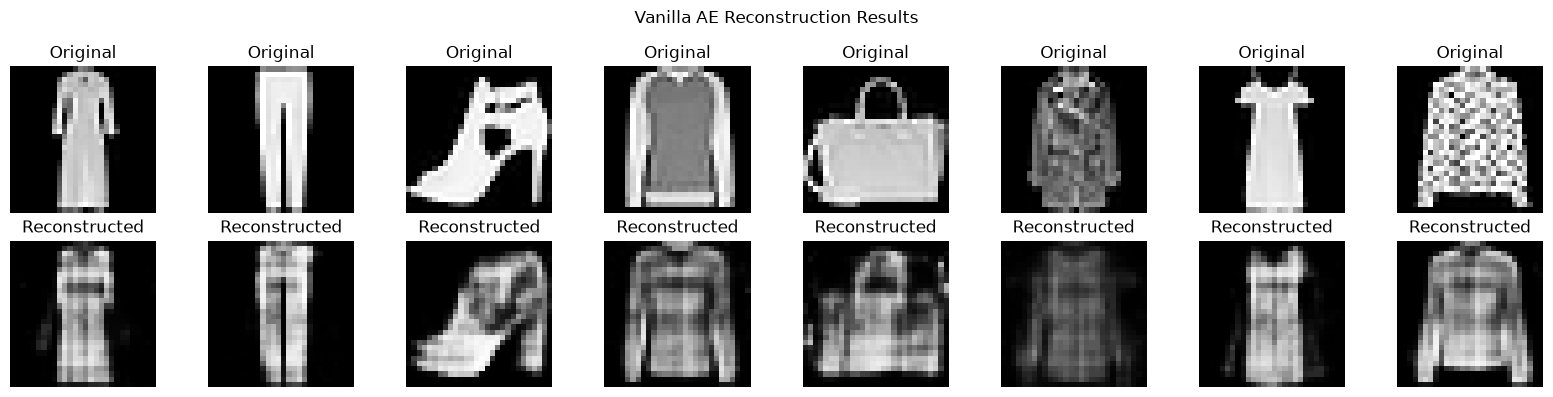

Figure saved: D:\generative-models-comparison\results\vanilla_ae_reconstruction.png


In [50]:
fig, axes = plt.subplots(2, 8, figsize=(16, 4))

for i in range(8):
    axes[0, i].imshow(
        original_images[i].squeeze().cpu().numpy(),
        cmap="gray",
        vmin=0,
        vmax=1
    )
    axes[0, i].set_title("Original")
    axes[0, i].axis("off")

    axes[1, i].imshow(
        reconstructed_images[i].squeeze().cpu().numpy(),
        cmap="gray",
        vmin=0,
        vmax=1
    )
    axes[1, i].set_title("Reconstructed")
    axes[1, i].axis("off")

plt.suptitle("Vanilla AE Reconstruction Results")
plt.tight_layout()

save_path = os.path.join(
    RESULTS_DIR,
    "vanilla_ae_reconstruction.png"
)

plt.savefig(save_path, dpi=150, bbox_inches="tight")
plt.show()

print("Figure saved:", save_path)

Calculate Vanilla AE Metrics

In [51]:
from skimage.metrics import structural_similarity as ssim
from skimage.metrics import peak_signal_noise_ratio as psnr

vanilla_ae.eval()

all_originals = []
all_reconstructions = []

with torch.no_grad():
    for images, _ in test_loader:
        images = images.to(device)

        outputs = vanilla_ae(images.view(-1, 784))
        outputs = outputs.view(-1, 1, 28, 28)

        all_originals.append(images.cpu())
        all_reconstructions.append(outputs.cpu())

all_originals = torch.cat(all_originals)
all_reconstructions = torch.cat(all_reconstructions)

mse_value = torch.mean(
    (all_originals - all_reconstructions) ** 2
).item()

psnr_values = []
ssim_values = []

for original, reconstructed in zip(
    all_originals, all_reconstructions
):
    original_np = original.squeeze().numpy()
    reconstructed_np = reconstructed.squeeze().numpy()

    psnr_values.append(
        psnr(original_np, reconstructed_np, data_range=1.0)
    )

    ssim_values.append(
        ssim(original_np, reconstructed_np, data_range=1.0)
    )

vanilla_ae_metrics = {
    "MSE": mse_value,
    "PSNR": np.mean(psnr_values),
    "SSIM": np.mean(ssim_values)
}

print("Vanilla AE Test Metrics")
print("-----------------------")
for metric, value in vanilla_ae_metrics.items():
    print(f"{metric}: {value:.6f}")

Vanilla AE Test Metrics
-----------------------
MSE: 0.046862
PSNR: 13.907615
SSIM: 0.459856


In [52]:
print("Test Images Range:")
print("Minimum:", test_images.min().item())
print("Maximum:", test_images.max().item())

print("\nEvaluation Originals Range:")
print("Minimum:", all_originals.min().item())
print("Maximum:", all_originals.max().item())

print("\nReconstruction Range:")
print("Minimum:", all_reconstructions.min().item())
print("Maximum:", all_reconstructions.max().item())

print("\nDirect Test MSE:")
print(
    torch.mean(
        (test_images.cpu() - all_reconstructions) ** 2
    ).item()
)

Test Images Range:
Minimum: 0.0
Maximum: 1.0

Evaluation Originals Range:
Minimum: 0.0
Maximum: 1.0

Reconstruction Range:
Minimum: 4.34632902180462e-19
Maximum: 0.9964349269866943

Direct Test MSE:
0.04686224088072777


In [53]:
VANILLA_AE_CHECKPOINT_PATH = os.path.join(
    CHECKPOINT_DIR,
    "vanilla_ae.pth"
)

vanilla_ae_checkpoint = torch.load(
    VANILLA_AE_CHECKPOINT_PATH,
    map_location=device,
    weights_only=False
)

print("Checkpoint Type:", type(vanilla_ae_checkpoint))

if isinstance(vanilla_ae_checkpoint, dict):
    print("Checkpoint Keys:", vanilla_ae_checkpoint.keys())

    for key, value in vanilla_ae_checkpoint.items():
        if not isinstance(value, dict):
            print(f"{key}: {value}")

Checkpoint Type: <class 'collections.OrderedDict'>
Checkpoint Keys: odict_keys(['encoder.0.weight', 'encoder.0.bias', 'encoder.2.weight', 'encoder.2.bias', 'encoder.4.weight', 'encoder.4.bias', 'decoder.0.weight', 'decoder.0.bias', 'decoder.2.weight', 'decoder.2.bias', 'decoder.4.weight', 'decoder.4.bias'])
encoder.0.weight: tensor([[ 0.0273,  0.0296, -0.0084,  ..., -0.0142,  0.0093,  0.0135],
        [-0.0178, -0.0304,  0.0872,  ...,  0.0492,  0.1240, -0.0943],
        [-0.0008,  0.0017,  0.0045,  ..., -0.0127, -0.0188,  0.0059],
        ...,
        [-0.0084, -0.0058,  0.0228,  ...,  0.0292,  0.0206, -0.0119],
        [-0.1250,  0.0615, -0.0670,  ...,  0.1271, -0.0571, -0.1062],
        [-0.0308,  0.0149, -0.0224,  ...,  0.0094, -0.0239, -0.0194]])
encoder.0.bias: tensor([-2.8263e-02, -4.2513e-01, -2.2052e-02,  1.6150e-01,  6.1647e-02,
         2.7156e-01, -1.8772e-02,  4.2999e-03,  5.0292e-01, -3.0238e-02,
         3.9415e-01,  2.5699e-02,  1.5046e-01,  2.7895e-01, -1.1912e-01,
    

In [57]:
class VanillaAE(nn.Module):
    def __init__(self):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Linear(784, 512),
            nn.ReLU(),
            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Linear(256, 64)
        )

        self.decoder = nn.Sequential(
            nn.Linear(64, 256),
            nn.ReLU(),
            nn.Linear(256, 512),
            nn.ReLU(),
            nn.Linear(512, 784),
            nn.Sigmoid()
        )

    def forward(self, x):
        x = x.view(x.size(0), -1)
        latent = self.encoder(x)
        reconstructed = self.decoder(latent)

        return reconstructed

In [58]:
vanilla_ae = VanillaAE().to(device)

vanilla_ae.load_state_dict(vanilla_ae_checkpoint)

vanilla_ae.eval()

print("Vanilla AE Loaded Successfully")
print("Model Device:", next(vanilla_ae.parameters()).device)
print("Total Parameters:", sum(
    p.numel() for p in vanilla_ae.parameters()
))

Vanilla AE Loaded Successfully
Model Device: cpu
Total Parameters: 1100112


Inspect Sparse AE Checkpoint

In [13]:
sparse_ae_path = os.path.join(CHECKPOINT_DIR, "sparse_ae_improved.pth")

sparse_ae_checkpoint = torch.load(
    sparse_ae_path,
    map_location=device,
    weights_only=False
)

print("Checkpoint Type:", type(sparse_ae_checkpoint))

if isinstance(sparse_ae_checkpoint, dict):
    print("\nCheckpoint Keys:")
    for key, value in sparse_ae_checkpoint.items():
        if isinstance(value, dict):
            print(f"{key}: state_dict with {len(value)} parameters")
        elif isinstance(value, torch.Tensor):
            print(f"{key}: Tensor {tuple(value.shape)}")
        else:
            print(f"{key}: {value}")

Checkpoint Type: <class 'collections.OrderedDict'>

Checkpoint Keys:
encoder.0.weight: Tensor (512, 784)
encoder.0.bias: Tensor (512,)
encoder.2.weight: Tensor (256, 512)
encoder.2.bias: Tensor (256,)
encoder.4.weight: Tensor (64, 256)
encoder.4.bias: Tensor (64,)
decoder.0.weight: Tensor (256, 64)
decoder.0.bias: Tensor (256,)
decoder.2.weight: Tensor (512, 256)
decoder.2.bias: Tensor (512,)
decoder.4.weight: Tensor (784, 512)
decoder.4.bias: Tensor (784,)


Load Sparse AE

In [14]:
sparse_ae = Autoencoder().to(device)

sparse_ae.load_state_dict(sparse_ae_checkpoint)
sparse_ae.eval()

print("Sparse AE Loaded Successfully!")
print("Model Device:", next(sparse_ae.parameters()).device)
print("Latent Dimension:", 64)

Sparse AE Loaded Successfully!
Model Device: cpu
Latent Dimension: 64


Inspect VAE Checkpoint

In [15]:
vae_path = os.path.join(CHECKPOINT_DIR, "vae.pth")

vae_checkpoint = torch.load(
    vae_path,
    map_location=device,
    weights_only=False
)

print("Checkpoint Type:", type(vae_checkpoint))

if isinstance(vae_checkpoint, dict):
    print("\nCheckpoint Keys:")
    for key, value in vae_checkpoint.items():
        if isinstance(value, dict):
            print(f"{key}: state_dict with {len(value)} parameters")
        elif isinstance(value, torch.Tensor):
            print(f"{key}: Tensor {tuple(value.shape)}")
        else:
            print(f"{key}: {value}")

Checkpoint Type: <class 'dict'>

Checkpoint Keys:
epoch: 43
model_state_dict: state_dict with 14 parameters
optimizer_state_dict: state_dict with 2 parameters
val_loss: 23.234562604631698


Inspect VAE Architecture

In [16]:
print("VAE Model Parameters:\n")

for key, value in vae_checkpoint["model_state_dict"].items():
    print(f"{key}: {tuple(value.shape)}")

VAE Model Parameters:

encoder.0.weight: (512, 784)
encoder.0.bias: (512,)
encoder.2.weight: (256, 512)
encoder.2.bias: (256,)
fc_mu.weight: (64, 256)
fc_mu.bias: (64,)
fc_logvar.weight: (64, 256)
fc_logvar.bias: (64,)
decoder.0.weight: (256, 64)
decoder.0.bias: (256,)
decoder.2.weight: (512, 256)
decoder.2.bias: (512,)
decoder.4.weight: (784, 512)
decoder.4.bias: (784,)


Define and Load VAE

In [17]:
class VAE(nn.Module):
    def __init__(self):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Linear(784, 512),
            nn.ReLU(),
            nn.Linear(512, 256),
            nn.ReLU()
        )

        self.fc_mu = nn.Linear(256, 64)
        self.fc_logvar = nn.Linear(256, 64)

        self.decoder = nn.Sequential(
            nn.Linear(64, 256),
            nn.ReLU(),
            nn.Linear(256, 512),
            nn.ReLU(),
            nn.Linear(512, 784),
            nn.Sigmoid()
        )

    def encode(self, x):
        x = x.view(x.size(0), -1)
        hidden = self.encoder(x)

        mu = self.fc_mu(hidden)
        logvar = self.fc_logvar(hidden)

        return mu, logvar

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        epsilon = torch.randn_like(std)
        return mu + epsilon * std

    def decode(self, z):
        return self.decoder(z)

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        reconstructed = self.decode(z)

        return reconstructed, mu, logvar


vae = VAE().to(device)

vae.load_state_dict(vae_checkpoint["model_state_dict"])
vae.eval()

print("VAE Loaded Successfully!")
print("Checkpoint Epoch:", vae_checkpoint["epoch"])
print("Validation Loss:", vae_checkpoint["val_loss"])
print("Model Device:", next(vae.parameters()).device)
print("Latent Dimension:", 64)

VAE Loaded Successfully!
Checkpoint Epoch: 43
Validation Loss: 23.234562604631698
Model Device: cpu
Latent Dimension: 64


Inspect Vanilla GAN Checkpoint

In [18]:
vanilla_gan_path = os.path.join(CHECKPOINT_DIR, "vanilla_gan.pth")

vanilla_gan_checkpoint = torch.load(
    vanilla_gan_path,
    map_location=device,
    weights_only=False
)

print("Checkpoint Type:", type(vanilla_gan_checkpoint))

if isinstance(vanilla_gan_checkpoint, dict):
    print("\nCheckpoint Keys:")
    for key, value in vanilla_gan_checkpoint.items():
        if isinstance(value, dict):
            print(f"{key}: state_dict with {len(value)} parameters")
        elif isinstance(value, torch.Tensor):
            print(f"{key}: Tensor {tuple(value.shape)}")
        else:
            print(f"{key}: {value}")

Checkpoint Type: <class 'dict'>

Checkpoint Keys:
epoch: 150
generator_state_dict: state_dict with 8 parameters
discriminator_state_dict: state_dict with 6 parameters
generator_optimizer_state_dict: state_dict with 2 parameters
discriminator_optimizer_state_dict: state_dict with 2 parameters
generator_losses: [2.0706799706639765, 3.4222870258163645, 3.445868515941106, 3.4138752217978645, 2.71079662020348, 2.2413381985877745, 1.9964284473630391, 1.7518326103959454, 1.588305977653695, 1.495782451134294, 1.3685630414311745, 1.317820945559027, 1.251395448702111, 1.2197796816695226, 1.1249299136470987, 1.0818258938996215, 1.0329783323420783, 0.9973603929286678, 0.9814808439446366, 0.9483716419842689, 0.9483992739083016, 0.9170671611616056, 0.8920178056851914, 0.8713882132752301, 0.8607474696146299, 0.8461644743403344, 0.8313077584793579, 0.8400984278552608, 0.8310863602923476, 0.8225314349072165, 0.8179105868622593, 0.8079562057915344, 0.7950654039372048, 0.7977099424083484, 0.7901977047528

Inspect Vanilla GAN Architecture

In [19]:
print("Generator Parameters:\n")

for key, value in vanilla_gan_checkpoint["generator_state_dict"].items():
    print(f"{key}: {tuple(value.shape)}")

print("\nDiscriminator Parameters:\n")

for key, value in vanilla_gan_checkpoint["discriminator_state_dict"].items():
    print(f"{key}: {tuple(value.shape)}")

Generator Parameters:

model.0.weight: (256, 100)
model.0.bias: (256,)
model.2.weight: (512, 256)
model.2.bias: (512,)
model.4.weight: (1024, 512)
model.4.bias: (1024,)
model.6.weight: (784, 1024)
model.6.bias: (784,)

Discriminator Parameters:

model.0.weight: (512, 784)
model.0.bias: (512,)
model.2.weight: (256, 512)
model.2.bias: (256,)
model.4.weight: (1, 256)
model.4.bias: (1,)


Define and Load Vanilla GAN

In [20]:
class Generator(nn.Module):
    def __init__(self, noise_dim=100):
        super().__init__()

        self.model = nn.Sequential(
            nn.Linear(noise_dim, 256),
            nn.ReLU(),
            nn.Linear(256, 512),
            nn.ReLU(),
            nn.Linear(512, 1024),
            nn.ReLU(),
            nn.Linear(1024, 784),
            nn.Tanh()
        )

    def forward(self, z):
        return self.model(z)


class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()

        self.model = nn.Sequential(
            nn.Linear(784, 512),
            nn.LeakyReLU(0.2),
            nn.Linear(512, 256),
            nn.LeakyReLU(0.2),
            nn.Linear(256, 1),
            nn.Sigmoid()
        )

    def forward(self, x):
        x = x.view(x.size(0), -1)
        return self.model(x)


vanilla_generator = Generator().to(device)
vanilla_discriminator = Discriminator().to(device)

vanilla_generator.load_state_dict(
    vanilla_gan_checkpoint["generator_state_dict"]
)

vanilla_discriminator.load_state_dict(
    vanilla_gan_checkpoint["discriminator_state_dict"]
)

vanilla_generator.eval()
vanilla_discriminator.eval()

print("Vanilla GAN Loaded Successfully!")
print("Checkpoint Epoch:", vanilla_gan_checkpoint["epoch"])
print("Generator Device:", next(vanilla_generator.parameters()).device)
print("Discriminator Device:", next(vanilla_discriminator.parameters()).device)

Vanilla GAN Loaded Successfully!
Checkpoint Epoch: 150
Generator Device: cpu
Discriminator Device: cpu


Inspect DCGAN Checkpoint

In [21]:
dcgan_path = os.path.join(CHECKPOINT_DIR, "dcgan.pth")

dcgan_checkpoint = torch.load(
    dcgan_path,
    map_location=device,
    weights_only=False
)

print("Checkpoint Type:", type(dcgan_checkpoint))

if isinstance(dcgan_checkpoint, dict):
    print("\nCheckpoint Keys:")
    for key, value in dcgan_checkpoint.items():
        if isinstance(value, dict):
            print(f"{key}: state_dict with {len(value)} parameters")
        elif isinstance(value, torch.Tensor):
            print(f"{key}: Tensor {tuple(value.shape)}")
        else:
            print(f"{key}: {value}")

Checkpoint Type: <class 'dict'>

Checkpoint Keys:
epoch: 100
generator_state_dict: state_dict with 15 parameters
discriminator_state_dict: state_dict with 8 parameters
generator_optimizer_state_dict: state_dict with 2 parameters
discriminator_optimizer_state_dict: state_dict with 2 parameters
generator_losses: [1.2905535765978844, 1.1105764161234033, 1.025160710969472, 0.9919604868649348, 0.9972395617259692, 0.9890016826320457, 1.000016715700768, 0.9991181905819401, 1.008860687482847, 1.005430036211667, 1.0265600366951668, 1.0237040703427303, 1.030225198971082, 1.0314227137799676, 1.0368482196984226, 1.053067547681669, 1.0496230234294177, 1.0627596942393203, 1.0676522671359858, 1.0754904426532248, 1.0818773957147991, 1.0926071523803553, 1.0956044964594385, 1.0981955611950731, 1.105198581605197, 1.1206625963999257, 1.1234725882473602, 1.132806000916381, 1.1396499861320948, 1.1415999974017819, 1.152328076019679, 1.1635310249785855, 1.1625991998469993, 1.1835837632281596, 1.17867403650937

Inspect DCGAN Architecture

In [22]:
print("Generator Parameters:\n")

for key, value in dcgan_checkpoint["generator_state_dict"].items():
    print(f"{key}: {tuple(value.shape)}")

print("\nDiscriminator Parameters:\n")

for key, value in dcgan_checkpoint["discriminator_state_dict"].items():
    print(f"{key}: {tuple(value.shape)}")

Generator Parameters:

project.weight: (128, 100)
project.bias: (128,)
model.0.weight: (128, 64, 7, 7)
model.1.weight: (64,)
model.1.bias: (64,)
model.1.running_mean: (64,)
model.1.running_var: (64,)
model.1.num_batches_tracked: ()
model.3.weight: (64, 64, 4, 4)
model.4.weight: (64,)
model.4.bias: (64,)
model.4.running_mean: (64,)
model.4.running_var: (64,)
model.4.num_batches_tracked: ()
model.6.weight: (64, 1, 4, 4)

Discriminator Parameters:

model.0.weight: (64, 1, 4, 4)
model.2.weight: (128, 64, 4, 4)
model.3.weight: (128,)
model.3.bias: (128,)
model.3.running_mean: (128,)
model.3.running_var: (128,)
model.3.num_batches_tracked: ()
model.5.weight: (1, 128, 7, 7)


Define and Load DCGAN

In [23]:
class DCGANGenerator(nn.Module):
    def __init__(self, noise_dim=100):
        super().__init__()

        self.project = nn.Linear(noise_dim, 128)

        self.model = nn.Sequential(
            nn.ConvTranspose2d(128, 64, kernel_size=7, stride=1, padding=0, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(True),

            nn.ConvTranspose2d(64, 64, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(True),

            nn.ConvTranspose2d(64, 1, kernel_size=4, stride=2, padding=1, bias=False),
            nn.Tanh()
        )

    def forward(self, z):
        x = self.project(z)
        x = x.view(-1, 128, 1, 1)
        return self.model(x)


class DCGANDiscriminator(nn.Module):
    def __init__(self):
        super().__init__()

        self.model = nn.Sequential(
            nn.Conv2d(1, 64, kernel_size=4, stride=2, padding=1, bias=False),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(64, 128, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(128, 1, kernel_size=7, stride=1, padding=0, bias=False),
            nn.Sigmoid()
        )

    def forward(self, x):
        return self.model(x)


dcgan_generator = DCGANGenerator().to(device)
dcgan_discriminator = DCGANDiscriminator().to(device)

dcgan_generator.load_state_dict(
    dcgan_checkpoint["generator_state_dict"]
)

dcgan_discriminator.load_state_dict(
    dcgan_checkpoint["discriminator_state_dict"]
)

dcgan_generator.eval()
dcgan_discriminator.eval()

print("DCGAN Loaded Successfully!")
print("Checkpoint Epoch:", dcgan_checkpoint["epoch"])
print("Generator Device:", next(dcgan_generator.parameters()).device)
print("Discriminator Device:", next(dcgan_discriminator.parameters()).device)

DCGAN Loaded Successfully!
Checkpoint Epoch: 100
Generator Device: cpu
Discriminator Device: cpu


Inspect DDPM Checkpoint

In [24]:
ddpm_path = os.path.join(CHECKPOINT_DIR, "ddpm_finetuned.pth")

ddpm_checkpoint = torch.load(
    ddpm_path,
    map_location=device,
    weights_only=False
)

print("Checkpoint Type:", type(ddpm_checkpoint))

if isinstance(ddpm_checkpoint, dict):
    print("\nCheckpoint Keys:")
    for key, value in ddpm_checkpoint.items():
        if isinstance(value, dict):
            print(f"{key}: state_dict with {len(value)} parameters")
        elif isinstance(value, torch.Tensor):
            print(f"{key}: Tensor {tuple(value.shape)}")
        else:
            print(f"{key}: {value}")

Checkpoint Type: <class 'dict'>

Checkpoint Keys:
epoch: 10
model_state_dict: state_dict with 76 parameters
optimizer_state_dict: state_dict with 2 parameters
train_losses: [0.03723990853416593, 0.03454895881025895, 0.0344331766261834, 0.03440593022717053, 0.03402685009147206, 0.03443731778815865, 0.03461334818217172, 0.033976892685543186, 0.03397891898405606, 0.03440044571105476]
val_losses: [0.03493152264166962, 0.03426710086112673, 0.034191024574366485, 0.03484533435919068, 0.0357867455617948, 0.03629101904278452, 0.034531745450063184, 0.03357271921228279, 0.03607280775904655, 0.036420574581081215]
beta_start: 0.0001
beta_end: 0.02
timesteps: 1000


Inspect DDPM Architecture

In [25]:
print("DDPM Model Parameters:\n")

for key, value in ddpm_checkpoint["model_state_dict"].items():
    print(f"{key}: {tuple(value.shape)}")

DDPM Model Parameters:

time_embedding.1.weight: (256, 64)
time_embedding.1.bias: (256,)
time_embedding.3.weight: (256, 256)
time_embedding.3.bias: (256,)
input_conv.weight: (64, 1, 3, 3)
input_conv.bias: (64,)
down1.conv1.0.weight: (64, 64, 3, 3)
down1.conv1.0.bias: (64,)
down1.conv1.1.weight: (64,)
down1.conv1.1.bias: (64,)
down1.time_mlp.1.weight: (64, 256)
down1.time_mlp.1.bias: (64,)
down1.conv2.0.weight: (64, 64, 3, 3)
down1.conv2.0.bias: (64,)
down1.conv2.1.weight: (64,)
down1.conv2.1.bias: (64,)
downsample1.conv.weight: (64, 64, 4, 4)
downsample1.conv.bias: (64,)
down2.conv1.0.weight: (128, 64, 3, 3)
down2.conv1.0.bias: (128,)
down2.conv1.1.weight: (128,)
down2.conv1.1.bias: (128,)
down2.time_mlp.1.weight: (128, 256)
down2.time_mlp.1.bias: (128,)
down2.conv2.0.weight: (128, 128, 3, 3)
down2.conv2.0.bias: (128,)
down2.conv2.1.weight: (128,)
down2.conv2.1.bias: (128,)
down2.shortcut.weight: (128, 64, 1, 1)
down2.shortcut.bias: (128,)
downsample2.conv.weight: (128, 128, 4, 4)
down

In [26]:

DDPM_CONFIG = {
    "channels": [64, 128, 256],
    "timesteps": 1000
}

TIMESTEPS = DDPM_CONFIG["timesteps"]
BETA_START = 0.0001
BETA_END = 0.02

print("DDPM Configuration")
print("Channels:", DDPM_CONFIG["channels"])
print("Timesteps:", TIMESTEPS)
print("Beta Start:", BETA_START)
print("Beta End:", BETA_END)
print("Device:", device)


DDPM Configuration
Channels: [64, 128, 256]
Timesteps: 1000
Beta Start: 0.0001
Beta End: 0.02
Device: cpu


In [30]:
class SinusoidalTimeEmbedding(nn.Module):
    def __init__(self, embedding_dim):
        super().__init__()
        self.embedding_dim = embedding_dim

    def forward(self, timesteps):
        half_dim = self.embedding_dim // 2

        embeddings = torch.log(
            torch.tensor(10000.0, device=timesteps.device)
        ) / (half_dim - 1)

        embeddings = torch.exp(
            torch.arange(half_dim, device=timesteps.device) * -embeddings
        )

        embeddings = timesteps.float().unsqueeze(1) * embeddings.unsqueeze(0)

        embeddings = torch.cat(
            [torch.sin(embeddings), torch.cos(embeddings)],
            dim=1
        )

        return embeddings

In [32]:
class ResidualBlock(nn.Module):
    def __init__(self, in_channels, out_channels, time_dim):
        super().__init__()

        self.conv1 = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
            nn.GroupNorm(8, out_channels),
            nn.SiLU()
        )

        self.time_mlp = nn.Sequential(
            nn.SiLU(),
            nn.Linear(time_dim, out_channels)
        )

        self.conv2 = nn.Sequential(
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1),
            nn.GroupNorm(8, out_channels)
        )

        self.shortcut = (
            nn.Conv2d(in_channels, out_channels, kernel_size=1)
            if in_channels != out_channels
            else nn.Identity()
        )

        self.activation = nn.SiLU()

    def forward(self, x, time_embedding):
        residual = self.shortcut(x)
        x = self.conv1(x)

        time_features = self.time_mlp(time_embedding)
        x = x + time_features[:, :, None, None]

        x = self.conv2(x)

        return self.activation(x + residual)

In [35]:
class DownsampleBlock(nn.Module):
    def __init__(self, channels):
        super().__init__()

        self.conv = nn.Conv2d(
            channels,
            channels,
            kernel_size=4,
            stride=2,
            padding=1
        )

    def forward(self, x):
        return self.conv(x)

In [37]:
class UpsampleBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.conv = nn.ConvTranspose2d(
            in_channels,
            out_channels,
            kernel_size=4,
            stride=2,
            padding=1
        )

    def forward(self, x):
        return self.conv(x)
    

In [38]:
print("SinusoidalTimeEmbedding:", SinusoidalTimeEmbedding)
print("ResidualBlock:", ResidualBlock)
print("DownsampleBlock:", DownsampleBlock)
print("UpsampleBlock:", UpsampleBlock)


SinusoidalTimeEmbedding: <class '__main__.SinusoidalTimeEmbedding'>
ResidualBlock: <class '__main__.ResidualBlock'>
DownsampleBlock: <class '__main__.DownsampleBlock'>
UpsampleBlock: <class '__main__.UpsampleBlock'>


In [39]:

class UNet(nn.Module):
    def __init__(self, config):
        super().__init__()

        channels = config["channels"]
        time_dim = channels[0] * 4

        self.time_embedding = nn.Sequential(
            SinusoidalTimeEmbedding(channels[0]),
            nn.Linear(channels[0], time_dim),
            nn.SiLU(),
            nn.Linear(time_dim, time_dim)
        )

        self.input_conv = nn.Conv2d(
            1, channels[0], kernel_size=3, padding=1
        )

        self.down1 = ResidualBlock(channels[0], channels[0], time_dim)
        self.downsample1 = DownsampleBlock(channels[0])

        self.down2 = ResidualBlock(channels[0], channels[1], time_dim)
        self.downsample2 = DownsampleBlock(channels[1])

        self.middle = ResidualBlock(channels[1], channels[2], time_dim)

        self.upsample1 = UpsampleBlock(channels[2], channels[1])
        self.up1 = ResidualBlock(channels[1] * 2, channels[1], time_dim)

        self.upsample2 = UpsampleBlock(channels[1], channels[0])
        self.up2 = ResidualBlock(channels[0] * 2, channels[0], time_dim)

        self.output = nn.Sequential(
            nn.Conv2d(channels[0], channels[0], kernel_size=3, padding=1),
            nn.SiLU(),
            nn.Conv2d(channels[0], 1, kernel_size=1)
        )

    def forward(self, x, timesteps):
        time_embedding = self.time_embedding(timesteps)

        x = self.input_conv(x)

        skip1 = self.down1(x, time_embedding)
        x = self.downsample1(skip1)

        skip2 = self.down2(x, time_embedding)
        x = self.downsample2(skip2)

        x = self.middle(x, time_embedding)

        x = self.upsample1(x)
        x = torch.cat([x, skip2], dim=1)
        x = self.up1(x, time_embedding)

        x = self.upsample2(x)
        x = torch.cat([x, skip1], dim=1)
        x = self.up2(x, time_embedding)

        return self.output(x)


DDPM_CONFIG = {
    "channels": [64, 128, 256]
}

unet = UNet(DDPM_CONFIG).to(device)

print("DDPM U-Net Architecture Created")
print("Model Device:", next(unet.parameters()).device)


DDPM U-Net Architecture Created
Model Device: cpu


In [40]:
DDPM_CHECKPOINT_PATH = os.path.join(
    CHECKPOINT_DIR,
    "ddpm_finetuned.pth"
)

checkpoint = torch.load(
    DDPM_CHECKPOINT_PATH,
    map_location=device,
    weights_only=False
)

unet.load_state_dict(checkpoint["model_state_dict"])
unet.eval()

print("DDPM Checkpoint Loaded Successfully")
print("Checkpoint Epoch:", checkpoint["epoch"])
print("Beta Start:", checkpoint["beta_start"])
print("Beta End:", checkpoint["beta_end"])
print("Timesteps:", checkpoint["timesteps"])

DDPM Checkpoint Loaded Successfully
Checkpoint Epoch: 10
Beta Start: 0.0001
Beta End: 0.02
Timesteps: 1000


In [41]:
TIMESTEPS = checkpoint["timesteps"]
BETA_START = checkpoint["beta_start"]
BETA_END = checkpoint["beta_end"]

betas = torch.linspace(
    BETA_START,
    BETA_END,
    TIMESTEPS
).to(device)

alphas = 1.0 - betas
alpha_bars = torch.cumprod(alphas, dim=0)

print("DDPM Noise Schedule Created")
print("Betas Shape:", betas.shape)
print("Alpha Bars Shape:", alpha_bars.shape)
print("Alpha Bar Min:", alpha_bars.min().item())
print("Alpha Bar Max:", alpha_bars.max().item())

DDPM Noise Schedule Created
Betas Shape: torch.Size([1000])
Alpha Bars Shape: torch.Size([1000])
Alpha Bar Min: 4.0358307160204276e-05
Alpha Bar Max: 0.9998999834060669


forward diffusion

In [42]:
@torch.no_grad()
def forward_diffusion(images, timesteps):
    noise = torch.randn_like(images)

    alpha_bar_t = alpha_bars[timesteps].view(-1, 1, 1, 1)

    noisy_images = (
        torch.sqrt(alpha_bar_t) * images
        + torch.sqrt(1 - alpha_bar_t) * noise
    )

    return noisy_images

In [43]:
sample_images = test_images[:8].to(device)

timesteps_to_show = torch.tensor(
    [0, 100, 250, 500, 750, 999, 999, 999],
    device=device
)

noisy_images = forward_diffusion(
    sample_images,
    timesteps_to_show
)

print("Original Images Shape:", sample_images.shape)
print("Noisy Images Shape:", noisy_images.shape)
print("Noisy Pixel Minimum:", noisy_images.min().item())
print("Noisy Pixel Maximum:", noisy_images.max().item())

Original Images Shape: torch.Size([8, 1, 28, 28])
Noisy Images Shape: torch.Size([8, 1, 28, 28])
Noisy Pixel Minimum: -3.294658660888672
Noisy Pixel Maximum: 3.120501756668091


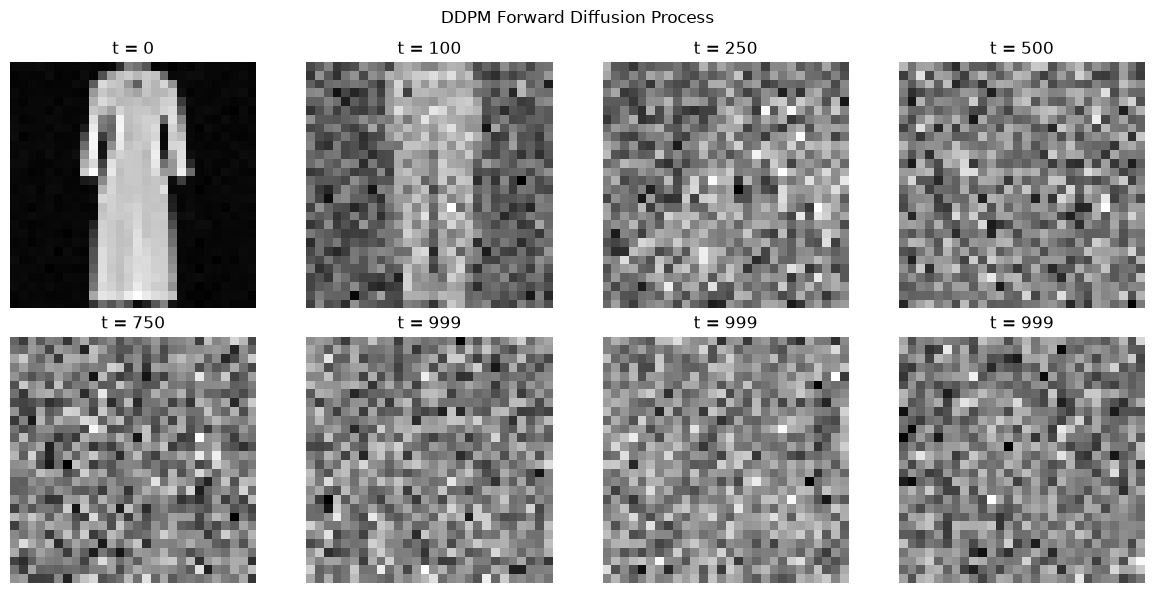

Figure saved: D:\generative-models-comparison\results\ddpm_forward_diffusion_evaluation.png


In [44]:
fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for i, ax in enumerate(axes.flat):
    image = noisy_images[i].squeeze().cpu().numpy()

    ax.imshow(image, cmap="gray")
    ax.set_title(f"t = {timesteps_to_show[i].item()}")
    ax.axis("off")

plt.suptitle("DDPM Forward Diffusion Process")
plt.tight_layout()

save_path = os.path.join(
    RESULTS_DIR,
    "ddpm_forward_diffusion_evaluation.png"
)

plt.savefig(save_path, dpi=150, bbox_inches="tight")
plt.show()

print("Figure saved:", save_path)

In [45]:
@torch.no_grad()
def reverse_diffusion(model, num_samples=10):
    model.eval()

    images = torch.randn(
        num_samples, 1, 28, 28, device=device
    )

    for t in reversed(range(TIMESTEPS)):
        timesteps = torch.full(
            (num_samples,), t, device=device, dtype=torch.long
        )

        predicted_noise = model(images, timesteps)

        alpha = alphas[t]
        alpha_bar = alpha_bars[t]
        beta = betas[t]

        noise = torch.randn_like(images) if t > 0 else torch.zeros_like(images)

        images = (1 / torch.sqrt(alpha)) * (
            images - (beta / torch.sqrt(1 - alpha_bar)) * predicted_noise
        ) + torch.sqrt(beta) * noise

    return images.clamp(-1, 1)

In [46]:
generated_ddpm = reverse_diffusion(
    unet,
    num_samples=16
)

print("Generated Images Shape:", generated_ddpm.shape)
print("Pixel Minimum:", generated_ddpm.min().item())
print("Pixel Maximum:", generated_ddpm.max().item())

Generated Images Shape: torch.Size([16, 1, 28, 28])
Pixel Minimum: -1.0
Pixel Maximum: 1.0


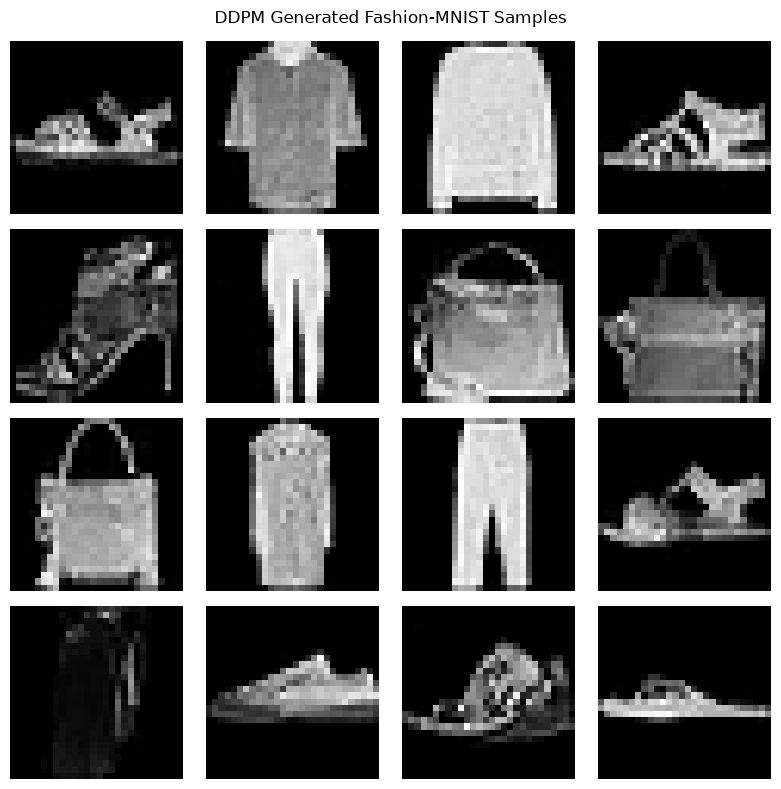

Figure saved: D:\generative-models-comparison\results\ddpm_generated_samples_evaluation.png


In [47]:
fig, axes = plt.subplots(4, 4, figsize=(8, 8))

for i, ax in enumerate(axes.flat):
    image = generated_ddpm[i].squeeze().cpu().numpy()

    # Convert pixel range from [-1, 1] to [0, 1]
    image = (image + 1) / 2

    ax.imshow(image, cmap="gray", vmin=0, vmax=1)
    ax.axis("off")

plt.suptitle("DDPM Generated Fashion-MNIST Samples")
plt.tight_layout()

save_path = os.path.join(
    RESULTS_DIR,
    "ddpm_generated_samples_evaluation.png"
)

plt.savefig(save_path, dpi=150, bbox_inches="tight")
plt.show()

print("Figure saved:", save_path)

Load checkpoint MLP Classifier

In [59]:
MLP_CHECKPOINT_PATH = os.path.join(
    CHECKPOINT_DIR,
    "mlp_classifier.pth"
)

mlp_checkpoint = torch.load(
    MLP_CHECKPOINT_PATH,
    map_location=device,
    weights_only=False
)

print("Checkpoint Type:", type(mlp_checkpoint))

if isinstance(mlp_checkpoint, dict):
    print("Checkpoint Keys:", mlp_checkpoint.keys())

Checkpoint Type: <class 'dict'>
Checkpoint Keys: dict_keys(['model_state_dict', 'architecture', 'best_val_loss', 'test_accuracy', 'epoch'])


In [60]:
class MLPClassifier(nn.Module):
    def __init__(self):
        super().__init__()

        self.layers = nn.Sequential(
            nn.Linear(784, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, 64),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(64, 10)
        )

    def forward(self, x):
        x = x.view(x.size(0), -1)
        return self.layers(x)

    def extract_features(self, x):
        x = x.view(x.size(0), -1)

        x = self.layers[0](x)
        x = self.layers[1](x)
        x = self.layers[2](x)

        x = self.layers[3](x)
        x = self.layers[4](x)

        return x

In [61]:
mlp_classifier = MLPClassifier().to(device)

mlp_classifier.load_state_dict(
    mlp_checkpoint["model_state_dict"]
)

mlp_classifier.eval()

print("MLP Classifier Loaded Successfully")
print("Model Device:", next(mlp_classifier.parameters()).device)
print("Test Accuracy:", mlp_checkpoint["test_accuracy"])
print("Best Validation Loss:", mlp_checkpoint["best_val_loss"])
print("Total Parameters:", sum(
    p.numel() for p in mlp_classifier.parameters()
))

MLP Classifier Loaded Successfully
Model Device: cpu
Test Accuracy: 0.895
Best Validation Loss: 0.30112279312951223
Total Parameters: 218058


In [62]:
MLP_DECODER_CHECKPOINT_PATH = os.path.join(
    CHECKPOINT_DIR,
    "mlp_frozen_decoder.pth"
)

mlp_decoder_checkpoint = torch.load(
    MLP_DECODER_CHECKPOINT_PATH,
    map_location=device,
    weights_only=False
)

print("Checkpoint Type:", type(mlp_decoder_checkpoint))
print("Checkpoint Keys:", mlp_decoder_checkpoint.keys())

Checkpoint Type: <class 'dict'>
Checkpoint Keys: dict_keys(['decoder_state_dict', 'latent_mean', 'latent_std', 'test_mse', 'test_psnr', 'test_ssim', 'architecture'])


In [63]:
class FrozenLatentDecoder(nn.Module):
    def __init__(self):
        super().__init__()

        self.decoder = nn.Sequential(
            nn.Linear(64, 256),
            nn.ReLU(),
            nn.Linear(256, 784),
            nn.Sigmoid()
        )

    def forward(self, z):
        return self.decoder(z)

In [64]:
mlp_frozen_decoder = FrozenLatentDecoder().to(device)

mlp_frozen_decoder.load_state_dict(
    mlp_decoder_checkpoint["decoder_state_dict"]
)

mlp_frozen_decoder.eval()

latent_mean = mlp_decoder_checkpoint["latent_mean"].to(device)
latent_std = mlp_decoder_checkpoint["latent_std"].to(device)

print("MLP Frozen Latent Decoder Loaded Successfully")
print("Model Device:", next(mlp_frozen_decoder.parameters()).device)
print("Latent Mean Shape:", latent_mean.shape)
print("Latent Std Shape:", latent_std.shape)

print("\nSaved Evaluation Metrics:")
print("Test MSE:", mlp_decoder_checkpoint["test_mse"])
print("Test PSNR:", mlp_decoder_checkpoint["test_psnr"])
print("Test SSIM:", mlp_decoder_checkpoint["test_ssim"])

MLP Frozen Latent Decoder Loaded Successfully
Model Device: cpu
Latent Mean Shape: torch.Size([64])
Latent Std Shape: torch.Size([64])

Saved Evaluation Metrics:
Test MSE: 0.020743269473314285
Test PSNR: 17.671941461091258
Test SSIM: 0.6311013196810505


In [68]:
loaded_models = {
    "Vanilla AE": vanilla_ae,
    "Sparse AE": sparse_ae,
    "VAE": vae,
    "Vanilla GAN Generator": vanilla_generator,
    "Vanilla GAN Discriminator": vanilla_discriminator,
    "DCGAN Generator": dcgan_generator,
    "DCGAN Discriminator": dcgan_discriminator,
    "DDPM": unet,
    "MLP Classifier": mlp_classifier,
    "MLP Frozen Decoder": mlp_frozen_decoder
}

print("MODEL LOADING VERIFICATION")
print("=" * 45)

for model_name, model in loaded_models.items():
    print(f"{model_name}: Loaded")

MODEL LOADING VERIFICATION
Vanilla AE: Loaded
Sparse AE: Loaded
VAE: Loaded
Vanilla GAN Generator: Loaded
Vanilla GAN Discriminator: Loaded
DCGAN Generator: Loaded
DCGAN Discriminator: Loaded
DDPM: Loaded
MLP Classifier: Loaded
MLP Frozen Decoder: Loaded


## Evaluation & Visualization

Reconstruction Evaluation

In [69]:
@torch.no_grad()
def reconstruct_autoencoder(model, images):
    model.eval()

    images = images.to(device)
    reconstructed = model(images)

    return reconstructed.view(-1, 1, 28, 28)

In [70]:
with torch.no_grad():
    sample_images = test_images[:8].to(device)

    vanilla_output = vanilla_ae(sample_images)
    sparse_output = sparse_ae(sample_images)

print("Original Shape:", sample_images.shape)
print("Vanilla AE Output Shape:", vanilla_output.shape if isinstance(vanilla_output, torch.Tensor) else type(vanilla_output))
print("Sparse AE Output Type:", type(sparse_output))

if isinstance(sparse_output, (tuple, list)):
    for i, output in enumerate(sparse_output):
        if isinstance(output, torch.Tensor):
            print(f"Sparse AE Output {i} Shape:", output.shape)
else:
    print("Sparse AE Output Shape:", sparse_output.shape)

Original Shape: torch.Size([8, 1, 28, 28])
Vanilla AE Output Shape: torch.Size([8, 784])
Sparse AE Output Type: <class 'torch.Tensor'>
Sparse AE Output Shape: torch.Size([8, 784])


In [71]:
with torch.no_grad():
    vae_output = vae(sample_images)

print("VAE Output Type:", type(vae_output))

if isinstance(vae_output, (tuple, list)):
    for i, output in enumerate(vae_output):
        if isinstance(output, torch.Tensor):
            print(f"VAE Output {i} Shape:", output.shape)
else:
    print("VAE Output Shape:", vae_output.shape)

VAE Output Type: <class 'tuple'>
VAE Output 0 Shape: torch.Size([8, 784])
VAE Output 1 Shape: torch.Size([8, 64])
VAE Output 2 Shape: torch.Size([8, 64])


In [72]:
@torch.no_grad()
def get_reconstruction(model, images, model_type):
    model.eval()

    images = images.to(device)
    output = model(images)

    if model_type == "vae":
        output = output[0]

    return output.view(-1, 1, 28, 28)

In [73]:
from skimage.metrics import structural_similarity

@torch.no_grad()
def evaluate_reconstruction(model, model_type, images, batch_size=128):
    model.eval()

    all_originals = []
    all_reconstructions = []

    for start in range(0, len(images), batch_size):
        batch = images[start:start + batch_size].to(device)

        reconstructed = get_reconstruction(
            model, batch, model_type
        )

        all_originals.append(batch.cpu())
        all_reconstructions.append(reconstructed.cpu())

    originals = torch.cat(all_originals)
    reconstructions = torch.cat(all_reconstructions)

    mse_values = []
    psnr_values = []
    ssim_values = []

    for original, reconstructed in zip(originals, reconstructions):
        mse = torch.mean((original - reconstructed) ** 2).item()

        psnr = 10 * np.log10(1.0 / max(mse, 1e-10))

        ssim = structural_similarity(
            original.squeeze().numpy(),
            reconstructed.squeeze().numpy(),
            data_range=1.0
        )

        mse_values.append(mse)
        psnr_values.append(psnr)
        ssim_values.append(ssim)

    return {
        "MSE": np.mean(mse_values),
        "PSNR": np.mean(psnr_values),
        "SSIM": np.mean(ssim_values)
    }

In [74]:
reconstruction_results = {}

models_to_evaluate = {
    "Vanilla AE": (vanilla_ae, "ae"),
    "Sparse AE": (sparse_ae, "ae"),
    "VAE": (vae, "vae")
}

for model_name, (model, model_type) in models_to_evaluate.items():
    print(f"Evaluating {model_name}...")

    metrics = evaluate_reconstruction(
        model=model,
        model_type=model_type,
        images=test_images
    )

    reconstruction_results[model_name] = metrics

    print(
        f"MSE: {metrics['MSE']:.6f} | "
        f"PSNR: {metrics['PSNR']:.4f} dB | "
        f"SSIM: {metrics['SSIM']:.4f}"
    )

    print("-" * 55)

Evaluating Vanilla AE...
MSE: 0.006143 | PSNR: 23.3536 dB | SSIM: 0.8367
-------------------------------------------------------
Evaluating Sparse AE...
MSE: 0.078079 | PSNR: 12.8922 dB | SSIM: 0.4051
-------------------------------------------------------
Evaluating VAE...
MSE: 0.019956 | PSNR: 17.6005 dB | SSIM: 0.6273
-------------------------------------------------------


In [75]:
with torch.no_grad():
    sample = test_images[:8].to(device)
    sparse_reconstructed = sparse_ae(sample)

print("Original Range:")
print("Min:", sample.min().item())
print("Max:", sample.max().item())

print("\nSparse AE Reconstruction Range:")
print("Min:", sparse_reconstructed.min().item())
print("Max:", sparse_reconstructed.max().item())

print("\nSparse AE MSE (First 8 Samples):")
print(torch.mean(
    (sample.view(8, -1) - sparse_reconstructed) ** 2
).item())

Original Range:
Min: 0.0
Max: 1.0

Sparse AE Reconstruction Range:
Min: 2.4194663633680946e-11
Max: 0.95401531457901

Sparse AE MSE (First 8 Samples):
0.10076881945133209


In [77]:
print("Sparse AE Architecture:")
print(sparse_ae)

print("\nSparse AE State Dict:")
for key, value in sparse_ae.state_dict().items():
    print(key, value.shape)

Sparse AE Architecture:
Autoencoder(
  (encoder): Sequential(
    (0): Linear(in_features=784, out_features=512, bias=True)
    (1): ReLU()
    (2): Linear(in_features=512, out_features=256, bias=True)
    (3): ReLU()
    (4): Linear(in_features=256, out_features=64, bias=True)
    (5): ReLU()
  )
  (decoder): Sequential(
    (0): Linear(in_features=64, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=512, bias=True)
    (3): ReLU()
    (4): Linear(in_features=512, out_features=784, bias=True)
    (5): Sigmoid()
  )
)

Sparse AE State Dict:
encoder.0.weight torch.Size([512, 784])
encoder.0.bias torch.Size([512])
encoder.2.weight torch.Size([256, 512])
encoder.2.bias torch.Size([256])
encoder.4.weight torch.Size([64, 256])
encoder.4.bias torch.Size([64])
decoder.0.weight torch.Size([256, 64])
decoder.0.bias torch.Size([256])
decoder.2.weight torch.Size([512, 256])
decoder.2.bias torch.Size([512])
decoder.4.weight torch.Size([784, 512])
decoder.4

In [78]:
print("SPARSE AE CHECKPOINT INFORMATION")
print("=" * 45)

print("Checkpoint Type:", type(sparse_ae_checkpoint))

if isinstance(sparse_ae_checkpoint, dict):
    print("Checkpoint Keys:", sparse_ae_checkpoint.keys())

    for key, value in sparse_ae_checkpoint.items():
        if isinstance(value, (int, float, str)):
            print(f"{key}: {value}")
        elif isinstance(value, torch.Tensor):
            print(f"{key}: Tensor {value.shape}")

SPARSE AE CHECKPOINT INFORMATION
Checkpoint Type: <class 'collections.OrderedDict'>
Checkpoint Keys: odict_keys(['encoder.0.weight', 'encoder.0.bias', 'encoder.2.weight', 'encoder.2.bias', 'encoder.4.weight', 'encoder.4.bias', 'decoder.0.weight', 'decoder.0.bias', 'decoder.2.weight', 'decoder.2.bias', 'decoder.4.weight', 'decoder.4.bias'])
encoder.0.weight: Tensor torch.Size([512, 784])
encoder.0.bias: Tensor torch.Size([512])
encoder.2.weight: Tensor torch.Size([256, 512])
encoder.2.bias: Tensor torch.Size([256])
encoder.4.weight: Tensor torch.Size([64, 256])
encoder.4.bias: Tensor torch.Size([64])
decoder.0.weight: Tensor torch.Size([256, 64])
decoder.0.bias: Tensor torch.Size([256])
decoder.2.weight: Tensor torch.Size([512, 256])
decoder.2.bias: Tensor torch.Size([512])
decoder.4.weight: Tensor torch.Size([784, 512])
decoder.4.bias: Tensor torch.Size([784])


In [79]:
print("CHECKPOINT WEIGHT VERIFICATION")
print("=" * 45)

checkpoint_matches = True

for key, checkpoint_weight in sparse_ae_checkpoint.items():
    model_weight = sparse_ae.state_dict()[key]

    is_equal = torch.equal(
        checkpoint_weight.cpu(),
        model_weight.cpu()
    )

    print(f"{key}: {is_equal}")

    if not is_equal:
        checkpoint_matches = False

print("\nAll Weights Match:", checkpoint_matches)

CHECKPOINT WEIGHT VERIFICATION
encoder.0.weight: True
encoder.0.bias: True
encoder.2.weight: True
encoder.2.bias: True
encoder.4.weight: True
encoder.4.bias: True
decoder.0.weight: True
decoder.0.bias: True
decoder.2.weight: True
decoder.2.bias: True
decoder.4.weight: True
decoder.4.bias: True

All Weights Match: True


In [80]:
with torch.no_grad():
    sample = test_images[:8].to(device)

    sample_flat = sample.view(sample.size(0), -1)
    sparse_latent = sparse_ae.encoder(sample_flat)
    sparse_reconstructed = sparse_ae.decoder(sparse_latent)

    vanilla_latent = vanilla_ae.encoder(sample_flat)
    vanilla_reconstructed = vanilla_ae.decoder(vanilla_latent)

print("Sparse AE Latent:")
print("Min:", sparse_latent.min().item())
print("Max:", sparse_latent.max().item())
print("Mean:", sparse_latent.mean().item())
print("Zero Ratio:", (sparse_latent == 0).float().mean().item())

print("\nSparse AE MSE:", torch.mean(
    (sample_flat - sparse_reconstructed) ** 2
).item())

print("\nVanilla AE MSE:", torch.mean(
    (sample_flat - vanilla_reconstructed) ** 2
).item())

Sparse AE Latent:
Min: 0.0
Max: 2.172579765319824
Mean: 0.08671670407056808
Zero Ratio: 0.482421875

Sparse AE MSE: 0.10076881945133209

Vanilla AE MSE: 0.008963719941675663


In [82]:
with torch.no_grad():
    sample = test_images[:8].to(device)
    sample_flat = sample.view(sample.size(0), -1)

    # Encoder tanpa ReLU setelah latent layer
    x = sparse_ae.encoder[0](sample_flat)
    x = sparse_ae.encoder[1](x)
    x = sparse_ae.encoder[2](x)
    x = sparse_ae.encoder[3](x)
    latent_without_relu = sparse_ae.encoder[4](x)

    # Decode latent representation
    reconstructed_without_relu = sparse_ae.decoder(
        latent_without_relu
    )

    mse_without_relu = torch.mean(
        (sample_flat - reconstructed_without_relu) ** 2
    )

print("Latent Without ReLU:")
print("Min:", latent_without_relu.min().item())
print("Max:", latent_without_relu.max().item())
print("Mean:", latent_without_relu.mean().item())

print("\nMSE Without ReLU:", mse_without_relu.item())

Latent Without ReLU:
Min: -1.115185260772705
Max: 2.172579765319824
Mean: 0.00048160343430936337

MSE Without ReLU: 0.008829906582832336


In [83]:
class SparseAutoencoder(nn.Module):
    def __init__(self):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Linear(784, 512),
            nn.ReLU(),
            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Linear(256, 64)
        )

        self.decoder = nn.Sequential(
            nn.Linear(64, 256),
            nn.ReLU(),
            nn.Linear(256, 512),
            nn.ReLU(),
            nn.Linear(512, 784),
            nn.Sigmoid()
        )

    def forward(self, x):
        x = x.view(x.size(0), -1)
        latent = self.encoder(x)
        reconstructed = self.decoder(latent)
        return reconstructed

In [84]:
sparse_ae = SparseAutoencoder().to(device)

sparse_ae.load_state_dict(sparse_ae_checkpoint)

sparse_ae.eval()

print("Sparse AE Loaded Successfully")
print("Latent Dimension: 64")
print("Latent Activation: Linear")

Sparse AE Loaded Successfully
Latent Dimension: 64
Latent Activation: Linear


In [85]:
with torch.no_grad():
    sample = test_images[:8].to(device)

    sparse_reconstructed = sparse_ae(sample)

    sparse_mse = torch.mean(
        (sample.view(8, -1) - sparse_reconstructed) ** 2
    )

print("Sparse AE Reconstruction Shape:", sparse_reconstructed.shape)
print("Sparse AE MSE (First 8 Samples):", sparse_mse.item())

Sparse AE Reconstruction Shape: torch.Size([8, 784])
Sparse AE MSE (First 8 Samples): 0.008829906582832336


In [86]:
sparse_metrics = evaluate_reconstruction(
    model=sparse_ae,
    model_type="ae",
    images=test_images
)

reconstruction_results["Sparse AE"] = sparse_metrics

print("Sparse AE Updated Evaluation")
print("=" * 40)
print(f"MSE:  {sparse_metrics['MSE']:.6f}")
print(f"PSNR: {sparse_metrics['PSNR']:.4f} dB")
print(f"SSIM: {sparse_metrics['SSIM']:.4f}")

Sparse AE Updated Evaluation
MSE:  0.006198
PSNR: 23.3206 dB
SSIM: 0.8353


In [87]:
reconstruction_df = pd.DataFrame(
    reconstruction_results
).T

reconstruction_df.index.name = "Model"

display(
    reconstruction_df.style.format({
        "MSE": "{:.6f}",
        "PSNR": "{:.4f}",
        "SSIM": "{:.4f}"
    })
)

,MSE,PSNR,SSIM
Model,,,
Vanilla AE,0.006143,23.3536,0.8367
Sparse AE,0.006198,23.3206,0.8353
VAE,0.019956,17.6005,0.6273


In [88]:
RECONSTRUCTION_CSV_PATH = os.path.join(
    RESULTS_DIR,
    "reconstruction_metrics.csv"
)

reconstruction_df.to_csv(RECONSTRUCTION_CSV_PATH)

print("Reconstruction Metrics Saved Successfully")
print("Saved Path:", RECONSTRUCTION_CSV_PATH)

Reconstruction Metrics Saved Successfully
Saved Path: D:\generative-models-comparison\results\reconstruction_metrics.csv


In [89]:
@torch.no_grad()
def generate_reconstruction_samples(images):
    images = images[:8].to(device)

    vanilla_output = get_reconstruction(
        vanilla_ae, images, "ae"
    )

    sparse_output = get_reconstruction(
        sparse_ae, images, "ae"
    )

    vae_output = get_reconstruction(
        vae, images, "vae"
    )

    return (
        images.cpu(),
        vanilla_output.cpu(),
        sparse_output.cpu(),
        vae_output.cpu()
    )


original_samples, vanilla_samples, sparse_samples, vae_samples = (
    generate_reconstruction_samples(test_images)
)

print("Original:", original_samples.shape)
print("Vanilla AE:", vanilla_samples.shape)
print("Sparse AE:", sparse_samples.shape)
print("VAE:", vae_samples.shape)

Original: torch.Size([8, 1, 28, 28])
Vanilla AE: torch.Size([8, 1, 28, 28])
Sparse AE: torch.Size([8, 1, 28, 28])
VAE: torch.Size([8, 1, 28, 28])


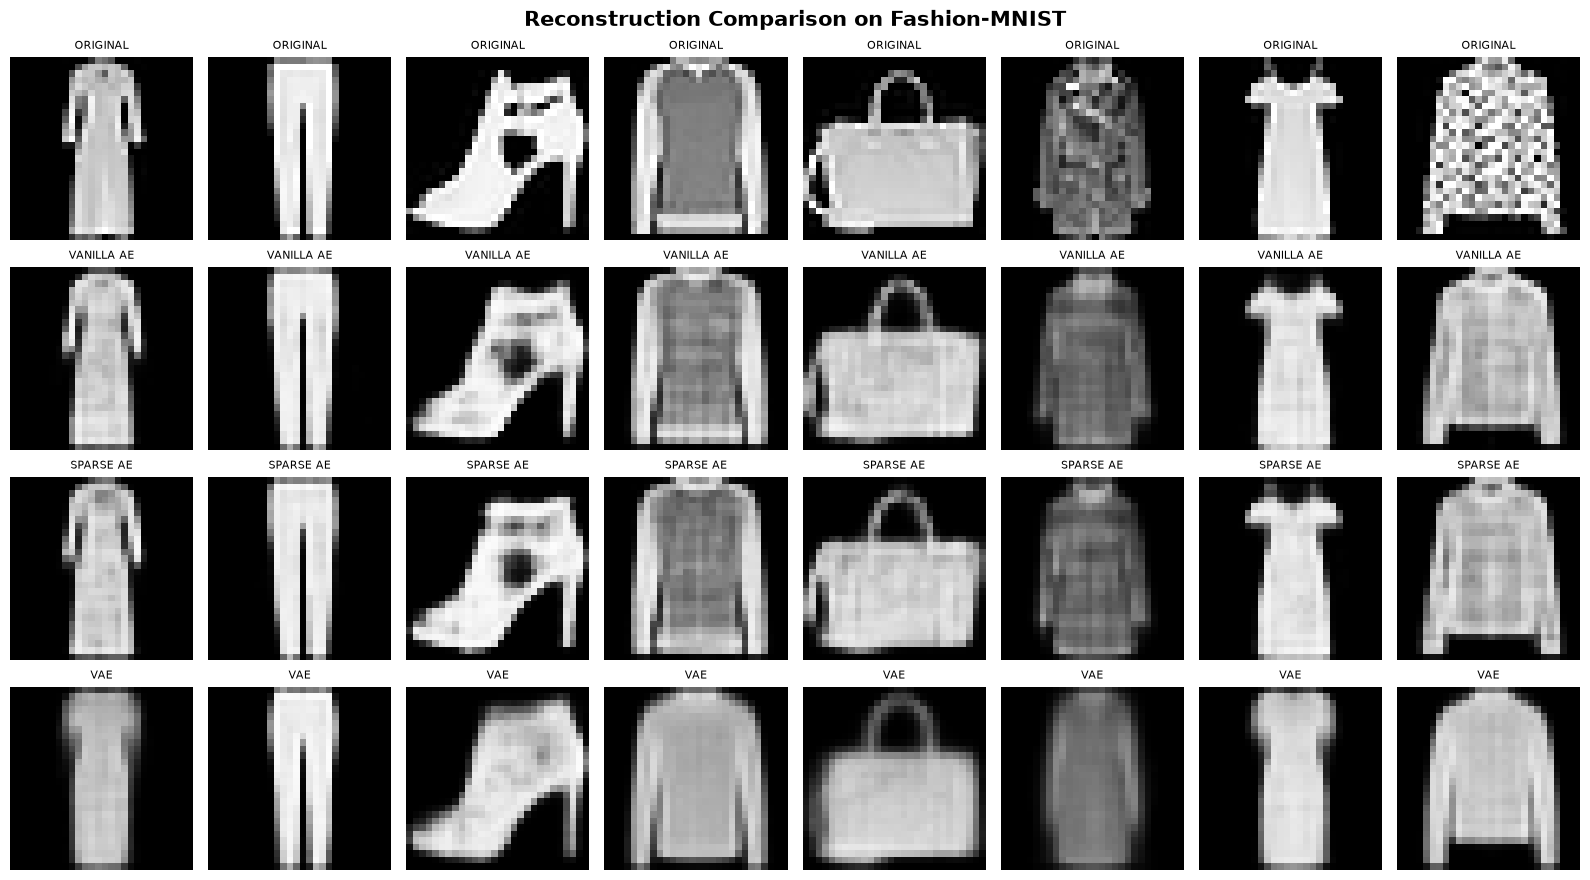

Reconstruction Grid Saved: D:\generative-models-comparison\results\reconstruction_comparison.png


In [93]:
fig, axes = plt.subplots(4, 8, figsize=(16, 9))

model_outputs = [
    ("ORIGINAL", original_samples),
    ("VANILLA AE", vanilla_samples),
    ("SPARSE AE", sparse_samples),
    ("VAE", vae_samples)
]

for row, (model_name, images) in enumerate(model_outputs):
    for col in range(8):
        axes[row, col].imshow(
            images[col].squeeze().numpy(),
            cmap="gray",
            vmin=0,
            vmax=1
        )

        axes[row, col].set_title(
            model_name,
            fontsize=8
        )
        axes[row, col].axis("off")

plt.suptitle(
    "Reconstruction Comparison on Fashion-MNIST",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()

RECONSTRUCTION_FIG_PATH = os.path.join(
    RESULTS_DIR,
    "reconstruction_comparison.png"
)

plt.savefig(
    RECONSTRUCTION_FIG_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Reconstruction Grid Saved:", RECONSTRUCTION_FIG_PATH)

In [94]:
print("VAE Architecture:")
print(vae)

print("\nVAE Decoder:")
print(vae.decoder)

VAE Architecture:
VAE(
  (encoder): Sequential(
    (0): Linear(in_features=784, out_features=512, bias=True)
    (1): ReLU()
    (2): Linear(in_features=512, out_features=256, bias=True)
    (3): ReLU()
  )
  (fc_mu): Linear(in_features=256, out_features=64, bias=True)
  (fc_logvar): Linear(in_features=256, out_features=64, bias=True)
  (decoder): Sequential(
    (0): Linear(in_features=64, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=512, bias=True)
    (3): ReLU()
    (4): Linear(in_features=512, out_features=784, bias=True)
    (5): Sigmoid()
  )
)

VAE Decoder:
Sequential(
  (0): Linear(in_features=64, out_features=256, bias=True)
  (1): ReLU()
  (2): Linear(in_features=256, out_features=512, bias=True)
  (3): ReLU()
  (4): Linear(in_features=512, out_features=784, bias=True)
  (5): Sigmoid()
)


In [95]:
# Generate 16 random samples from VAE
vae.eval()

with torch.no_grad():
    z = torch.randn(16, 64, device=device)
    vae_samples_generated = vae.decoder(z)
    vae_samples_generated = vae_samples_generated.view(-1, 1, 28, 28)

print("Generated Images Shape:", vae_samples_generated.shape)
print("Pixel Minimum:", vae_samples_generated.min().item())
print("Pixel Maximum:", vae_samples_generated.max().item())

Generated Images Shape: torch.Size([16, 1, 28, 28])
Pixel Minimum: 3.5398752004189675e-15
Pixel Maximum: 0.9829692244529724


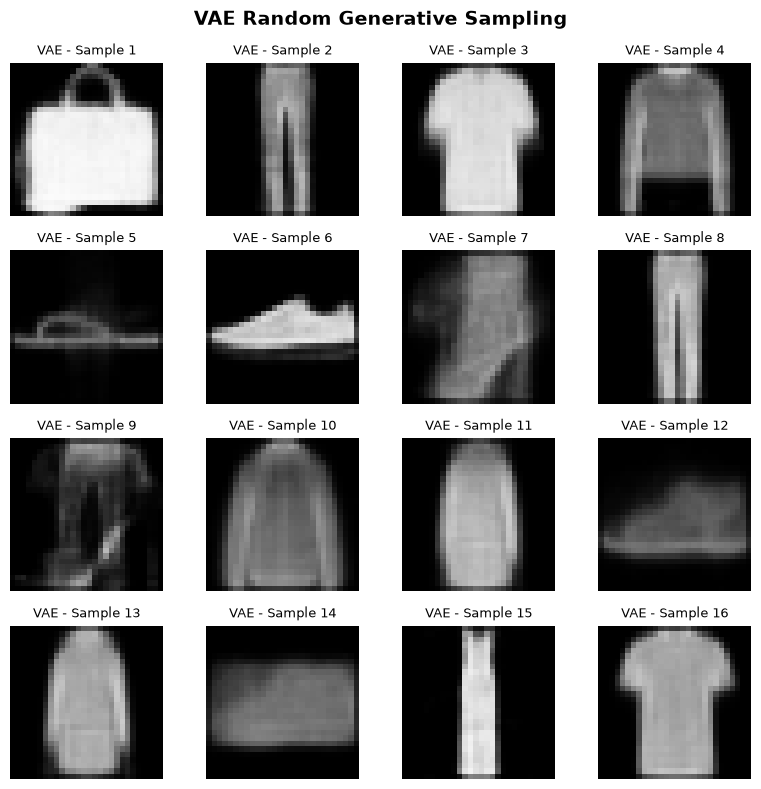

VAE Samples Saved: D:\generative-models-comparison\results\vae_random_samples.png


In [96]:
fig, axes = plt.subplots(4, 4, figsize=(8, 8))

for i, ax in enumerate(axes.flat):
    ax.imshow(
        vae_samples_generated[i].squeeze().cpu().numpy(),
        cmap="gray",
        vmin=0,
        vmax=1
    )
    ax.set_title(f"VAE - Sample {i + 1}", fontsize=9)
    ax.axis("off")

plt.suptitle(
    "VAE Random Generative Sampling",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()

VAE_SAMPLES_PATH = os.path.join(
    RESULTS_DIR,
    "vae_random_samples.png"
)

plt.savefig(
    VAE_SAMPLES_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("VAE Samples Saved:", VAE_SAMPLES_PATH)

In [97]:
print("Vanilla GAN Generator Architecture:")
print(vanilla_generator)

Vanilla GAN Generator Architecture:
Generator(
  (model): Sequential(
    (0): Linear(in_features=100, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=512, bias=True)
    (3): ReLU()
    (4): Linear(in_features=512, out_features=1024, bias=True)
    (5): ReLU()
    (6): Linear(in_features=1024, out_features=784, bias=True)
    (7): Tanh()
  )
)


In [98]:
# Generate 16 random samples from Vanilla GAN
vanilla_generator.eval()

with torch.no_grad():
    noise = torch.randn(16, 100, device=device)

    vanilla_gan_samples = vanilla_generator(noise)

    # Reshape and convert pixel range from [-1, 1] to [0, 1]
    vanilla_gan_samples = vanilla_gan_samples.view(-1, 1, 28, 28)
    vanilla_gan_samples = (vanilla_gan_samples + 1) / 2

print("Generated Images Shape:", vanilla_gan_samples.shape)
print("Pixel Minimum:", vanilla_gan_samples.min().item())
print("Pixel Maximum:", vanilla_gan_samples.max().item())

Generated Images Shape: torch.Size([16, 1, 28, 28])
Pixel Minimum: 0.0
Pixel Maximum: 0.9999592304229736


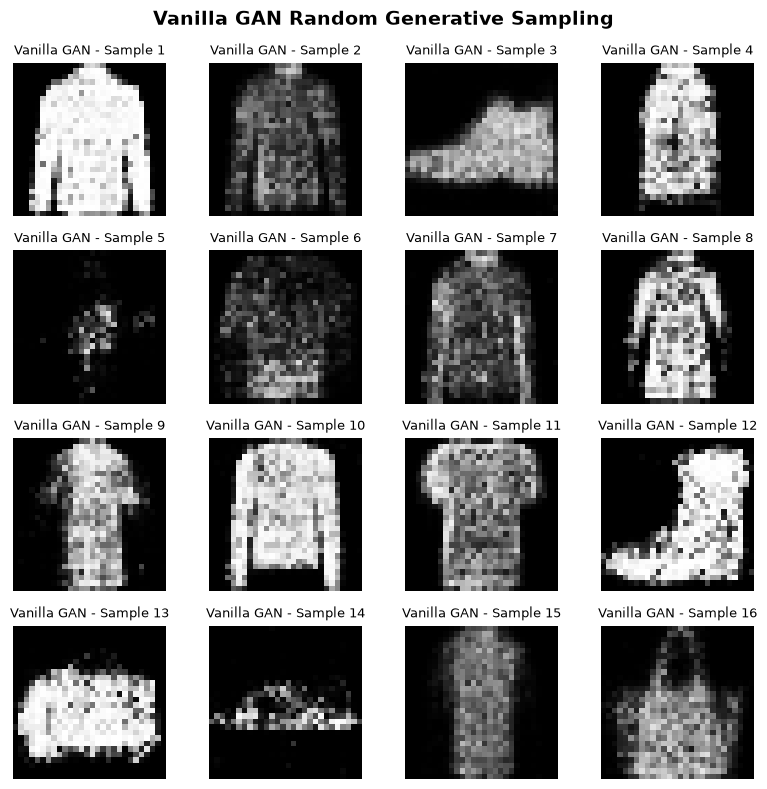

Vanilla GAN Samples Saved: D:\generative-models-comparison\results\vanilla_gan_random_samples.png


In [99]:
fig, axes = plt.subplots(4, 4, figsize=(8, 8))

for i, ax in enumerate(axes.flat):
    ax.imshow(
        vanilla_gan_samples[i].squeeze().cpu().numpy(),
        cmap="gray",
        vmin=0,
        vmax=1
    )
    ax.set_title(f"Vanilla GAN - Sample {i + 1}", fontsize=9)
    ax.axis("off")

plt.suptitle(
    "Vanilla GAN Random Generative Sampling",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()

VANILLA_GAN_SAMPLES_PATH = os.path.join(
    RESULTS_DIR,
    "vanilla_gan_random_samples.png"
)

plt.savefig(
    VANILLA_GAN_SAMPLES_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Vanilla GAN Samples Saved:", VANILLA_GAN_SAMPLES_PATH)

In [100]:
print("DCGAN Generator Architecture:")
print(dcgan_generator)

DCGAN Generator Architecture:
DCGANGenerator(
  (project): Linear(in_features=100, out_features=128, bias=True)
  (model): Sequential(
    (0): ConvTranspose2d(128, 64, kernel_size=(7, 7), stride=(1, 1), bias=False)
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): ConvTranspose2d(64, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (5): ReLU(inplace=True)
    (6): ConvTranspose2d(64, 1, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (7): Tanh()
  )
)


In [101]:
# Generate 16 random samples from DCGAN
dcgan_generator.eval()

with torch.no_grad():
    noise = torch.randn(16, 100, device=device)

    dcgan_samples = dcgan_generator(noise)

    # Convert pixel range from [-1, 1] to [0, 1]
    dcgan_samples = (dcgan_samples + 1) / 2

print("Generated Images Shape:", dcgan_samples.shape)
print("Pixel Minimum:", dcgan_samples.min().item())
print("Pixel Maximum:", dcgan_samples.max().item())

Generated Images Shape: torch.Size([16, 1, 28, 28])
Pixel Minimum: 0.0
Pixel Maximum: 0.9994016885757446


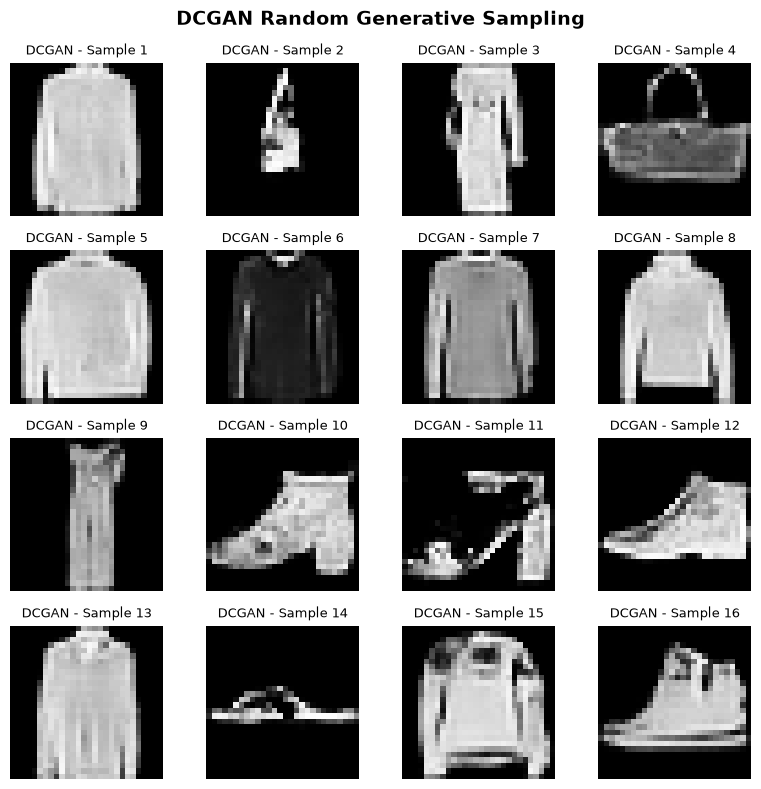

DCGAN Samples Saved: D:\generative-models-comparison\results\dcgan_random_samples.png


In [102]:
fig, axes = plt.subplots(4, 4, figsize=(8, 8))

for i, ax in enumerate(axes.flat):
    ax.imshow(
        dcgan_samples[i].squeeze().cpu().numpy(),
        cmap="gray",
        vmin=0,
        vmax=1
    )
    ax.set_title(f"DCGAN - Sample {i + 1}", fontsize=9)
    ax.axis("off")

plt.suptitle(
    "DCGAN Random Generative Sampling",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()

DCGAN_SAMPLES_PATH = os.path.join(
    RESULTS_DIR,
    "dcgan_random_samples.png"
)

plt.savefig(
    DCGAN_SAMPLES_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("DCGAN Samples Saved:", DCGAN_SAMPLES_PATH)

In [103]:
# Inspect DDPM checkpoint configuration
ddpm_checkpoint = torch.load(
    os.path.join(CHECKPOINT_DIR, "ddpm_finetuned.pth"),
    map_location=device,
    weights_only=False
)

print("Checkpoint Epoch:", ddpm_checkpoint["epoch"])
print("Beta Start:", ddpm_checkpoint["beta_start"])
print("Beta End:", ddpm_checkpoint["beta_end"])
print("Number of Timesteps:", ddpm_checkpoint["timesteps"])

Checkpoint Epoch: 10
Beta Start: 0.0001
Beta End: 0.02
Number of Timesteps: 1000


In [104]:
# DDPM noise schedule
TIMESTEPS = 1000

betas = torch.linspace(
    0.0001,
    0.02,
    TIMESTEPS,
    device=device
)

alphas = 1.0 - betas
alpha_bars = torch.cumprod(alphas, dim=0)

print("Betas Shape:", betas.shape)
print("Alphas Shape:", alphas.shape)
print("Alpha Bars Shape:", alpha_bars.shape)

print("\nBeta Start:", betas[0].item())
print("Beta End:", betas[-1].item())
print("Alpha Bar Minimum:", alpha_bars.min().item())
print("Alpha Bar Maximum:", alpha_bars.max().item())

Betas Shape: torch.Size([1000])
Alphas Shape: torch.Size([1000])
Alpha Bars Shape: torch.Size([1000])

Beta Start: 9.999999747378752e-05
Beta End: 0.019999999552965164
Alpha Bar Minimum: 4.0358307160204276e-05
Alpha Bar Maximum: 0.9998999834060669


In [105]:
import inspect

print("U-Net Forward Signature:")
print(inspect.signature(unet.forward))


U-Net Forward Signature:
(x, timesteps)


In [106]:
@torch.no_grad()
def generate_ddpm_samples(model, num_samples=16):
    model.eval()

    images = torch.randn(
        num_samples, 1, 28, 28,
        device=device
    )

    for t in reversed(range(TIMESTEPS)):
        timestep = torch.full(
            (num_samples,),
            t,
            device=device,
            dtype=torch.long
        )

        predicted_noise = model(images, timestep)

        alpha = alphas[t]
        alpha_bar = alpha_bars[t]
        beta = betas[t]

        noise = torch.randn_like(images) if t > 0 else torch.zeros_like(images)

        images = (
            1 / torch.sqrt(alpha)
        ) * (
            images -
            ((1 - alpha) / torch.sqrt(1 - alpha_bar)) * predicted_noise
        ) + torch.sqrt(beta) * noise

    images = torch.clamp(images, -1, 1)

    return images


ddpm_samples = generate_ddpm_samples(unet, num_samples=16)

# Convert pixel range from [-1, 1] to [0, 1]
ddpm_samples = (ddpm_samples + 1) / 2

print("Generated Images Shape:", ddpm_samples.shape)
print("Pixel Minimum:", ddpm_samples.min().item())
print("Pixel Maximum:", ddpm_samples.max().item())

Generated Images Shape: torch.Size([16, 1, 28, 28])
Pixel Minimum: 0.0
Pixel Maximum: 1.0


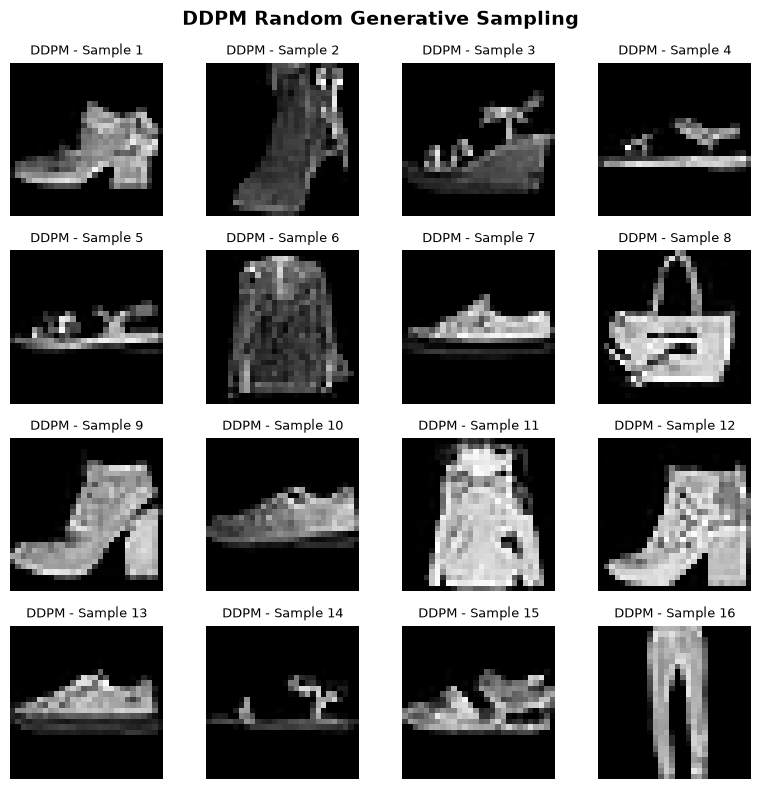

DDPM Samples Saved: D:\generative-models-comparison\results\ddpm_random_samples.png


In [107]:
fig, axes = plt.subplots(4, 4, figsize=(8, 8))

for i, ax in enumerate(axes.flat):
    ax.imshow(
        ddpm_samples[i].squeeze().cpu().numpy(),
        cmap="gray",
        vmin=0,
        vmax=1
    )
    ax.set_title(f"DDPM - Sample {i + 1}", fontsize=9)
    ax.axis("off")

plt.suptitle(
    "DDPM Random Generative Sampling",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()

DDPM_SAMPLES_PATH = os.path.join(
    RESULTS_DIR,
    "ddpm_random_samples.png"
)

plt.savefig(
    DDPM_SAMPLES_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("DDPM Samples Saved:", DDPM_SAMPLES_PATH)

In [108]:
import importlib.util

packages = [
    "torchmetrics",
    "torch_fidelity",
    "pytorch_fid",
    "torchvision"
]

for package in packages:
    available = importlib.util.find_spec(package) is not None
    print(f"{package}: {'Available' if available else 'Not Installed'}")

torchmetrics: Not Installed
torch_fidelity: Not Installed
pytorch_fid: Not Installed
torchvision: Available


In [109]:
from torchvision.models import inception_v3, Inception_V3_Weights

try:
    weights = Inception_V3_Weights.DEFAULT
    inception = inception_v3(weights=weights)
    print("Pretrained Inception-v3 Loaded Successfully")

except Exception as e:
    print("Failed to Load Pretrained Inception-v3")
    print("Error:", str(e))

Downloading: "https://download.pytorch.org/models/inception_v3_google-0cc3c7bd.pth" to C:\Users\ASUS/.cache\torch\hub\checkpoints\inception_v3_google-0cc3c7bd.pth


100%|██████████| 104M/104M [04:34<00:00, 397kB/s]    


Pretrained Inception-v3 Loaded Successfully


In [114]:
import os
import torch

TORCH_HOME = os.path.join(PROJECT_DIR, "torch_cache")
os.environ["TORCH_HOME"] = TORCH_HOME

print("PyTorch Cache:", torch.hub.get_dir())
print(
    "Inception Weights Exists:",
    os.path.exists(
        os.path.join(
            torch.hub.get_dir(),
            "checkpoints",
            "inception_v3_google-0cc3c7bd.pth"
        )
    )
)

PyTorch Cache: D:\generative-models-comparison\torch_cache\hub
Inception Weights Exists: True


In [116]:
print("Pretrained Inception-v3 Loaded Successfully")
print("Model Device:", next(inception.parameters()).device)
print("Feature Dimension: 2048")
print("Inception FC Layer:", inception.fc)

Pretrained Inception-v3 Loaded Successfully
Model Device: cpu
Feature Dimension: 2048
Inception FC Layer: Identity()


In [117]:
import torch
import torch.nn.functional as F

@torch.no_grad()
def preprocess_for_inception(images):
    images = images.to(device)

    # Convert grayscale to RGB
    images = images.repeat(1, 3, 1, 1)

    # Resize to 299 x 299
    images = F.interpolate(
        images,
        size=(299, 299),
        mode="bilinear",
        align_corners=False
    )

    # Apply ImageNet normalization
    mean = torch.tensor(
        [0.485, 0.456, 0.406],
        device=device
    ).view(1, 3, 1, 1)

    std = torch.tensor(
        [0.229, 0.224, 0.225],
        device=device
    ).view(1, 3, 1, 1)

    images = (images - mean) / std

    return images

# Test preprocessing
test_batch = test_images[:8]
processed_batch = preprocess_for_inception(test_batch)

print("Original Shape:", test_batch.shape)
print("Processed Shape:", processed_batch.shape)
print("Processed Minimum:", processed_batch.min().item())
print("Processed Maximum:", processed_batch.max().item())

Original Shape: torch.Size([8, 1, 28, 28])
Processed Shape: torch.Size([8, 3, 299, 299])
Processed Minimum: -2.1179039478302
Processed Maximum: 2.6399693489074707


In [118]:
@torch.no_grad()
def extract_inception_features(images, batch_size=32):
    inception.eval()
    all_features = []

    for start in range(0, len(images), batch_size):
        batch = images[start:start + batch_size]

        processed = preprocess_for_inception(batch)
        features = inception(processed)

        all_features.append(features.cpu())

    return torch.cat(all_features, dim=0)


# Test feature extraction
sample_features = extract_inception_features(test_images[:32])

print("Extracted Features Shape:", sample_features.shape)
print("Feature Dimension:", sample_features.shape[1])
print("Feature Minimum:", sample_features.min().item())
print("Feature Maximum:", sample_features.max().item())

Extracted Features Shape: torch.Size([32, 2048])
Feature Dimension: 2048
Feature Minimum: 0.0
Feature Maximum: 6.123319149017334


In [119]:
# Extract Inception features from all real test images
real_features = extract_inception_features(
    test_images,
    batch_size=32
)

# Save extracted features
REAL_FEATURES_PATH = os.path.join(
    RESULTS_DIR,
    "real_inception_features.pt"
)

torch.save(real_features, REAL_FEATURES_PATH)

print("Real Features Shape:", real_features.shape)
print("Number of Real Images:", len(real_features))
print("Feature Dimension:", real_features.shape[1])
print("Saved To:", REAL_FEATURES_PATH)

Real Features Shape: torch.Size([7000, 2048])
Number of Real Images: 7000
Feature Dimension: 2048
Saved To: D:\generative-models-comparison\results\real_inception_features.pt


In [120]:
@torch.no_grad()
def generate_vae_fid_samples(num_samples=256):
    vae.eval()

    z = torch.randn(num_samples, 64, device=device)
    generated = vae.decoder(z)

    return generated.view(-1, 1, 28, 28).cpu()


vae_fid_samples = generate_vae_fid_samples(256)

print("VAE Generated Shape:", vae_fid_samples.shape)
print("Pixel Minimum:", vae_fid_samples.min().item())
print("Pixel Maximum:", vae_fid_samples.max().item())

VAE Generated Shape: torch.Size([256, 1, 28, 28])
Pixel Minimum: 1.6378972613006957e-20
Pixel Maximum: 0.9925239682197571


In [121]:
@torch.no_grad()
def generate_vae_fid_samples(num_samples=256):
    vae.eval()

    z = torch.randn(num_samples, 64, device=device)
    generated = vae.decoder(z)

    return generated.view(-1, 1, 28, 28).cpu()


vae_fid_samples = generate_vae_fid_samples(256)

print("VAE Generated Shape:", vae_fid_samples.shape)
print("Pixel Minimum:", vae_fid_samples.min().item())
print("Pixel Maximum:", vae_fid_samples.max().item())

VAE Generated Shape: torch.Size([256, 1, 28, 28])
Pixel Minimum: 1.4217788992294156e-24
Pixel Maximum: 0.9907875657081604


In [122]:
@torch.no_grad()
def generate_vanilla_gan_fid_samples(num_samples=256):
    vanilla_generator.eval()

    noise = torch.randn(num_samples, 100, device=device)
    generated = vanilla_generator(noise)

    # Convert pixel range from [-1, 1] to [0, 1]
    generated = (generated + 1) / 2
    generated = torch.clamp(generated, 0, 1)

    return generated.view(-1, 1, 28, 28).cpu()


vanilla_gan_fid_samples = generate_vanilla_gan_fid_samples(256)

print("Vanilla GAN Generated Shape:", vanilla_gan_fid_samples.shape)
print("Pixel Minimum:", vanilla_gan_fid_samples.min().item())
print("Pixel Maximum:", vanilla_gan_fid_samples.max().item())

Vanilla GAN Generated Shape: torch.Size([256, 1, 28, 28])
Pixel Minimum: 0.0
Pixel Maximum: 0.9999997615814209


In [123]:
@torch.no_grad()
def generate_dcgan_fid_samples(num_samples=256):
    dcgan_generator.eval()

    noise = torch.randn(num_samples, 100, device=device)
    generated = dcgan_generator(noise)

    # Convert pixel range from [-1, 1] to [0, 1]
    generated = (generated + 1) / 2
    generated = torch.clamp(generated, 0, 1)

    return generated.cpu()


dcgan_fid_samples = generate_dcgan_fid_samples(256)

print("DCGAN Generated Shape:", dcgan_fid_samples.shape)
print("Pixel Minimum:", dcgan_fid_samples.min().item())
print("Pixel Maximum:", dcgan_fid_samples.max().item())

DCGAN Generated Shape: torch.Size([256, 1, 28, 28])
Pixel Minimum: 0.0
Pixel Maximum: 0.9995788335800171


In [125]:
ddpm_fid_samples = generate_ddpm_samples(
    unet,
    num_samples=32
)

# Convert pixel range from [-1, 1] to [0, 1]
ddpm_fid_samples = (
    (ddpm_fid_samples + 1) / 2
).clamp(0, 1).cpu()

print("DDPM Generated Shape:", ddpm_fid_samples.shape)
print("Pixel Minimum:", ddpm_fid_samples.min().item())
print("Pixel Maximum:", ddpm_fid_samples.max().item())

DDPM Generated Shape: torch.Size([32, 1, 28, 28])
Pixel Minimum: 0.0
Pixel Maximum: 1.0


In [126]:
vae_features = extract_inception_features(
    vae_fid_samples,
    batch_size=32
)

print("VAE Features Shape:", vae_features.shape)

VAE Features Shape: torch.Size([256, 2048])


In [127]:
vanilla_gan_features = extract_inception_features(
    vanilla_gan_fid_samples,
    batch_size=32
)

print("Vanilla GAN Features Shape:", vanilla_gan_features.shape)

Vanilla GAN Features Shape: torch.Size([256, 2048])


In [128]:
dcgan_features = extract_inception_features(
    dcgan_fid_samples,
    batch_size=32
)

print("DCGAN Features Shape:", dcgan_features.shape)

DCGAN Features Shape: torch.Size([256, 2048])


In [129]:
ddpm_features = extract_inception_features(
    ddpm_fid_samples,
    batch_size=32
)

print("DDPM Features Shape:", ddpm_features.shape)

DDPM Features Shape: torch.Size([32, 2048])


In [130]:
import numpy as np
from scipy.linalg import sqrtm

def calculate_fid(real_features, generated_features):
    real = real_features.numpy()
    generated = generated_features.numpy()

    mu_real = np.mean(real, axis=0)
    mu_generated = np.mean(generated, axis=0)

    cov_real = np.cov(real, rowvar=False)
    cov_generated = np.cov(generated, rowvar=False)

    mean_difference = mu_real - mu_generated

    covariance_product = sqrtm(
        cov_real @ cov_generated
    )

    if np.iscomplexobj(covariance_product):
        covariance_product = covariance_product.real

    fid = (
        mean_difference @ mean_difference
        + np.trace(cov_real + cov_generated - 2 * covariance_product)
    )

    return float(fid)


print("FID Calculation Function Ready")

FID Calculation Function Ready


In [131]:
NUM_FID_SAMPLES = 32

real_fid_features = real_features[:NUM_FID_SAMPLES]

fid_results = {}

generated_feature_sets = {
    "VAE": vae_features[:NUM_FID_SAMPLES],
    "Vanilla GAN": vanilla_gan_features[:NUM_FID_SAMPLES],
    "DCGAN": dcgan_features[:NUM_FID_SAMPLES],
    "DDPM": ddpm_features[:NUM_FID_SAMPLES]
}

for model_name, features in generated_feature_sets.items():
    fid_score = calculate_fid(
        real_fid_features,
        features
    )

    fid_results[model_name] = fid_score

    print(f"{model_name} FID: {fid_score:.4f}")

C:\Users\ASUS\AppData\Local\Temp\ipykernel_13472\2547551357.py:16: LinAlgWarning: Matrix is singular. The result might be inaccurate or the array might not have a square root.
  covariance_product = sqrtm(


VAE FID: 194.4362
Vanilla GAN FID: 264.9399
DCGAN FID: 164.9923
DDPM FID: 180.2160


In [133]:
fid_df = pd.DataFrame({
    "Model": list(fid_results.keys()),
    "FID": list(fid_results.values()),
    "Generated Samples": [32, 32, 32, 32]
})

fid_df = fid_df.sort_values("FID").reset_index(drop=True)

FID_CSV_PATH = os.path.join(
    RESULTS_DIR,
    "fid_metrics.csv"
)

fid_df.to_csv(FID_CSV_PATH, index=False)

print(fid_df)
print("\nSaved to:", FID_CSV_PATH)

         Model         FID  Generated Samples
0        DCGAN  164.992325                 32
1         DDPM  180.216040                 32
2          VAE  194.436187                 32
3  Vanilla GAN  264.939874                 32

Saved to: D:\generative-models-comparison\results\fid_metrics.csv


In [134]:
import time

@torch.no_grad()
def measure_inference_latency(model, input_data, model_type, num_runs=10):
    model.eval()

    # Warm-up
    for _ in range(3):
        if model_type == "vae":
            model(input_data)
        else:
            model(input_data)

    start_time = time.perf_counter()

    for _ in range(num_runs):
        if model_type == "vae":
            model(input_data)
        else:
            model(input_data)

    end_time = time.perf_counter()

    average_time = (end_time - start_time) / num_runs

    return average_time * 1000

In [135]:
batch_size = 64

real_batch = test_images[:batch_size].to(device)

noise_vae = torch.randn(batch_size, 64, device=device)
noise_gan = torch.randn(batch_size, 100, device=device)

print("Real Batch:", real_batch.shape)
print("VAE Noise:", noise_vae.shape)
print("GAN Noise:", noise_gan.shape)

Real Batch: torch.Size([64, 1, 28, 28])
VAE Noise: torch.Size([64, 64])
GAN Noise: torch.Size([64, 100])


In [136]:
latency_results = {}

# Autoencoder models: input images
latency_results["Vanilla AE"] = measure_inference_latency(
    vanilla_ae, real_batch, "ae"
)

latency_results["Sparse AE"] = measure_inference_latency(
    sparse_ae, real_batch, "ae"
)

latency_results["VAE"] = measure_inference_latency(
    vae, real_batch, "vae"
)

# GAN models: input random noise
latency_results["Vanilla GAN"] = measure_inference_latency(
    vanilla_generator, noise_gan, "gan"
)

latency_results["DCGAN"] = measure_inference_latency(
    dcgan_generator, noise_gan, "gan"
)

print("Inference Latency (Batch 64):")

for model_name, latency in latency_results.items():
    print(f"{model_name}: {latency:.4f} ms")

Inference Latency (Batch 64):
Vanilla AE: 0.9903 ms
Sparse AE: 0.9456 ms
VAE: 0.9261 ms
Vanilla GAN: 0.8821 ms
DCGAN: 2.5963 ms


In [137]:
import time

print("Measuring DDPM inference latency...")
print("Batch size: 64")
print("Diffusion timesteps:", TIMESTEPS)

start_time = time.perf_counter()

ddpm_latency_samples = generate_ddpm_samples(
    unet,
    num_samples=64
)

end_time = time.perf_counter()

ddpm_latency = (end_time - start_time) * 1000

latency_results["DDPM"] = ddpm_latency

print(f"\nDDPM Latency (Batch 64): {ddpm_latency:.4f} ms")
print("Generated Shape:", ddpm_latency_samples.shape)

Measuring DDPM inference latency...
Batch size: 64
Diffusion timesteps: 1000

DDPM Latency (Batch 64): 198408.1198 ms
Generated Shape: torch.Size([64, 1, 28, 28])


In [138]:
latency_df = pd.DataFrame({
    "Model": list(latency_results.keys()),
    "Batch Size": [64] * len(latency_results),
    "Inference Latency (ms)": list(latency_results.values())
})

latency_df = latency_df.sort_values(
    "Inference Latency (ms)"
).reset_index(drop=True)

LATENCY_CSV_PATH = os.path.join(
    RESULTS_DIR,
    "inference_latency.csv"
)

latency_df.to_csv(LATENCY_CSV_PATH, index=False)

print(latency_df)
print("\nSaved to:", LATENCY_CSV_PATH)

         Model  Batch Size  Inference Latency (ms)
0  Vanilla GAN          64                 0.88210
1          VAE          64                 0.92610
2    Sparse AE          64                 0.94559
3   Vanilla AE          64                 0.99027
4        DCGAN          64                 2.59628
5         DDPM          64            198408.11980

Saved to: D:\generative-models-comparison\results\inference_latency.csv


In [139]:
ddpm_checkpoint = torch.load(
    os.path.join(CHECKPOINT_DIR, "ddpm_finetuned.pth"),
    map_location="cpu",
    weights_only=False
)

print("DDPM Checkpoint Keys:")
print(ddpm_checkpoint.keys())

DDPM Checkpoint Keys:
dict_keys(['epoch', 'model_state_dict', 'optimizer_state_dict', 'train_losses', 'val_losses', 'beta_start', 'beta_end', 'timesteps'])


In [140]:
ddpm_train_losses = ddpm_checkpoint["train_losses"]
ddpm_val_losses = ddpm_checkpoint["val_losses"]

print("DDPM Training History")
print("Epochs:", len(ddpm_train_losses))
print("First Train Loss:", ddpm_train_losses[0])
print("Last Train Loss:", ddpm_train_losses[-1])
print("First Val Loss:", ddpm_val_losses[0])
print("Last Val Loss:", ddpm_val_losses[-1])
print("Best Val Loss:", min(ddpm_val_losses))

DDPM Training History
Epochs: 10
First Train Loss: 0.03723990853416593
Last Train Loss: 0.03440044571105476
First Val Loss: 0.03493152264166962
Last Val Loss: 0.036420574581081215
Best Val Loss: 0.03357271921228279


In [141]:
checkpoint_files = [
    "vanilla_ae.pth",
    "sparse_ae_improved.pth",
    "vae.pth",
    "vanilla_gan.pth",
    "dcgan.pth"
]

for filename in checkpoint_files:
    checkpoint_path = os.path.join(
        CHECKPOINT_DIR,
        filename
    )

    checkpoint = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=False
    )

    print(f"\n{filename}")
    print("Keys:", checkpoint.keys())


vanilla_ae.pth
Keys: odict_keys(['encoder.0.weight', 'encoder.0.bias', 'encoder.2.weight', 'encoder.2.bias', 'encoder.4.weight', 'encoder.4.bias', 'decoder.0.weight', 'decoder.0.bias', 'decoder.2.weight', 'decoder.2.bias', 'decoder.4.weight', 'decoder.4.bias'])

sparse_ae_improved.pth
Keys: odict_keys(['encoder.0.weight', 'encoder.0.bias', 'encoder.2.weight', 'encoder.2.bias', 'encoder.4.weight', 'encoder.4.bias', 'decoder.0.weight', 'decoder.0.bias', 'decoder.2.weight', 'decoder.2.bias', 'decoder.4.weight', 'decoder.4.bias'])

vae.pth
Keys: dict_keys(['epoch', 'model_state_dict', 'optimizer_state_dict', 'val_loss'])

vanilla_gan.pth
Keys: dict_keys(['epoch', 'generator_state_dict', 'discriminator_state_dict', 'generator_optimizer_state_dict', 'discriminator_optimizer_state_dict', 'generator_losses', 'discriminator_losses'])

dcgan.pth
Keys: dict_keys(['epoch', 'generator_state_dict', 'discriminator_state_dict', 'generator_optimizer_state_dict', 'discriminator_optimizer_state_dict', '

In [142]:
# Load Vanilla GAN history
gan_checkpoint = torch.load(
    os.path.join(CHECKPOINT_DIR, "vanilla_gan.pth"),
    map_location="cpu",
    weights_only=False
)

vanilla_gan_g_losses = gan_checkpoint["generator_losses"]
vanilla_gan_d_losses = gan_checkpoint["discriminator_losses"]


# Load DCGAN history
dcgan_checkpoint = torch.load(
    os.path.join(CHECKPOINT_DIR, "dcgan.pth"),
    map_location="cpu",
    weights_only=False
)

dcgan_g_losses = dcgan_checkpoint["generator_losses"]
dcgan_d_losses = dcgan_checkpoint["discriminator_losses"]


print("Vanilla GAN")
print("Epochs:", len(vanilla_gan_g_losses))
print("Generator Loss:", vanilla_gan_g_losses[0], "->", vanilla_gan_g_losses[-1])
print("Discriminator Loss:", vanilla_gan_d_losses[0], "->", vanilla_gan_d_losses[-1])

print("\nDCGAN")
print("Epochs:", len(dcgan_g_losses))
print("Generator Loss:", dcgan_g_losses[0], "->", dcgan_g_losses[-1])
print("Discriminator Loss:", dcgan_d_losses[0], "->", dcgan_d_losses[-1])

Vanilla GAN
Epochs: 150
Generator Loss: 2.0706799706639765 -> 0.7198355142112192
Discriminator Loss: 0.3274582708126878 -> 0.6909321856825319

DCGAN
Epochs: 100
Generator Loss: 1.2905535765978844 -> 1.5526945648128039
Discriminator Loss: 0.45386649416461927 -> 0.4304796370877523


## Latent interpolation

In [143]:
@torch.no_grad()
def interpolate_ae(model, image1, image2, steps=6):
    model.eval()

    image1 = image1.to(device).view(1, -1)
    image2 = image2.to(device).view(1, -1)

    z1 = model.encoder(image1)
    z2 = model.encoder(image2)

    alphas = torch.linspace(0, 1, steps, device=device)

    interpolated_images = []

    for alpha in alphas:
        z = (1 - alpha) * z1 + alpha * z2
        generated = model.decoder(z)
        interpolated_images.append(
            generated.view(1, 28, 28).cpu()
        )

    return torch.stack(interpolated_images), alphas.cpu()


# Select two test images
image1 = test_images[0]
image2 = test_images[10]

vanilla_ae_interpolation, interpolation_alphas = interpolate_ae(
    vanilla_ae, image1, image2
)

print("Interpolation Shape:", vanilla_ae_interpolation.shape)
print("Alpha Values:", interpolation_alphas.tolist())

Interpolation Shape: torch.Size([6, 1, 28, 28])
Alpha Values: [0.0, 0.20000000298023224, 0.4000000059604645, 0.6000000238418579, 0.800000011920929, 1.0]


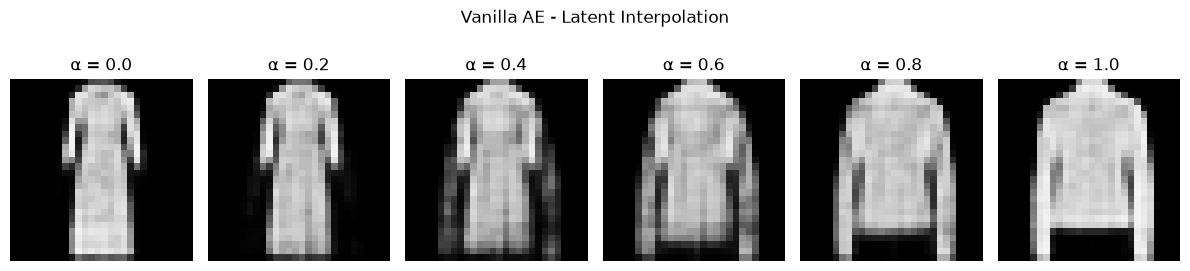

In [145]:
fig, axes = plt.subplots(1, 6, figsize=(12, 3))

for i, alpha in enumerate(interpolation_alphas):
    axes[i].imshow(
        vanilla_ae_interpolation[i].squeeze().numpy(),
        cmap="gray",
        vmin=0,
        vmax=1
    )
    axes[i].set_title(f"α = {alpha:.1f}")
    axes[i].axis("off")

plt.suptitle("Vanilla AE - Latent Interpolation")
plt.tight_layout()

plt.savefig(
    os.path.join(RESULTS_DIR, "vanilla_ae_interpolation.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

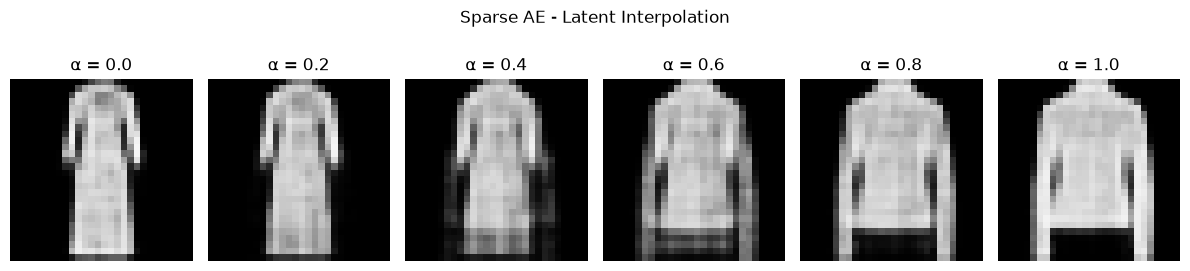

Interpolation Shape: torch.Size([6, 1, 28, 28])


In [146]:
sparse_ae_interpolation, interpolation_alphas = interpolate_ae(
    sparse_ae, image1, image2
)

fig, axes = plt.subplots(1, 6, figsize=(12, 3))

for i, alpha in enumerate(interpolation_alphas):
    axes[i].imshow(
        sparse_ae_interpolation[i].squeeze().numpy(),
        cmap="gray",
        vmin=0,
        vmax=1
    )
    axes[i].set_title(f"α = {alpha:.1f}")
    axes[i].axis("off")

plt.suptitle("Sparse AE - Latent Interpolation")
plt.tight_layout()

plt.savefig(
    os.path.join(RESULTS_DIR, "sparse_ae_interpolation.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Interpolation Shape:", sparse_ae_interpolation.shape)

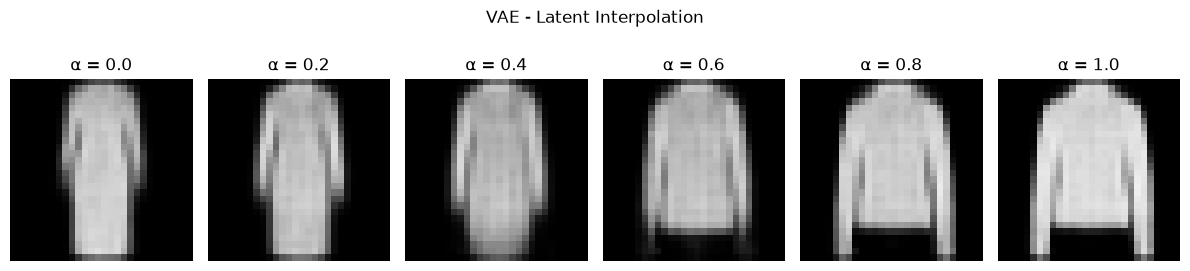

Interpolation Shape: torch.Size([6, 1, 28, 28])


In [149]:
@torch.no_grad()
def interpolate_vae(model, image1, image2, steps=6):
    model.eval()

    image1 = image1.to(device).view(1, -1)
    image2 = image2.to(device).view(1, -1)

    # Extract latent mean
    hidden1 = model.encoder(image1)
    hidden2 = model.encoder(image2)

    mu1 = model.fc_mu(hidden1)
    mu2 = model.fc_mu(hidden2)

    alphas = torch.linspace(0, 1, steps, device=device)
    interpolated_images = []

    for alpha in alphas:
        z = (1 - alpha) * mu1 + alpha * mu2
        generated = model.decoder(z)

        interpolated_images.append(
            generated.view(1, 28, 28).cpu()
        )

    return torch.stack(interpolated_images), alphas.cpu()


vae_interpolation, interpolation_alphas = interpolate_vae(
    vae, image1, image2
)

fig, axes = plt.subplots(1, 6, figsize=(12, 3))

for i, alpha in enumerate(interpolation_alphas):
    axes[i].imshow(
        vae_interpolation[i].squeeze().numpy(),
        cmap="gray",
        vmin=0,
        vmax=1
    )
    axes[i].set_title(f"α = {alpha:.1f}")
    axes[i].axis("off")

plt.suptitle("VAE - Latent Interpolation")
plt.tight_layout()

plt.savefig(
    os.path.join(RESULTS_DIR, "vae_interpolation.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Interpolation Shape:", vae_interpolation.shape)

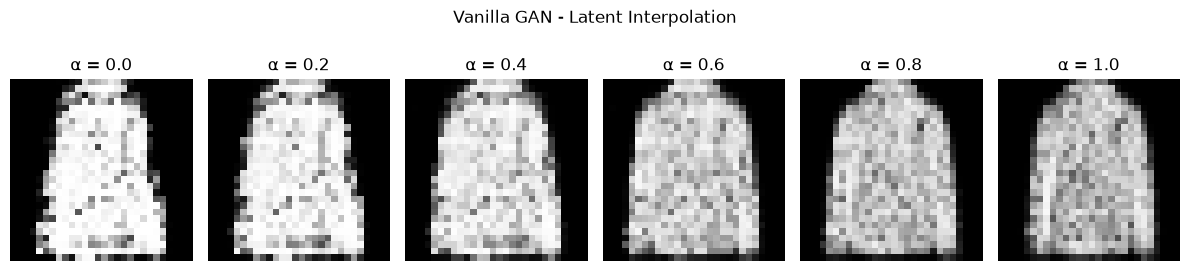

Interpolation Shape: torch.Size([6, 1, 28, 28])


In [150]:
@torch.no_grad()
def interpolate_gan(generator, steps=6, latent_dim=100):
    generator.eval()

    z1 = torch.randn(1, latent_dim, device=device)
    z2 = torch.randn(1, latent_dim, device=device)

    alphas = torch.linspace(0, 1, steps, device=device)
    interpolated_images = []

    for alpha in alphas:
        z = (1 - alpha) * z1 + alpha * z2
        generated = generator(z)

        generated = (generated + 1) / 2
        generated = generated.clamp(0, 1)

        interpolated_images.append(
            generated.view(1, 28, 28).cpu()
        )

    return torch.stack(interpolated_images), alphas.cpu()


vanilla_gan_interpolation, interpolation_alphas = interpolate_gan(
    vanilla_generator
)

fig, axes = plt.subplots(1, 6, figsize=(12, 3))

for i, alpha in enumerate(interpolation_alphas):
    axes[i].imshow(
        vanilla_gan_interpolation[i].squeeze().numpy(),
        cmap="gray",
        vmin=0,
        vmax=1
    )
    axes[i].set_title(f"α = {alpha:.1f}")
    axes[i].axis("off")

plt.suptitle("Vanilla GAN - Latent Interpolation")
plt.tight_layout()

plt.savefig(
    os.path.join(RESULTS_DIR, "vanilla_gan_interpolation.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Interpolation Shape:", vanilla_gan_interpolation.shape)

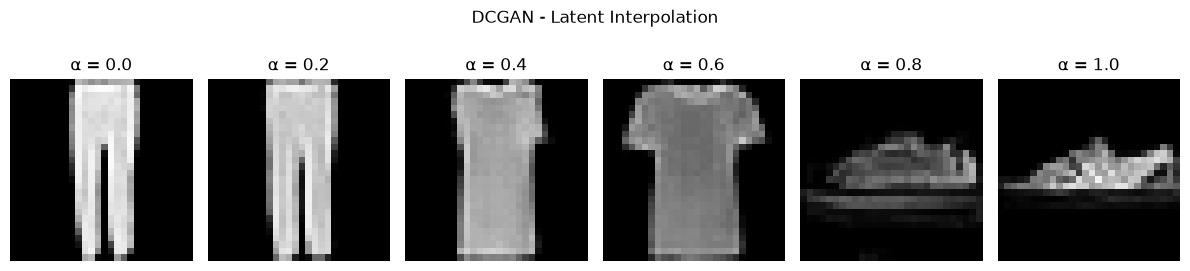

Interpolation Shape: torch.Size([6, 1, 28, 28])


In [151]:
dcgan_interpolation, interpolation_alphas = interpolate_gan(
    dcgan_generator
)

fig, axes = plt.subplots(1, 6, figsize=(12, 3))

for i, alpha in enumerate(interpolation_alphas):
    axes[i].imshow(
        dcgan_interpolation[i].squeeze().numpy(),
        cmap="gray",
        vmin=0,
        vmax=1
    )
    axes[i].set_title(f"α = {alpha:.1f}")
    axes[i].axis("off")

plt.suptitle("DCGAN - Latent Interpolation")
plt.tight_layout()

plt.savefig(
    os.path.join(RESULTS_DIR, "dcgan_interpolation.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Interpolation Shape:", dcgan_interpolation.shape)

Training stability

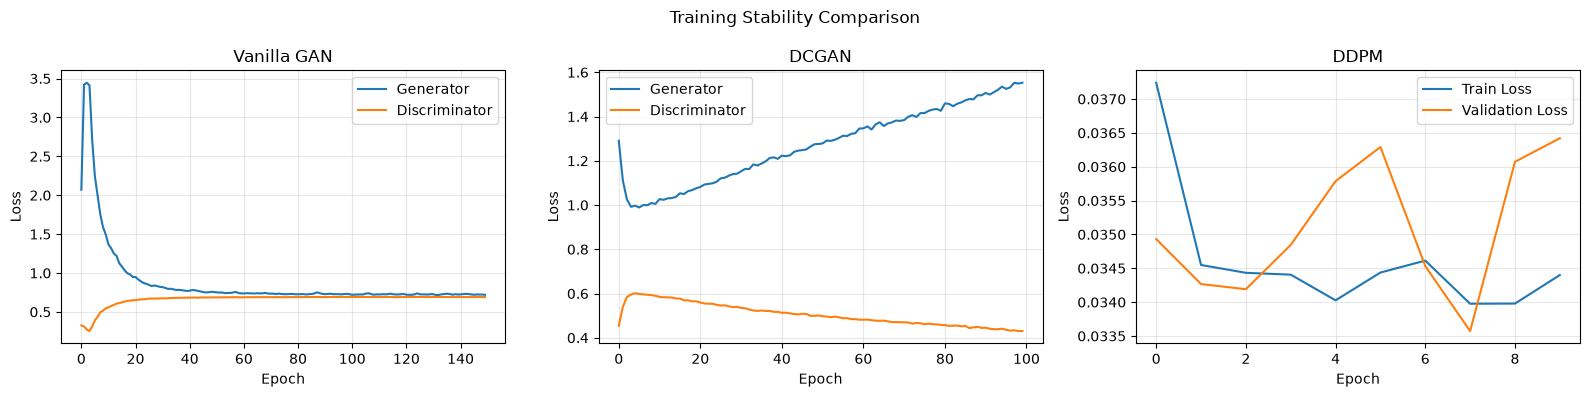

In [152]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# Vanilla GAN
axes[0].plot(vanilla_gan_g_losses, label="Generator")
axes[0].plot(vanilla_gan_d_losses, label="Discriminator")
axes[0].set_title("Vanilla GAN")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

# DCGAN
axes[1].plot(dcgan_g_losses, label="Generator")
axes[1].plot(dcgan_d_losses, label="Discriminator")
axes[1].set_title("DCGAN")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(alpha=0.3)

# DDPM
axes[2].plot(ddpm_train_losses, label="Train Loss")
axes[2].plot(ddpm_val_losses, label="Validation Loss")
axes[2].set_title("DDPM")
axes[2].set_xlabel("Epoch")
axes[2].set_ylabel("Loss")
axes[2].legend()
axes[2].grid(alpha=0.3)

plt.suptitle("Training Stability Comparison")
plt.tight_layout()

plt.savefig(
    os.path.join(RESULTS_DIR, "training_stability_curves.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [153]:
final_results = {
    "Model": [
        "Vanilla AE",
        "Sparse AE",
        "VAE",
        "Vanilla GAN",
        "DCGAN",
        "DDPM"
    ],
    "MSE": [
        0.006143,
        0.006198,
        0.019956,
        None,
        None,
        None
    ],
    "PSNR (dB)": [
        23.3536,
        23.3206,
        17.6005,
        None,
        None,
        None
    ],
    "SSIM": [
        0.8367,
        0.8353,
        0.6273,
        None,
        None,
        None
    ],
    "FID": [
        None,
        None,
        194.4362,
        264.9399,
        164.9923,
        180.2160
    ],
    "Inference Latency (ms)": [
        latency_results["Vanilla AE"],
        latency_results["Sparse AE"],
        latency_results["VAE"],
        latency_results["Vanilla GAN"],
        latency_results["DCGAN"],
        latency_results["DDPM"]
    ]
}

final_df = pd.DataFrame(final_results)

FINAL_CSV_PATH = os.path.join(
    RESULTS_DIR,
    "final_comparison_table.csv"
)

final_df.to_csv(FINAL_CSV_PATH, index=False)

print(final_df.to_string(index=False))
print("\nSaved to:", FINAL_CSV_PATH)

      Model      MSE  PSNR (dB)   SSIM      FID  Inference Latency (ms)
 Vanilla AE 0.006143    23.3536 0.8367      NaN                 0.99027
  Sparse AE 0.006198    23.3206 0.8353      NaN                 0.94559
        VAE 0.019956    17.6005 0.6273 194.4362                 0.92610
Vanilla GAN      NaN        NaN    NaN 264.9399                 0.88210
      DCGAN      NaN        NaN    NaN 164.9923                 2.59628
       DDPM      NaN        NaN    NaN 180.2160            198408.11980

Saved to: D:\generative-models-comparison\results\final_comparison_table.csv


In [155]:
mlp_results = pd.DataFrame({
    "Experiment": [
        "MLP Classifier",
        "Direct Weight Transpose Projection",
        "Latent Transpose Projection",
        "Frozen Latent Decoder",
        "Random Prior Sampling"
    ],
    "Metric": [
        "Test Accuracy",
        "Generated Images",
        "Generated Images",
        "MSE / PSNR / SSIM",
        "Generated Images"
    ],
    "Result": [
        "89.5%",
        "10 images",
        "7000 images",
        "0.020743 / 17.6719 dB / 0.6311",
        "16 images"
    ]
})

MLP_CSV_PATH = os.path.join(
    RESULTS_DIR,
    "mlp_experiment_results.csv"
)

mlp_results.to_csv(MLP_CSV_PATH, index=False)

print(mlp_results.to_string(index=False))
print("\nSaved to:", MLP_CSV_PATH)

                        Experiment            Metric                         Result
                    MLP Classifier     Test Accuracy                          89.5%
Direct Weight Transpose Projection  Generated Images                      10 images
       Latent Transpose Projection  Generated Images                    7000 images
             Frozen Latent Decoder MSE / PSNR / SSIM 0.020743 / 17.6719 dB / 0.6311
             Random Prior Sampling  Generated Images                      16 images

Saved to: D:\generative-models-comparison\results\mlp_experiment_results.csv


=======================================

In [161]:
FID_NUM_SAMPLES = 128

vae_fid_samples_equal = vae_fid_samples[:FID_NUM_SAMPLES]
vanilla_gan_fid_samples_equal = vanilla_gan_fid_samples[:FID_NUM_SAMPLES]
dcgan_fid_samples_equal = dcgan_fid_samples[:FID_NUM_SAMPLES]

ddpm_fid_samples_equal = ddpm_fid_samples

real_fid_features_equal = real_features[:FID_NUM_SAMPLES]

print("FID Sample Counts")
print("Real:", len(real_fid_features_equal))
print("VAE:", len(vae_fid_samples_equal))
print("Vanilla GAN:", len(vanilla_gan_fid_samples_equal))
print("DCGAN:", len(dcgan_fid_samples_equal))
print("DDPM:", len(ddpm_fid_samples_equal))

FID Sample Counts
Real: 128
VAE: 128
Vanilla GAN: 128
DCGAN: 128
DDPM: 32


In [164]:
# Generate 96 additional DDPM samples
unet.eval()

additional_ddpm_samples = generate_ddpm_samples(
    unet,
    num_samples=96
)

# Combine with the existing 32 samples
ddpm_fid_samples_equal = torch.cat(
    [ddpm_fid_samples, additional_ddpm_samples],
    dim=0
)

print("Updated DDPM samples:", ddpm_fid_samples_equal.shape)

Updated DDPM samples: torch.Size([128, 1, 28, 28])


In [165]:
ddpm_features_128 = extract_inception_features(
    ddpm_fid_samples_equal
)

print("DDPM feature shape:", ddpm_features_128.shape)

DDPM feature shape: torch.Size([128, 2048])


In [166]:
FID_NUM_SAMPLES = 128

real_fid_features_equal = real_features[:FID_NUM_SAMPLES]

fid_results_128 = {
    "VAE": calculate_fid(
        real_fid_features_equal,
        vae_features[:FID_NUM_SAMPLES]
    ),
    "Vanilla GAN": calculate_fid(
        real_fid_features_equal,
        vanilla_gan_features[:FID_NUM_SAMPLES]
    ),
    "DCGAN": calculate_fid(
        real_fid_features_equal,
        dcgan_features[:FID_NUM_SAMPLES]
    ),
    "DDPM": calculate_fid(
        real_fid_features_equal,
        ddpm_features_128
    )
}

print("Updated FID Scores (128 samples each)")
for model_name, score in fid_results_128.items():
    print(f"{model_name}: {score:.4f}")

C:\Users\ASUS\AppData\Local\Temp\ipykernel_13472\2547551357.py:16: LinAlgWarning: Matrix is singular. The result might be inaccurate or the array might not have a square root.
  covariance_product = sqrtm(


Updated FID Scores (128 samples each)
VAE: 153.0886
Vanilla GAN: 213.9064
DCGAN: 107.4314
DDPM: 126.3215


In [167]:
fid_df = pd.DataFrame({
    "Model": ["VAE", "Vanilla GAN", "DCGAN", "DDPM"],
    "FID": [
        fid_results_128["VAE"],
        fid_results_128["Vanilla GAN"],
        fid_results_128["DCGAN"],
        fid_results_128["DDPM"]
    ],
    "Number of Samples": [128, 128, 128, 128]
})

fid_path = os.path.join(RESULTS_DIR, "fid_metrics.csv")
fid_df.to_csv(fid_path, index=False)

print(fid_df.to_string(index=False))
print("\nSaved to:", fid_path)

      Model        FID  Number of Samples
        VAE 153.088649                128
Vanilla GAN 213.906434                128
      DCGAN 107.431360                128
       DDPM 126.321516                128

Saved to: D:\generative-models-comparison\results\fid_metrics.csv


In [168]:
# Load existing comparison table
comparison_df = pd.read_csv(
    os.path.join(RESULTS_DIR, "final_comparison_table.csv")
)

# Update FID values
fid_mapping = {
    "VAE": fid_results_128["VAE"],
    "Vanilla GAN": fid_results_128["Vanilla GAN"],
    "DCGAN": fid_results_128["DCGAN"],
    "DDPM": fid_results_128["DDPM"]
}

comparison_df["FID"] = comparison_df["Model"].map(fid_mapping).fillna(
    comparison_df["FID"]
)

# Save updated comparison table
comparison_path = os.path.join(
    RESULTS_DIR, "final_comparison_table.csv"
)
comparison_df.to_csv(comparison_path, index=False)

print(comparison_df.to_string(index=False))
print("\nUpdated:", comparison_path)

      Model      MSE  PSNR (dB)   SSIM        FID  Inference Latency (ms)
 Vanilla AE 0.006143    23.3536 0.8367        NaN                 0.99027
  Sparse AE 0.006198    23.3206 0.8353        NaN                 0.94559
        VAE 0.019956    17.6005 0.6273 153.088649                 0.92610
Vanilla GAN      NaN        NaN    NaN 213.906434                 0.88210
      DCGAN      NaN        NaN    NaN 107.431360                 2.59628
       DDPM      NaN        NaN    NaN 126.321516            198408.11980

Updated: D:\generative-models-comparison\results\final_comparison_table.csv


Figure 3 size: (2369, 742)


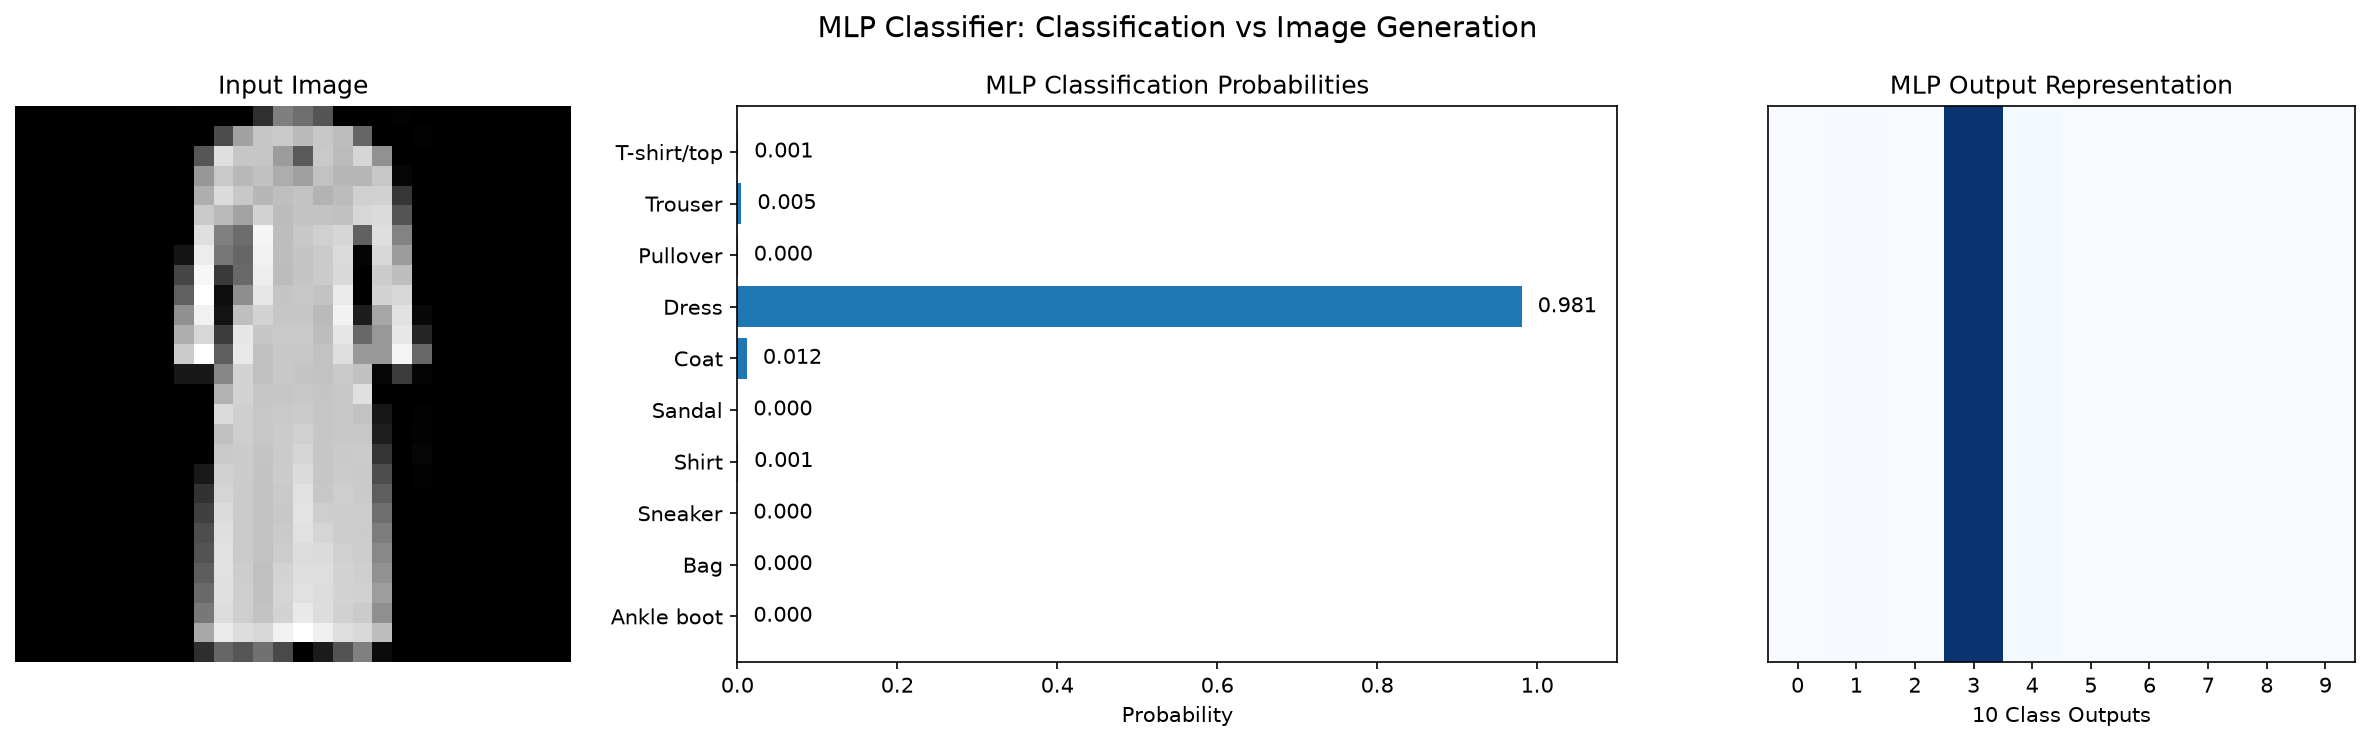

In [169]:
from PIL import Image
import os

figure_path = os.path.join(
    RESULTS_DIR,
    "mlp_generation_limitation.png"
)

img = Image.open(figure_path)

print("Figure 3 size:", img.size)
display(img)



mlp_weight_transpose_projection.png


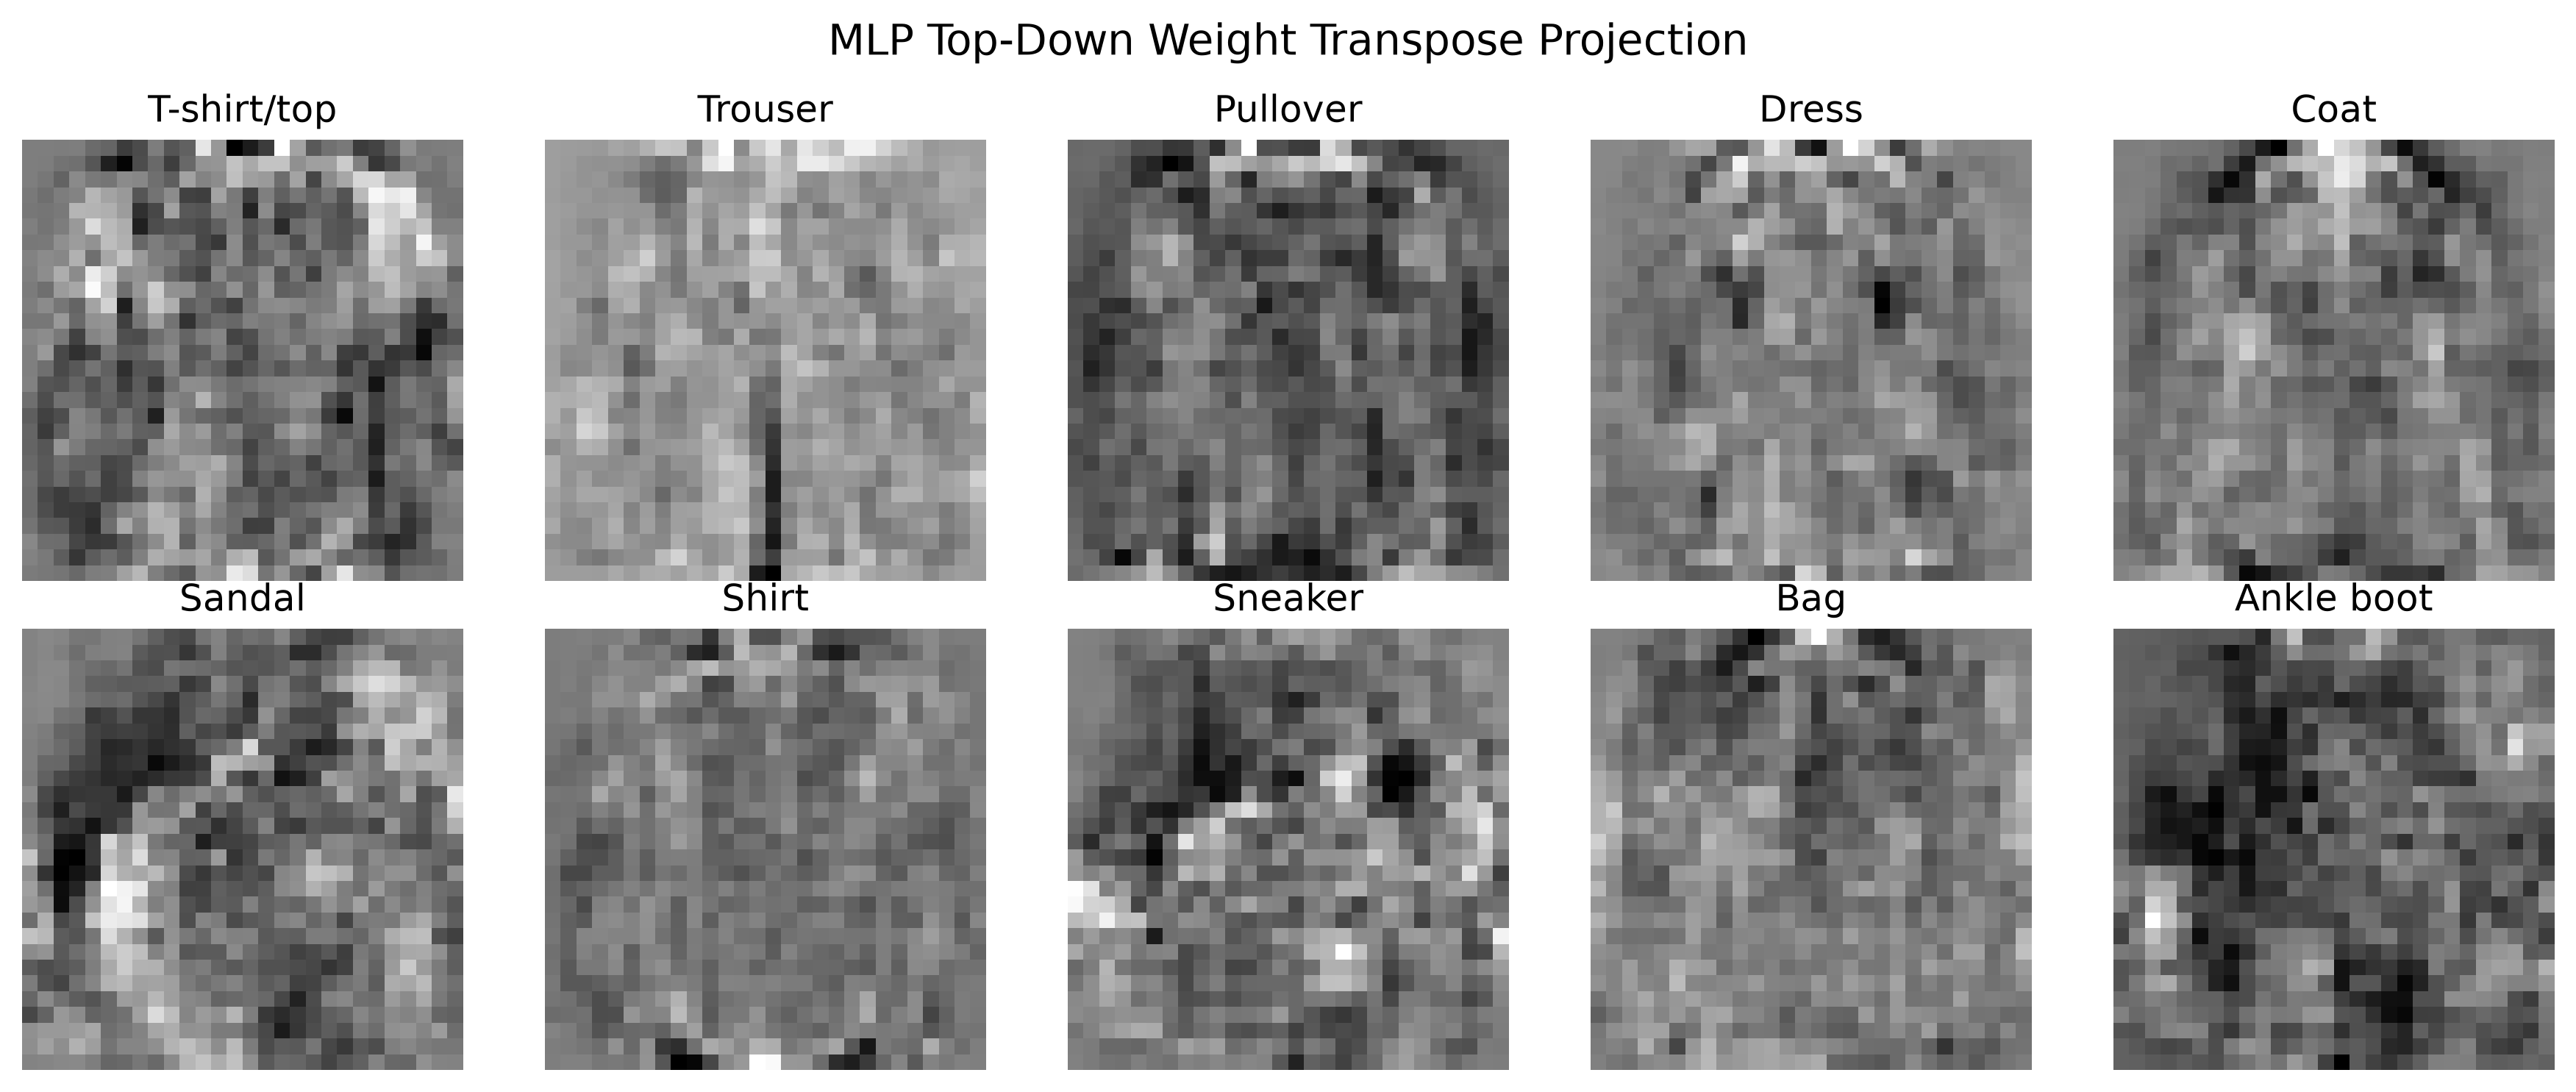


mlp_latent_transpose_comparison.png


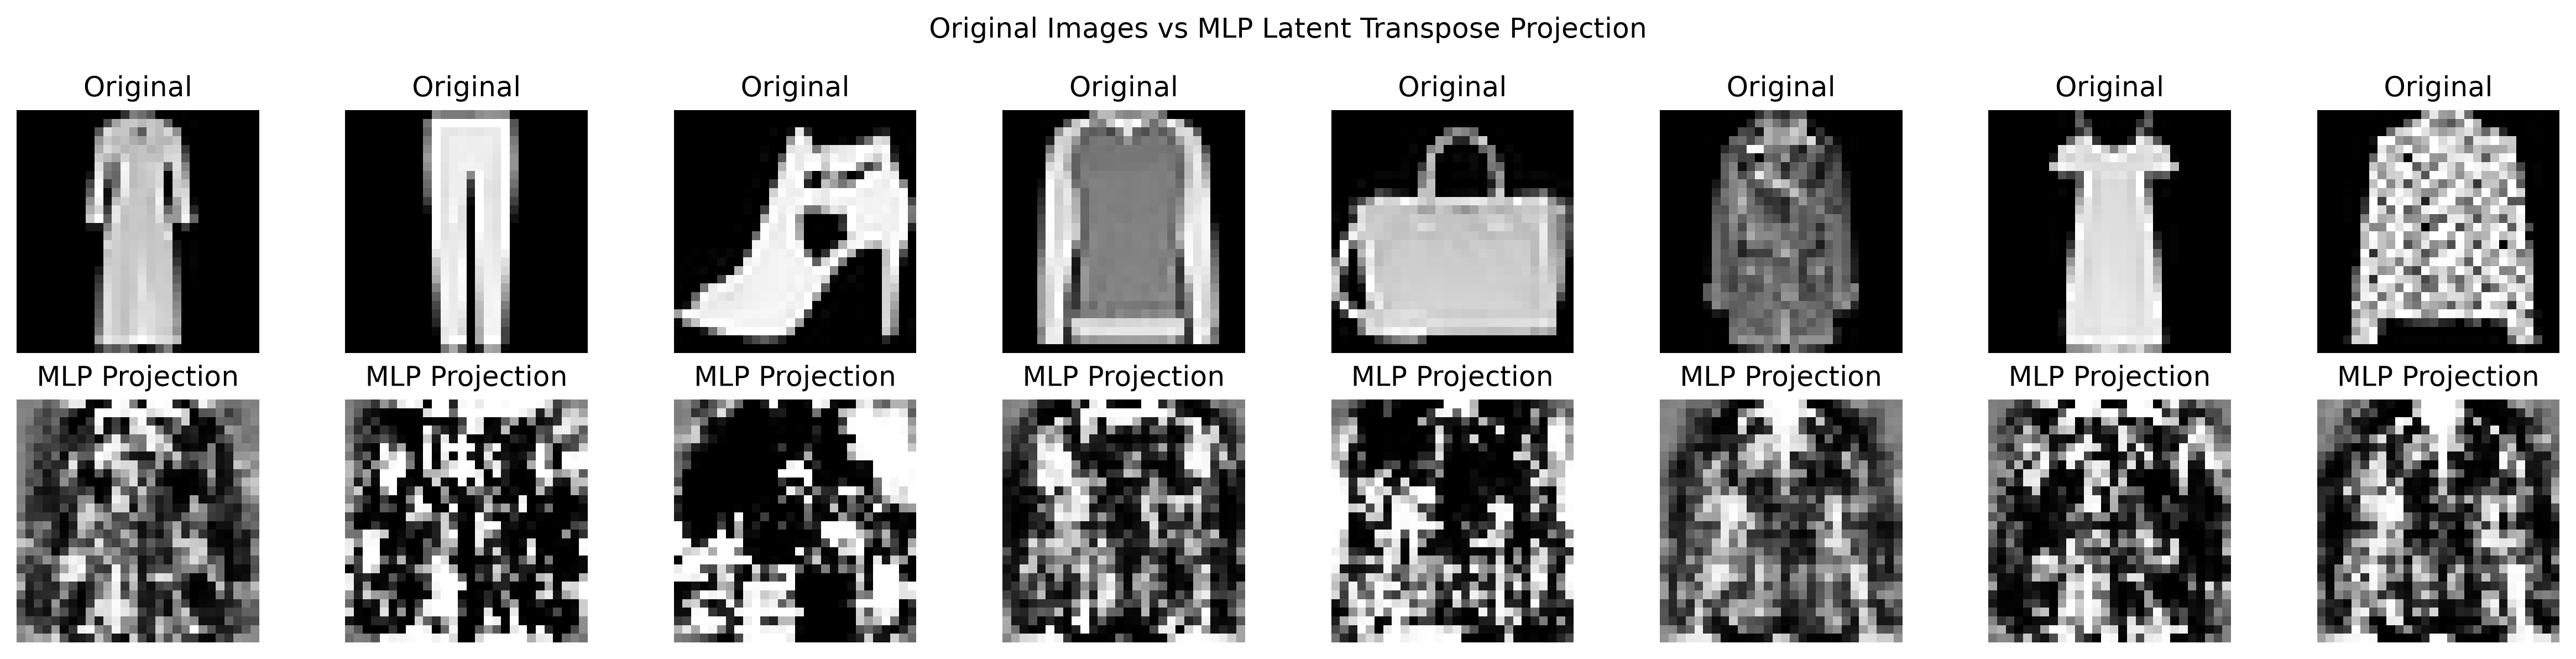


mlp_frozen_decoder_reconstruction.png


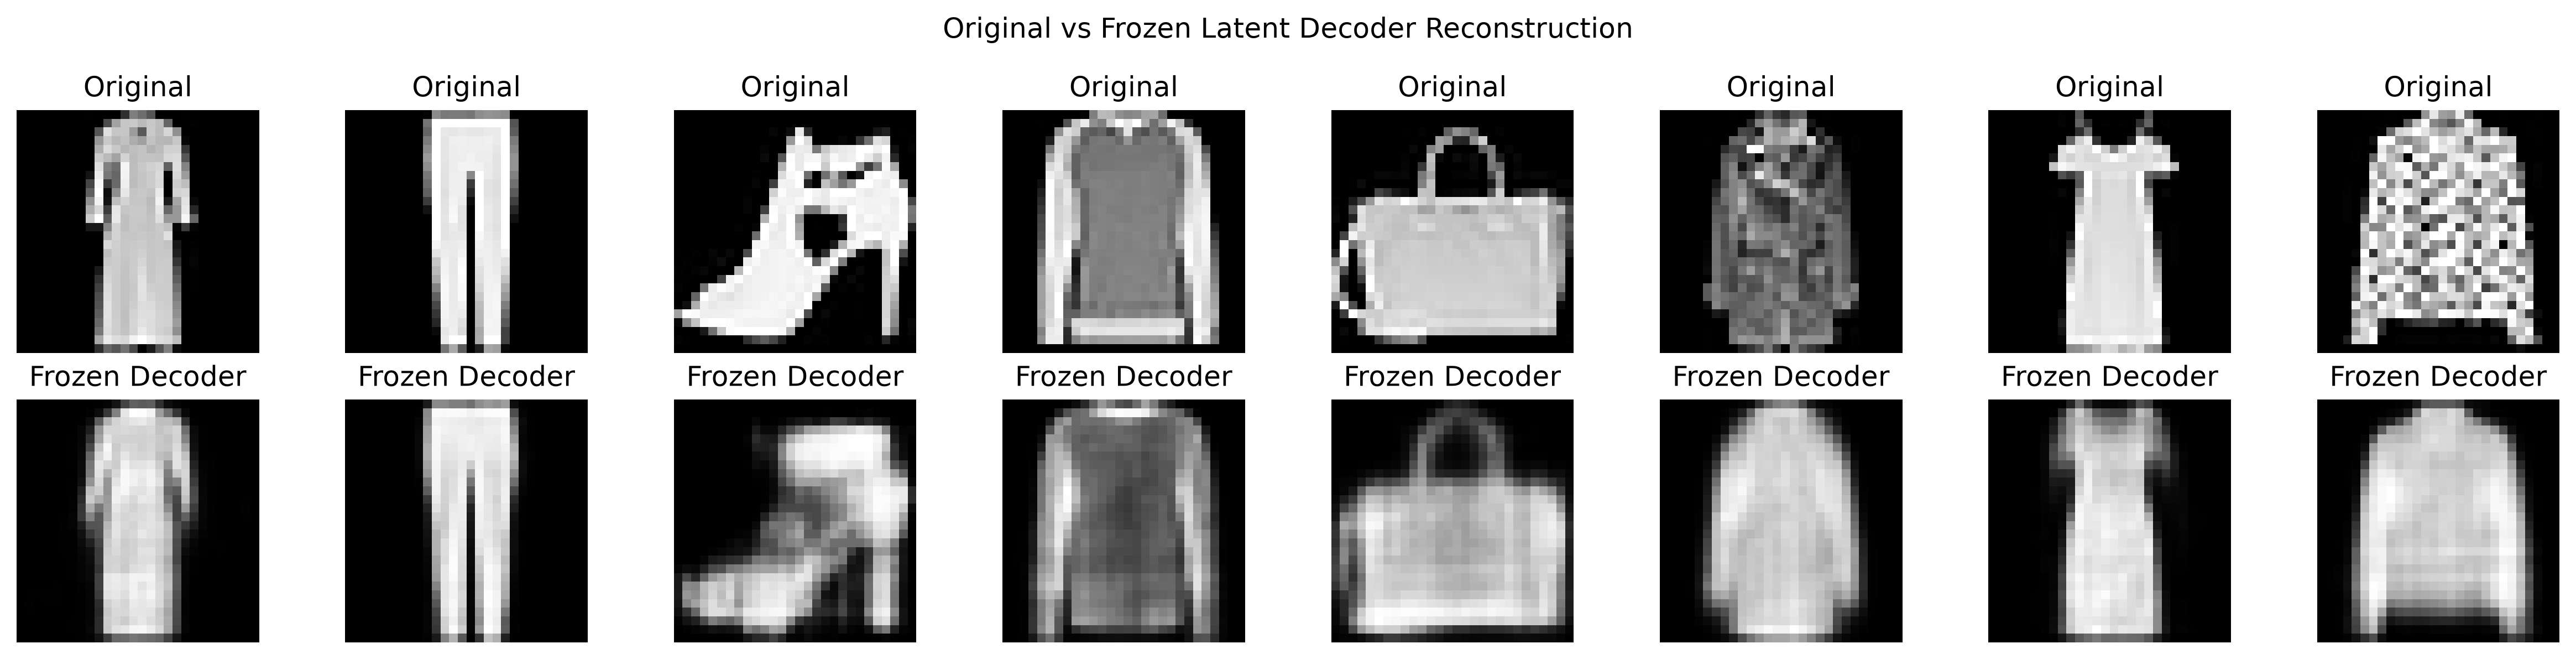


mlp_random_prior_sampling.png


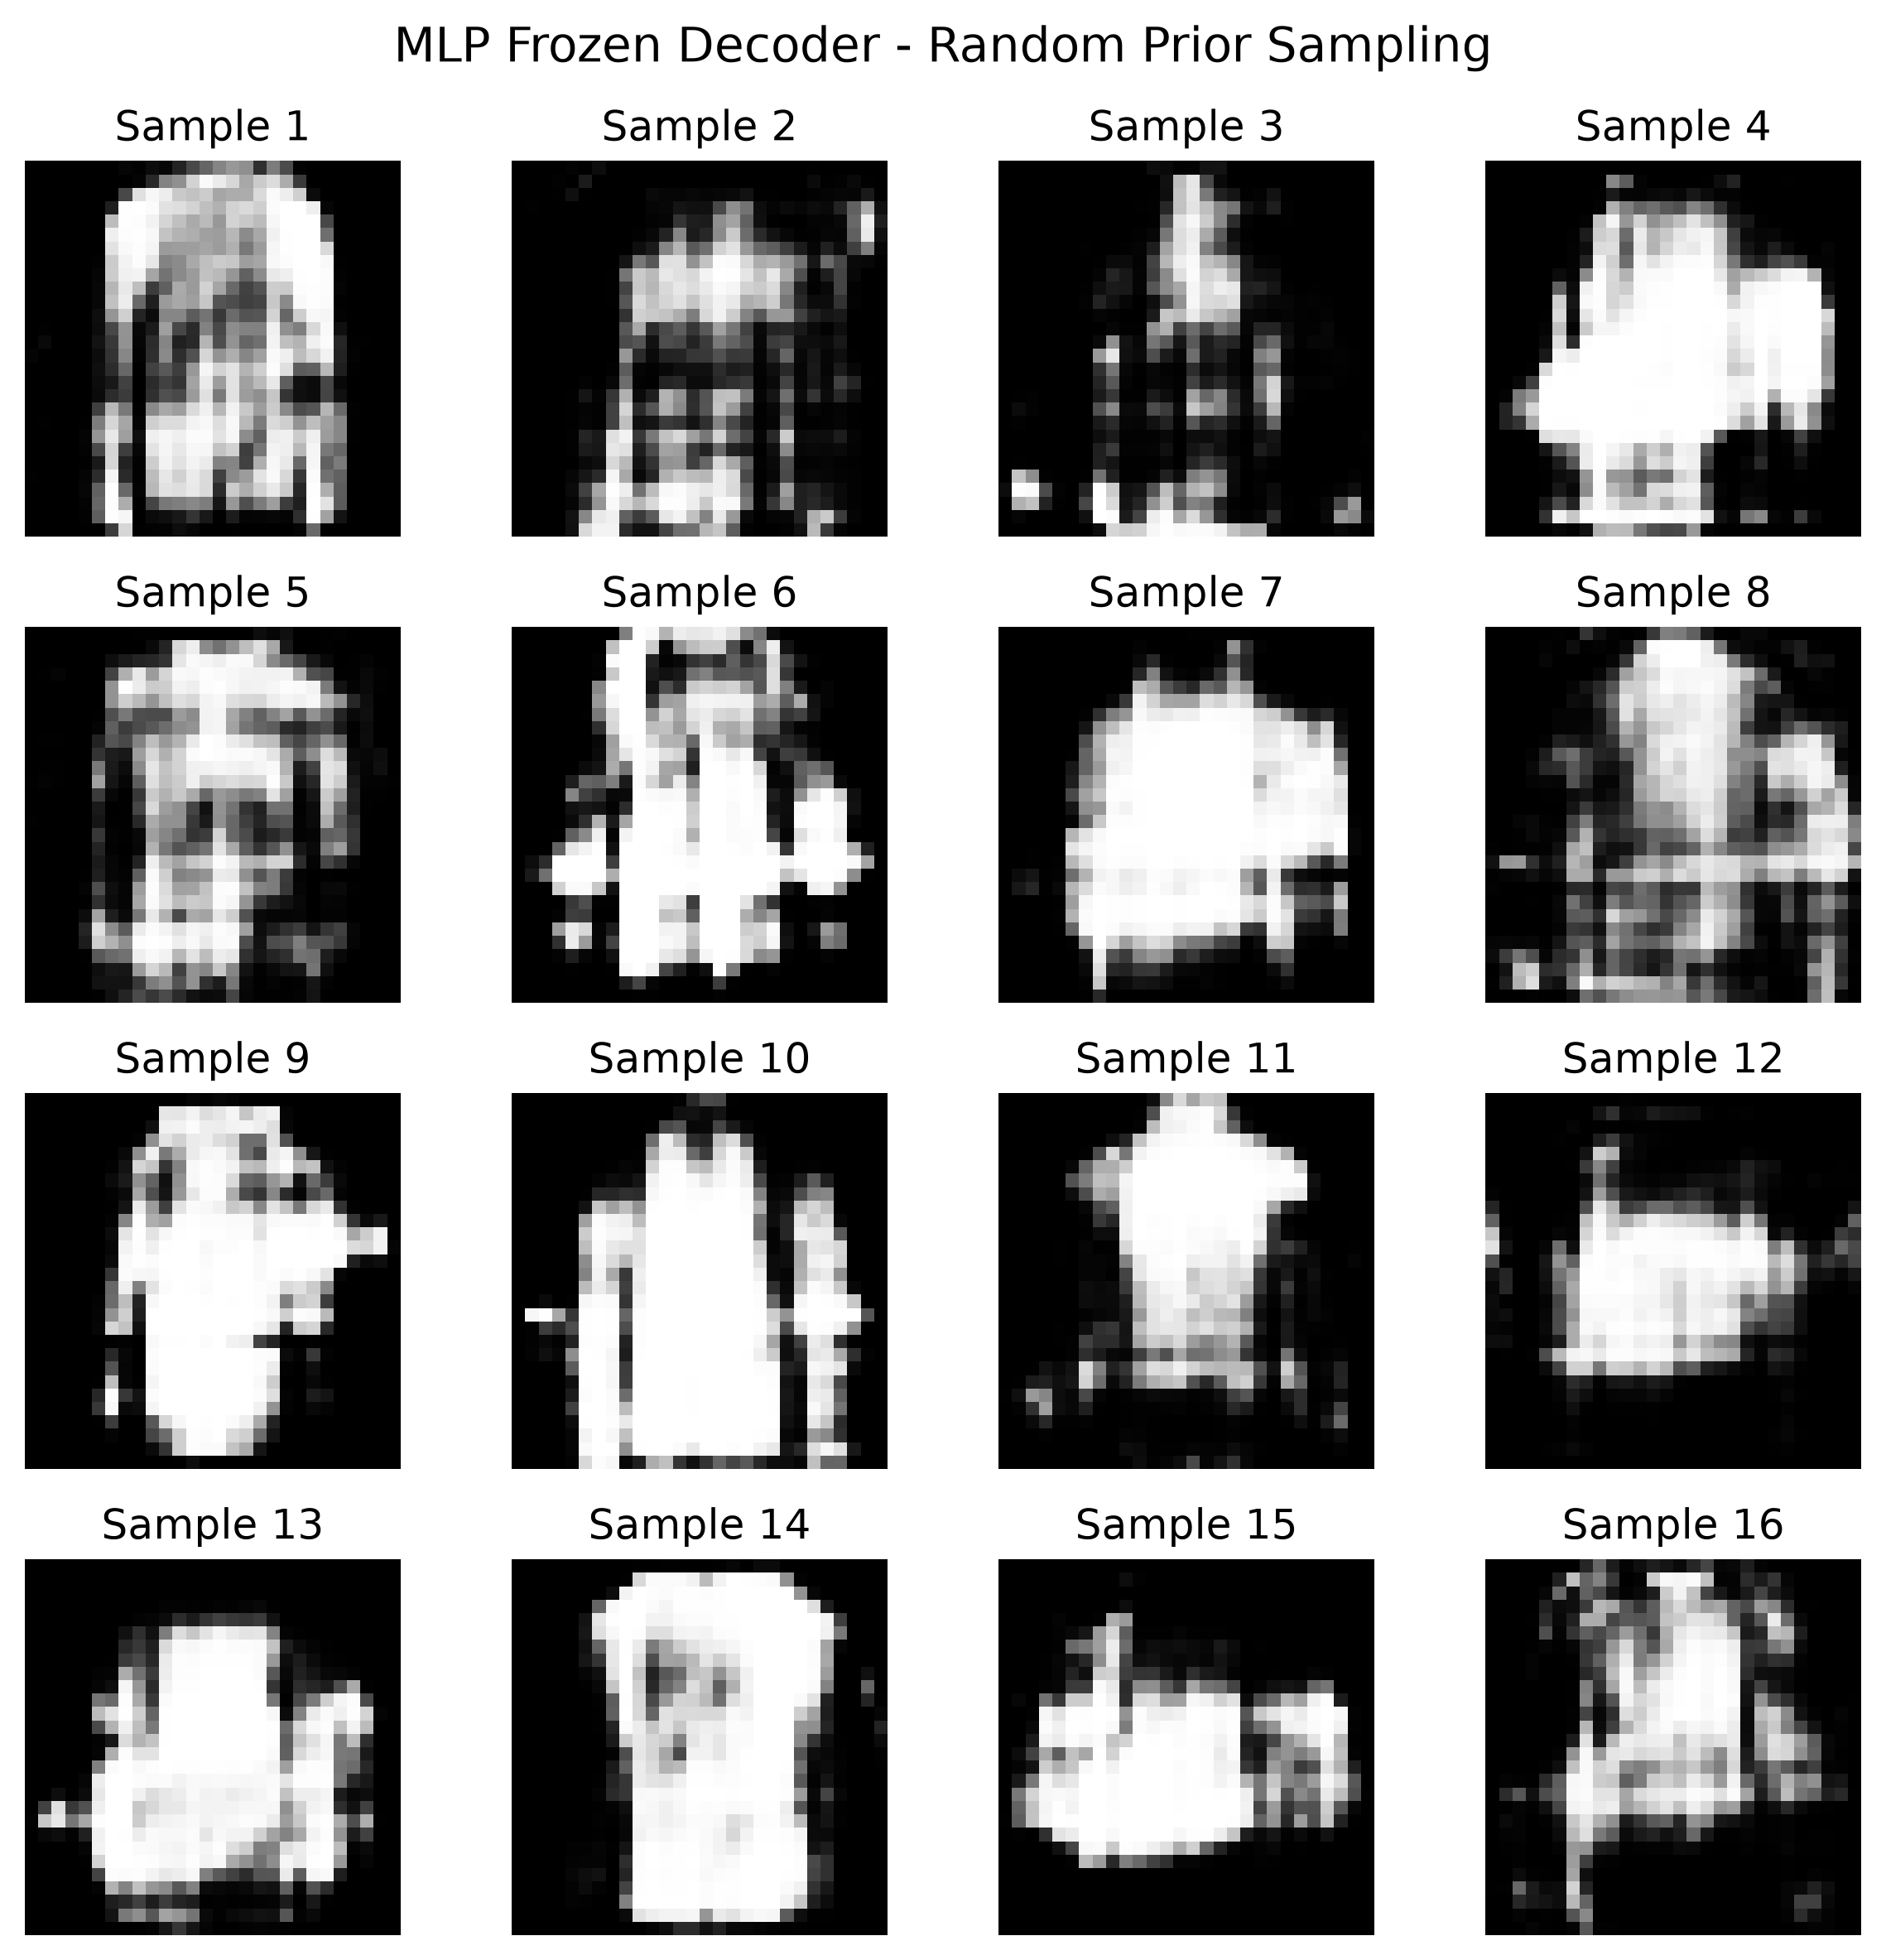


mlp_generation_limitation.png


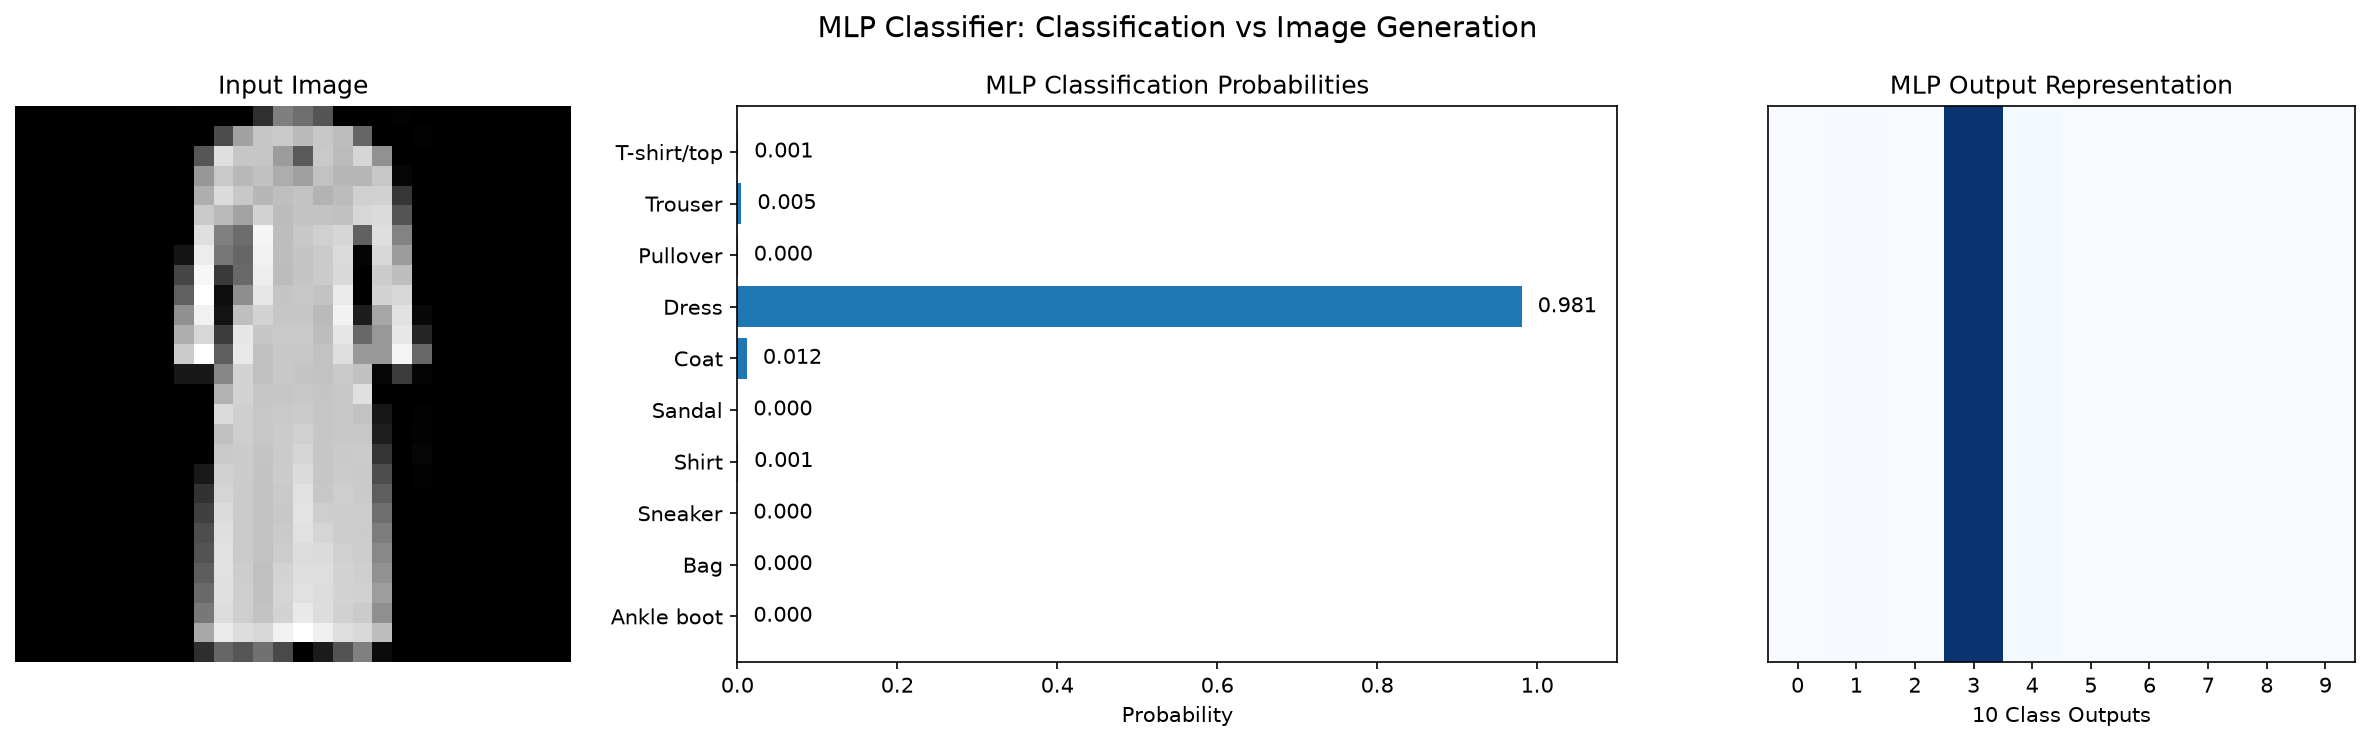

In [170]:
mlp_files = [
    "mlp_weight_transpose_projection.png",
    "mlp_latent_transpose_comparison.png",
    "mlp_frozen_decoder_reconstruction.png",
    "mlp_random_prior_sampling.png",
    "mlp_generation_limitation.png"
]

for filename in mlp_files:
    path = os.path.join(RESULTS_DIR, filename)

    print(f"\n{filename}")
    display(Image.open(path))

In [171]:
mlp_files = [
    "mlp_weight_transpose_projection.png",
    "mlp_latent_transpose_comparison.png",
    "mlp_frozen_decoder_reconstruction.png",
    "mlp_random_prior_sampling.png",
    "mlp_generation_limitation.png"
]

for filename in mlp_files:
    path = os.path.join(RESULTS_DIR, filename)
    img = Image.open(path)

    print(
        f"{filename} | "
        f"Size: {img.size} | "
        f"Mode: {img.mode}"
    )

mlp_weight_transpose_projection.png | Size: (3503, 1485) | Mode: RGBA
mlp_latent_transpose_comparison.png | Size: (4659, 1191) | Mode: RGBA
mlp_frozen_decoder_reconstruction.png | Size: (4659, 1191) | Mode: RGBA
mlp_random_prior_sampling.png | Size: (2278, 2367) | Mode: RGBA
mlp_generation_limitation.png | Size: (2369, 742) | Mode: RGBA


In [172]:
# Inspect available tensors for Figure 3
for name, value in globals().copy().items():
    if isinstance(value, torch.Tensor):
        if any(key in name.lower() for key in [
            "mlp", "reconstruct", "test_images", "random"
        ]):
            print(f"{name}: {tuple(value.shape)}")

test_images: (7000, 1, 28, 28)
reconstructed_images: (8, 1, 28, 28)
all_reconstructions: (7000, 1, 28, 28)
reconstructed: (1, 28, 28)
sparse_reconstructed: (8, 784)
vanilla_reconstructed: (8, 784)
reconstructed_without_relu: (8, 784)


In [173]:
files_to_check = [
    "vanilla_ae_reconstruction.png",
    "vanilla_ae_reconstructions.png",
    "mlp_frozen_decoder_reconstruction.png",
    "mlp_random_prior_sampling.png",
    "mlp_weight_transpose_projection.png",
    "mlp_latent_transpose_comparison.png"
]

for filename in files_to_check:
    path = os.path.join(RESULTS_DIR, filename)

    if os.path.exists(path):
        img = Image.open(path)
        print(f"{filename}: {img.size}")
    else:
        print(f"{filename}: NOT FOUND")

vanilla_ae_reconstruction.png: (2329, 595)
vanilla_ae_reconstructions.png: (1490, 372)
mlp_frozen_decoder_reconstruction.png: (4659, 1191)
mlp_random_prior_sampling.png: (2278, 2367)
mlp_weight_transpose_projection.png: (3503, 1485)
mlp_latent_transpose_comparison.png: (4659, 1191)


In [175]:
mlp_metrics_path = os.path.join(
    RESULTS_DIR,
    "mlp_experiment_results.csv"
)

if os.path.exists(mlp_metrics_path):
    mlp_metrics_df = pd.read_csv(mlp_metrics_path)
    display(mlp_metrics_df)
else:
    print("MLP metrics CSV not found.")

,Experiment,Metric,Result
0,MLP Classifier,Test Accuracy,89.5%
1,Direct Weight Transpose Projection,Generated Images,10 images
2,Latent Transpose Projection,Generated Images,7000 images
3,Frozen Latent Decoder,MSE / PSNR / SSIM,0.020743 / 17.6719 dB / 0.6311
4,Random Prior Sampling,Generated Images,16 images


In [178]:

comparison_images = test_images[:8].to(device)

vanilla_ae.eval()

with torch.no_grad():
    vanilla_ae_recon = vanilla_ae(
        comparison_images.view(8, 784)
    )

    if isinstance(vanilla_ae_recon, tuple):
        vanilla_ae_recon = vanilla_ae_recon[0]

    vanilla_ae_recon = vanilla_ae_recon.view(8, 1, 28, 28)

print("Ground Truth:", comparison_images.shape)
print("Vanilla AE:", vanilla_ae_recon.shape)

Ground Truth: torch.Size([8, 1, 28, 28])
Vanilla AE: torch.Size([8, 1, 28, 28])


In [181]:
print(mlp_classifier)

MLPClassifier(
  (layers): Sequential(
    (0): Linear(in_features=784, out_features=256, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=256, out_features=64, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.3, inplace=False)
    (6): Linear(in_features=64, out_features=10, bias=True)
  )
)


In [182]:
mlp_classifier.eval()

with torch.no_grad():
    x = test_images[:8].to(device).view(8, 784)

    z_mlp_comparison = mlp_classifier.layers[:5](x)

print("MLP Latent Shape:", z_mlp_comparison.shape)

MLP Latent Shape: torch.Size([8, 64])


In [183]:
mlp_frozen_decoder.eval()

with torch.no_grad():
    frozen_decoder_recon = mlp_frozen_decoder(
        z_mlp_comparison
    )

    frozen_decoder_recon = frozen_decoder_recon.view(8, 1, 28, 28)

print("Frozen Decoder:", frozen_decoder_recon.shape)
print("Vanilla AE:", vanilla_ae_recon.shape)

Frozen Decoder: torch.Size([8, 1, 28, 28])
Vanilla AE: torch.Size([8, 1, 28, 28])


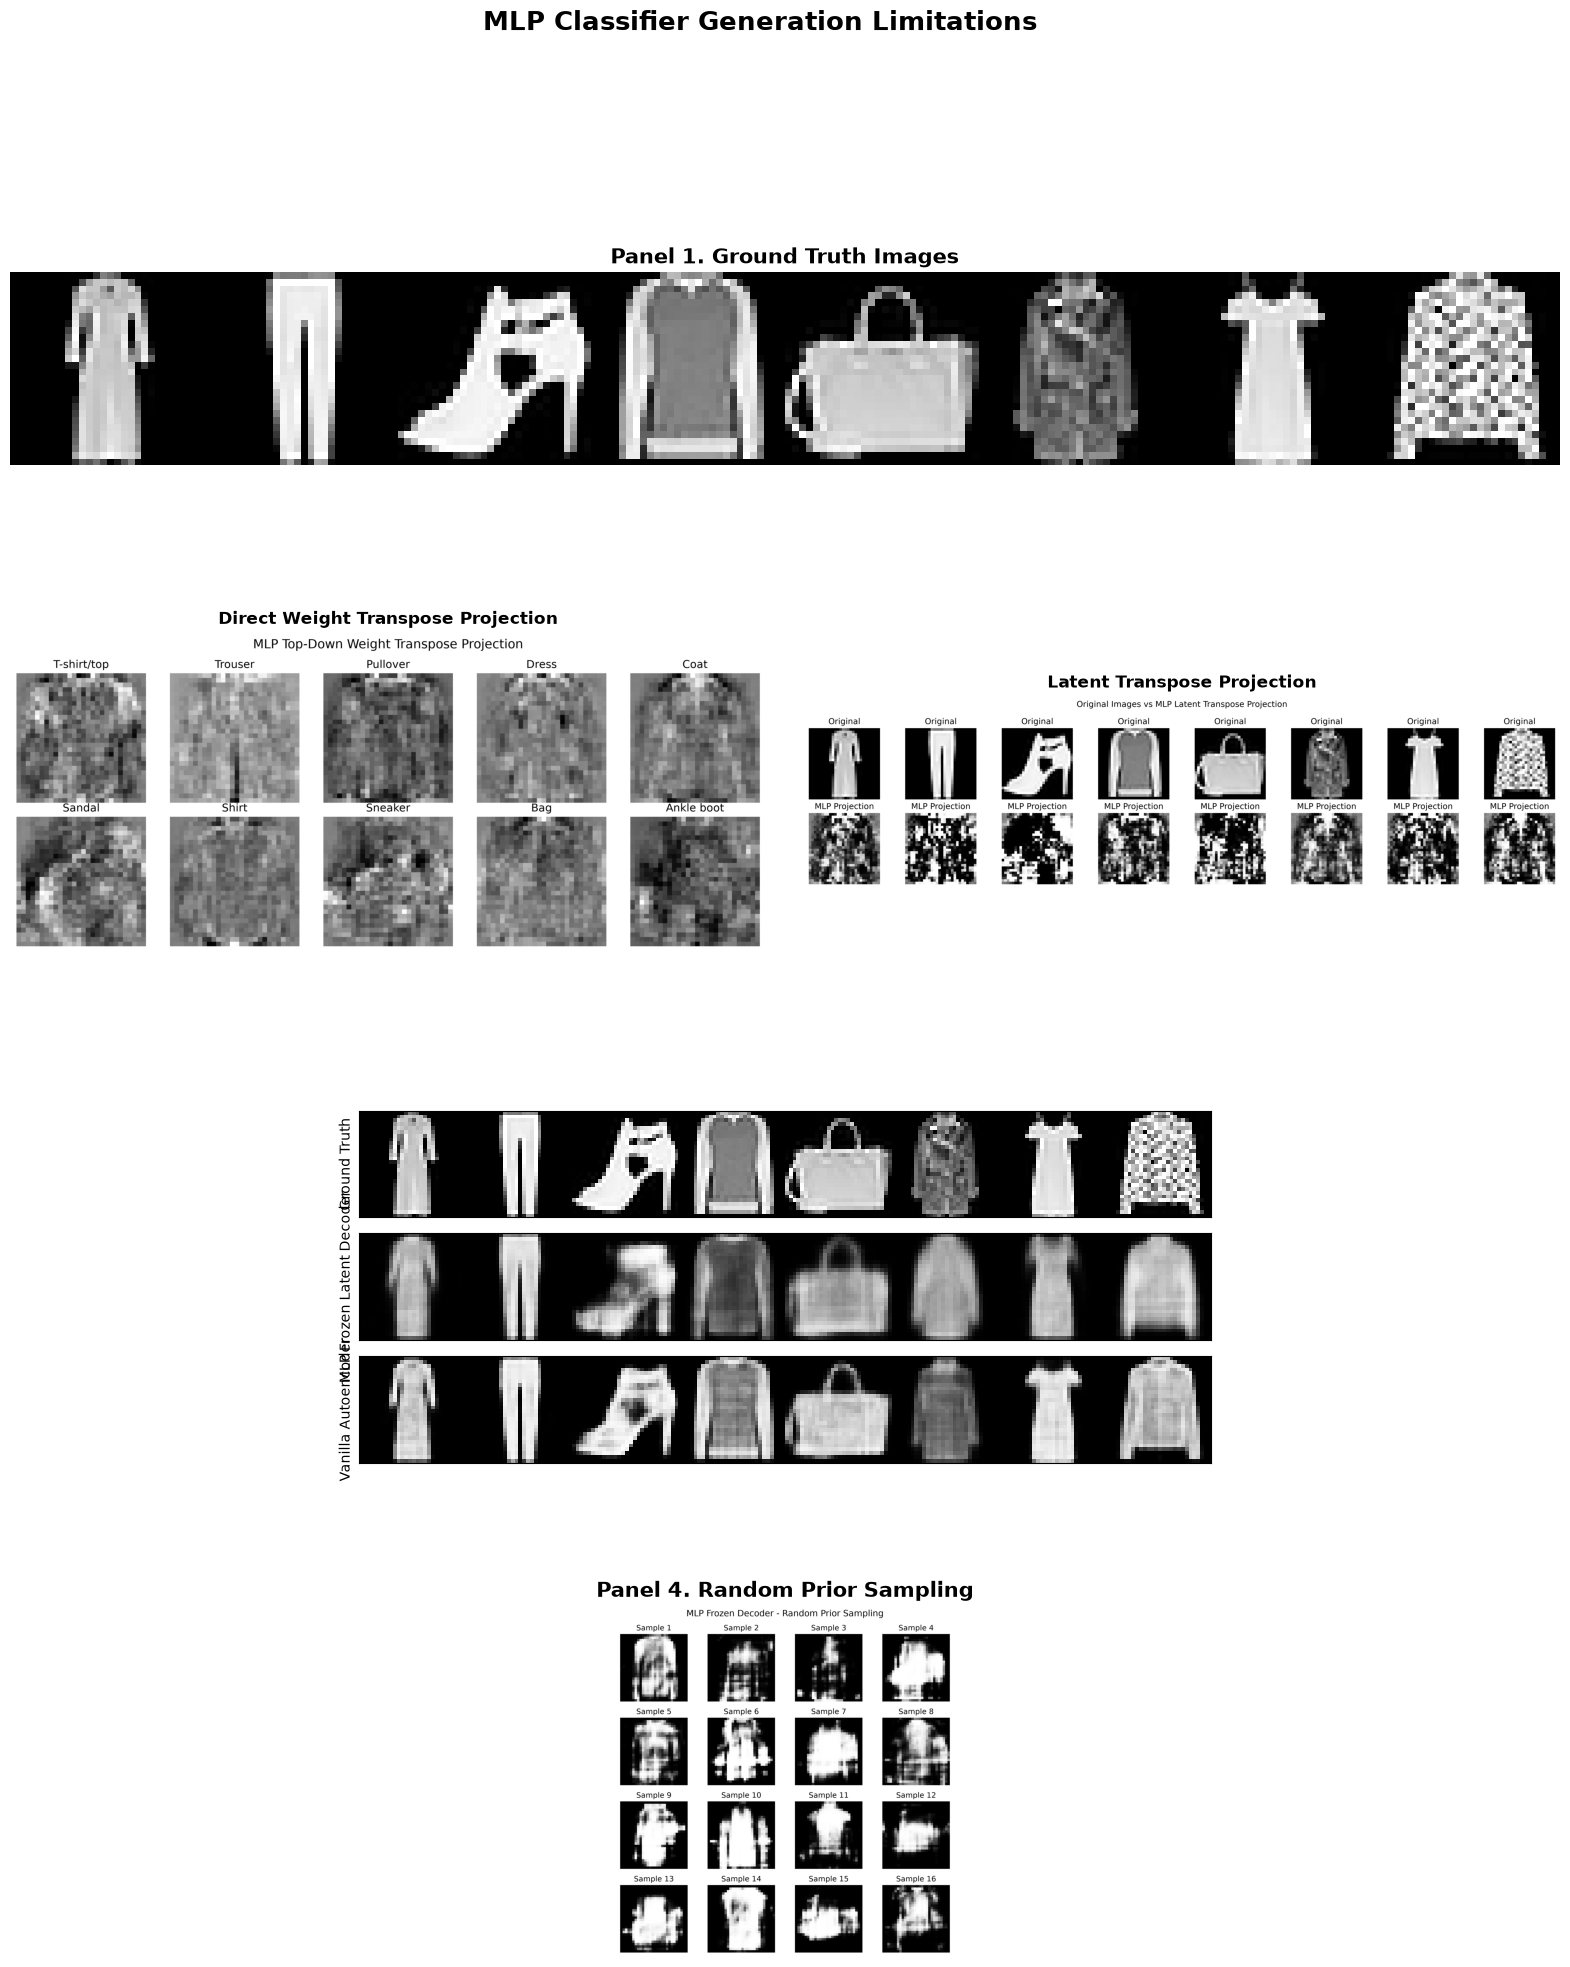

Figure 3 saved successfully.


In [184]:
from PIL import Image

direct_path = os.path.join(
    RESULTS_DIR, "mlp_weight_transpose_projection.png"
)
latent_path = os.path.join(
    RESULTS_DIR, "mlp_latent_transpose_comparison.png"
)
random_path = os.path.join(
    RESULTS_DIR, "mlp_random_prior_sampling.png"
)

# Create final 4-panel figure
fig = plt.figure(figsize=(20, 22))
gs = fig.add_gridspec(
    4, 1,
    height_ratios=[1.2, 2.0, 2.0, 2.0],
    hspace=0.45
)

# PANEL 1: Ground Truth
ax1 = fig.add_subplot(gs[0])
ax1.set_title(
    "Panel 1. Ground Truth Images",
    fontsize=15, fontweight="bold"
)

ax1.imshow(
    np.concatenate(
        comparison_images.detach().cpu().numpy(),
        axis=2
    ).squeeze(),
    cmap="gray",
    vmin=0,
    vmax=1
)
ax1.axis("off")

# PANEL 2: MLP Transpose Projection
sub2 = gs[1].subgridspec(1, 2, wspace=0.05)

ax2a = fig.add_subplot(sub2[0])
ax2a.imshow(Image.open(direct_path))
ax2a.set_title(
    "Direct Weight Transpose Projection",
    fontsize=12,
    fontweight="bold"
)
ax2a.axis("off")

ax2b = fig.add_subplot(sub2[1])
ax2b.imshow(Image.open(latent_path))
ax2b.set_title(
    "Latent Transpose Projection",
    fontsize=12,
    fontweight="bold"
)
ax2b.axis("off")

# PANEL 3: Frozen Decoder vs Vanilla AE
sub3 = gs[2].subgridspec(3, 1, hspace=0.15)

reconstruction_groups = [
    ("Ground Truth", comparison_images),
    ("MLP Frozen Latent Decoder", frozen_decoder_recon),
    ("Vanilla Autoencoder", vanilla_ae_recon)
]

for i, (label, images) in enumerate(reconstruction_groups):
    ax = fig.add_subplot(sub3[i])
    grid = np.concatenate(
        images.detach().cpu().numpy(),
        axis=2
    ).squeeze()

    ax.imshow(grid, cmap="gray", vmin=0, vmax=1)
    ax.set_ylabel(label, fontsize=10)
    ax.set_xticks([])
    ax.set_yticks([])

# PANEL 4: Random Prior Sampling
ax4 = fig.add_subplot(gs[3])
ax4.imshow(Image.open(random_path))
ax4.set_title(
    "Panel 4. Random Prior Sampling",
    fontsize=15,
    fontweight="bold"
)
ax4.axis("off")

fig.suptitle(
    "MLP Classifier Generation Limitations",
    fontsize=19,
    fontweight="bold",
    y=0.995
)

plt.savefig(
    os.path.join(
        RESULTS_DIR, "mlp_generation_limitation.png"
    ),
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Figure 3 saved successfully.")

In [185]:
print("First endpoint label:", test_labels[0].item())
print("Second endpoint label:", test_labels[10].item())

First endpoint label: 3
Second endpoint label: 4


In [186]:
training_curve_files = [
    "vanilla_ae_training_curves.png",
    "sparse_ae_training_curves.png",
    "vae_training_curves.png",
    "vanilla_gan_training_curves.png",
    "dcgan_training_curves.png",
    "ddpm_training_curves.png"
]

for filename in training_curve_files:
    path = os.path.join(RESULTS_DIR, filename)

    if os.path.exists(path):
        img = Image.open(path)
        print(f"{filename}: {img.size}")
    else:
        print(f"{filename}: NOT FOUND")

vanilla_ae_training_curves.png: (1000, 500)
sparse_ae_training_curves.png: (1000, 500)
vae_training_curves.png: (990, 490)
vanilla_gan_training_curves.png: (990, 490)
dcgan_training_curves.png: (1000, 500)
ddpm_training_curves.png: (4170, 1485)


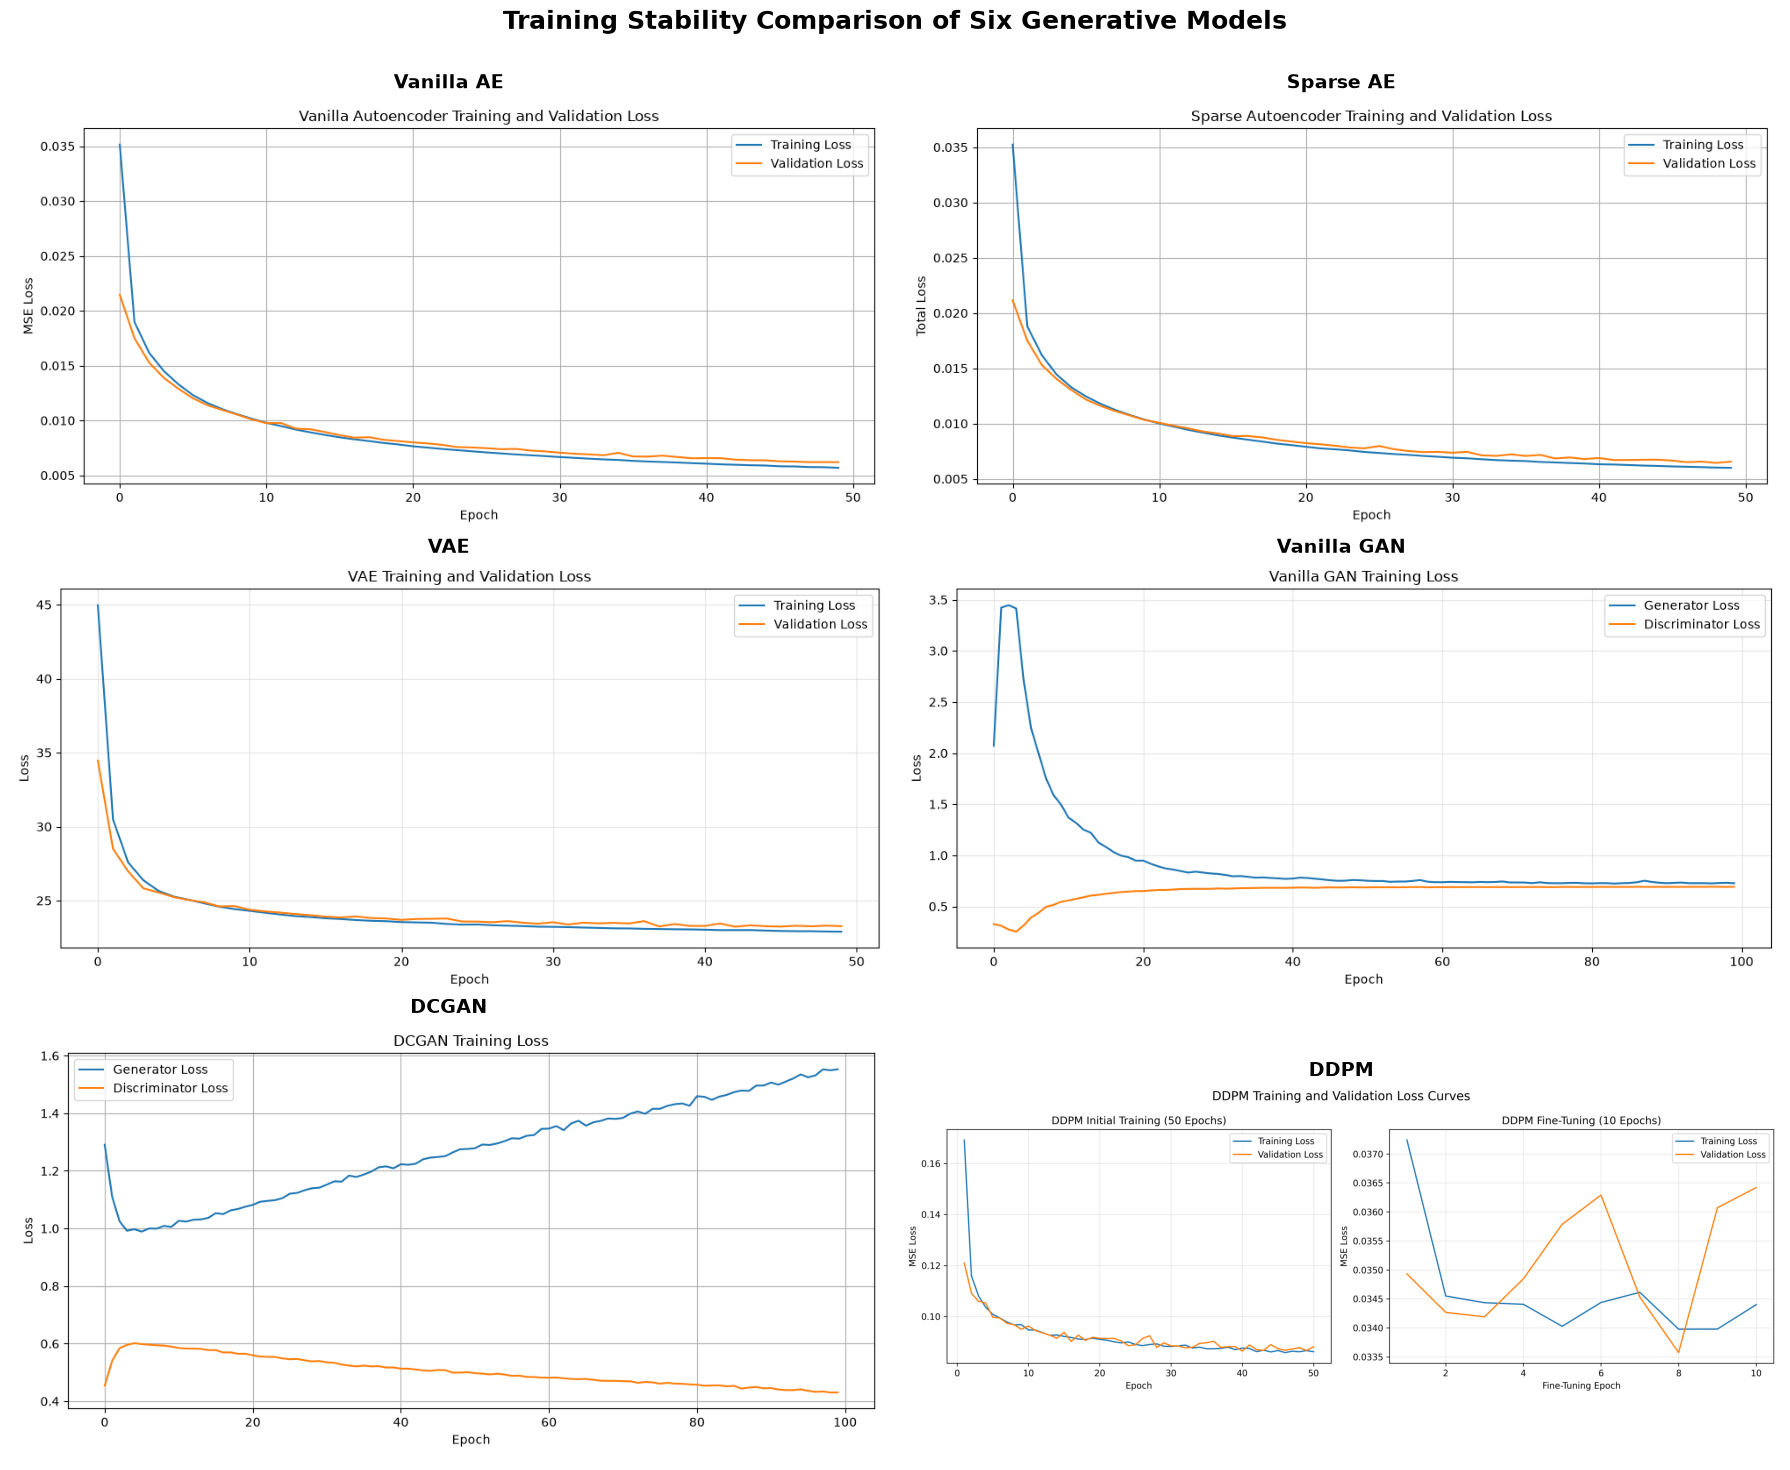

In [187]:


training_curve_files = [
    ("Vanilla AE", "vanilla_ae_training_curves.png"),
    ("Sparse AE", "sparse_ae_training_curves.png"),
    ("VAE", "vae_training_curves.png"),
    ("Vanilla GAN", "vanilla_gan_training_curves.png"),
    ("DCGAN", "dcgan_training_curves.png"),
    ("DDPM", "ddpm_training_curves.png")
]

fig, axes = plt.subplots(3, 2, figsize=(18, 15))

for ax, (title, filename) in zip(axes.flatten(), training_curve_files):
    image_path = os.path.join(RESULTS_DIR, filename)
    img = Image.open(image_path)

    ax.imshow(img)
    ax.set_title(title, fontsize=14, fontweight="bold")
    ax.axis("off")

fig.suptitle(
    "Training Stability Comparison of Six Generative Models",
    fontsize=18,
    fontweight="bold"
)

plt.tight_layout(rect=[0, 0, 1, 0.97])

plt.savefig(
    os.path.join(RESULTS_DIR, "training_stability_all_models.png"),
    dpi=200,
    bbox_inches="tight"
)

plt.show()



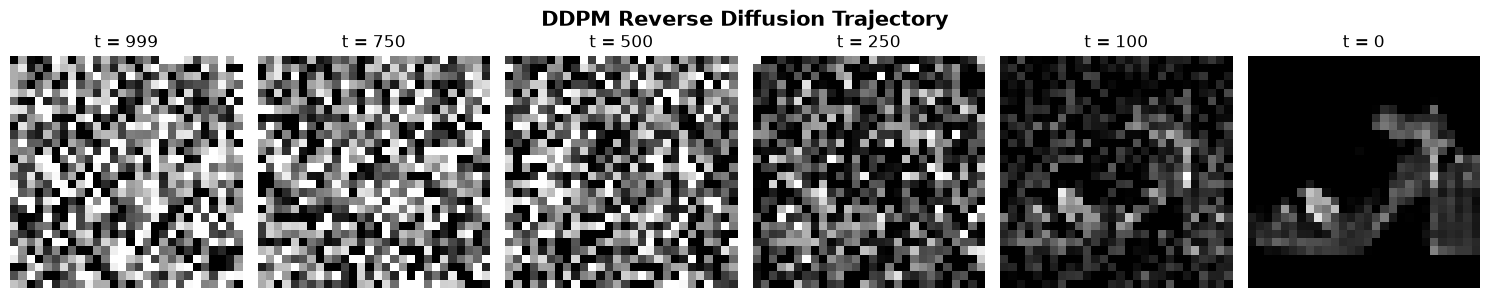

In [190]:

unet.eval()

snapshot_steps = [999, 750, 500, 250, 100, 0]
snapshots = {}

x = torch.randn(1, 1, 28, 28, device=device)

with torch.no_grad():
    for t in reversed(range(TIMESTEPS)):

        t_tensor = torch.full(
            (1,), t, device=device, dtype=torch.long
        )

        predicted_noise = unet(x, t_tensor)

        alpha_t = alphas[t]
        alpha_bar_t = alpha_bars[t]
        beta_t = betas[t]

        noise = torch.randn_like(x) if t > 0 else torch.zeros_like(x)

        x = (
            1 / torch.sqrt(alpha_t)
        ) * (
            x - (beta_t / torch.sqrt(1 - alpha_bar_t)) * predicted_noise
        ) + torch.sqrt(beta_t) * noise

        if t in snapshot_steps:
            snapshots[t] = x.detach().cpu().clone()

fig, axes = plt.subplots(1, 6, figsize=(15, 3))

for ax, t in zip(axes, snapshot_steps):
    image = snapshots[t][0, 0].numpy()

    image = (image + 1) / 2
    image = image.clip(0, 1)

    ax.imshow(image, cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"t = {t}")
    ax.axis("off")

fig.suptitle(
    "DDPM Reverse Diffusion Trajectory",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    os.path.join(RESULTS_DIR, "ddpm_reverse_diffusion_trajectory.png"),
    dpi=200,
    bbox_inches="tight"
)

plt.show()



In [191]:
comparison_df = pd.read_csv(
    os.path.join(RESULTS_DIR, "final_comparison_table.csv")
)

print("Current columns:")
print(comparison_df.columns.tolist())

display(comparison_df)

Current columns:
['Model', 'MSE', 'PSNR (dB)', 'SSIM', 'FID', 'Inference Latency (ms)']


,Model,MSE,PSNR (dB),SSIM,FID,Inference Latency (ms)
0,Vanilla AE,0.006143,23.3536,0.8367,NaN,0.99027
1,Sparse AE,0.006198,23.3206,0.8353,NaN,0.94559
2,VAE,0.019956,17.6005,0.6273,153.088649,0.92610
3,Vanilla GAN,NaN,NaN,NaN,213.906434,0.88210
4,DCGAN,NaN,NaN,NaN,107.431360,2.59628
5,DDPM,NaN,NaN,NaN,126.321516,198408.11980


In [192]:
latent_dimensions = {
    "Vanilla AE": "64",
    "Sparse AE": "64",
    "VAE": "64",
    "Vanilla GAN": "100",
    "DCGAN": "100",
    "DDPM": "1x28x28 (784)"
}

comparison_df["Latent Dimension"] = (
    comparison_df["Model"].map(latent_dimensions)
)

comparison_df["Training Time per Epoch (s)"] = "N/A"

stability_notes = {
    "Vanilla AE": "Refer to training loss curve",
    "Sparse AE": "Refer to training loss curve",
    "VAE": "Refer to training loss curve",
    "Vanilla GAN": "Refer to generator/discriminator loss curves",
    "DCGAN": "Refer to generator/discriminator loss curves",
    "DDPM": "Refer to training and validation loss curves"
}

comparison_df["Training Stability"] = (
    comparison_df["Model"].map(stability_notes)
)

comparison_df = comparison_df[
    [
        "Model",
        "Latent Dimension",
        "Training Time per Epoch (s)",
        "Inference Latency (ms)",
        "MSE",
        "PSNR (dB)",
        "SSIM",
        "FID",
        "Training Stability"
    ]
]

comparison_path = os.path.join(
    RESULTS_DIR, "final_comparison_table.csv"
)

comparison_df.to_csv(comparison_path, index=False)

display(comparison_df)

print("\nSaved:", comparison_path)

,Model,Latent Dimension,Training Time per Epoch (s),Inference Latency (ms),MSE,PSNR (dB),SSIM,FID,Training Stability
0,Vanilla AE,64,N/A,0.99027,0.006143,23.3536,0.8367,NaN,Refer to training loss curve
1,Sparse AE,64,N/A,0.94559,0.006198,23.3206,0.8353,NaN,Refer to training loss curve
2,VAE,64,N/A,0.92610,0.019956,17.6005,0.6273,153.088649,Refer to training loss curve
3,Vanilla GAN,100,N/A,0.88210,NaN,NaN,NaN,213.906434,Refer to generator/discriminator loss curves
4,DCGAN,100,N/A,2.59628,NaN,NaN,NaN,107.431360,Refer to generator/discriminator loss curves
5,DDPM,1x28x28 (784),N/A,198408.11980,NaN,NaN,NaN,126.321516,Refer to training and validation loss curves



Saved: D:\generative-models-comparison\results\final_comparison_table.csv


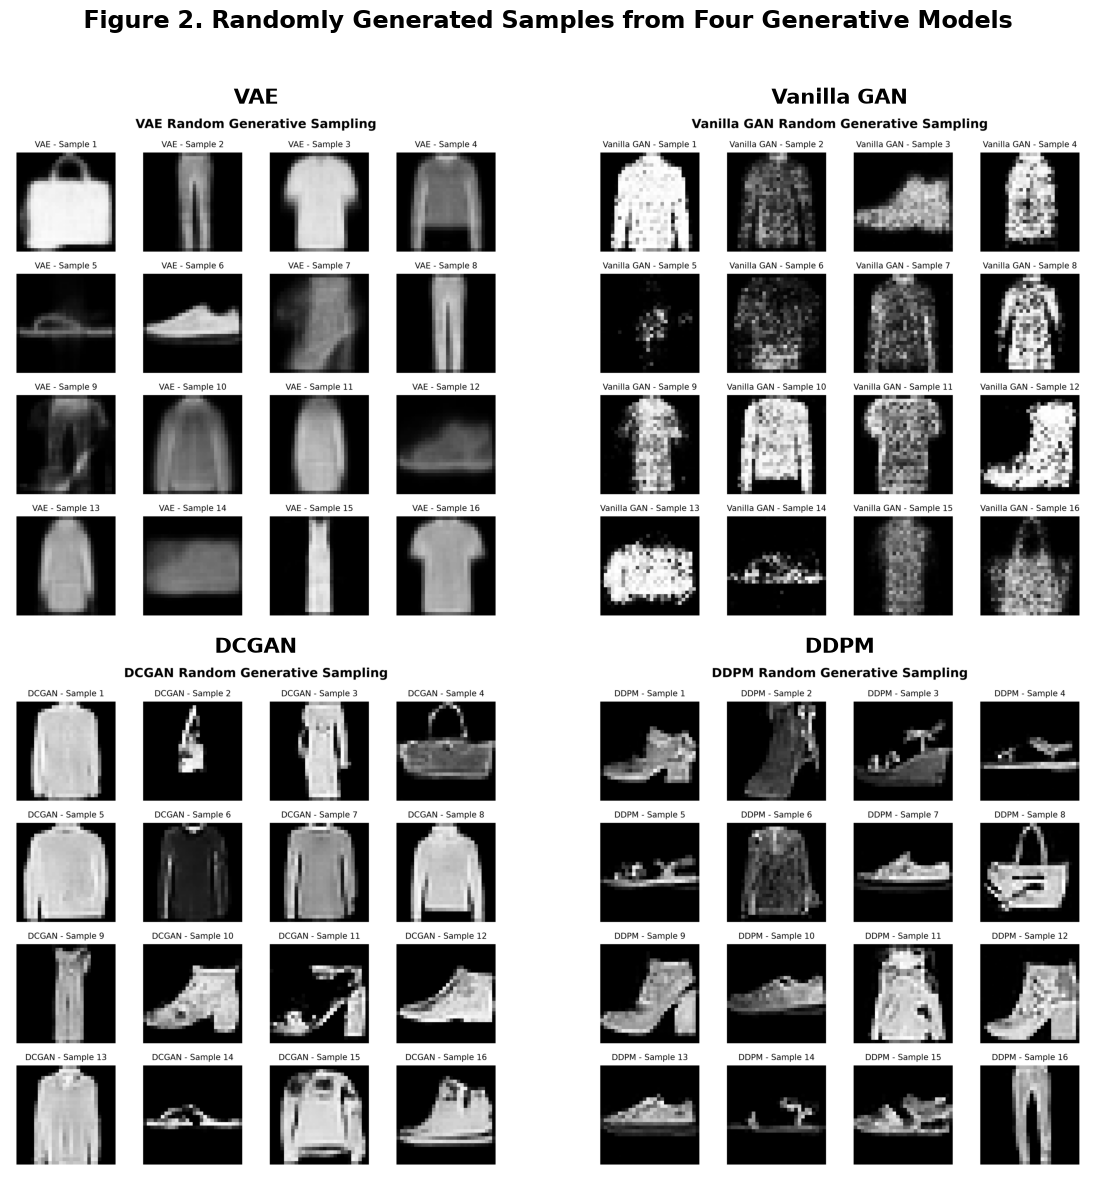

Figure 2 saved: D:\generative-models-comparison\results\figure2_generated_samples_comparison.png


In [194]:
import os
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

sample_files = {
    "VAE": "vae_random_samples.png",
    "Vanilla GAN": "vanilla_gan_random_samples.png",
    "DCGAN": "dcgan_random_samples.png",
    "DDPM": "ddpm_random_samples.png"
}

fig, axes = plt.subplots(2, 2, figsize=(12, 12))

for ax, (model_name, filename) in zip(axes.flat, sample_files.items()):
    image_path = os.path.join(RESULTS_DIR, filename)

    if not os.path.exists(image_path):
        raise FileNotFoundError(f"Missing file: {image_path}")

    image = mpimg.imread(image_path)
    ax.imshow(image, cmap="gray")
    ax.set_title(model_name, fontsize=15, fontweight="bold")
    ax.axis("off")

fig.suptitle(
    "Figure 2. Randomly Generated Samples from Four Generative Models",
    fontsize=17,
    fontweight="bold"
)

plt.tight_layout(rect=[0, 0, 1, 0.96])

figure2_path = os.path.join(
    RESULTS_DIR, "figure2_generated_samples_comparison.png"
)

plt.savefig(figure2_path, dpi=300, bbox_inches="tight")
plt.show()

print("Figure 2 saved:", figure2_path)

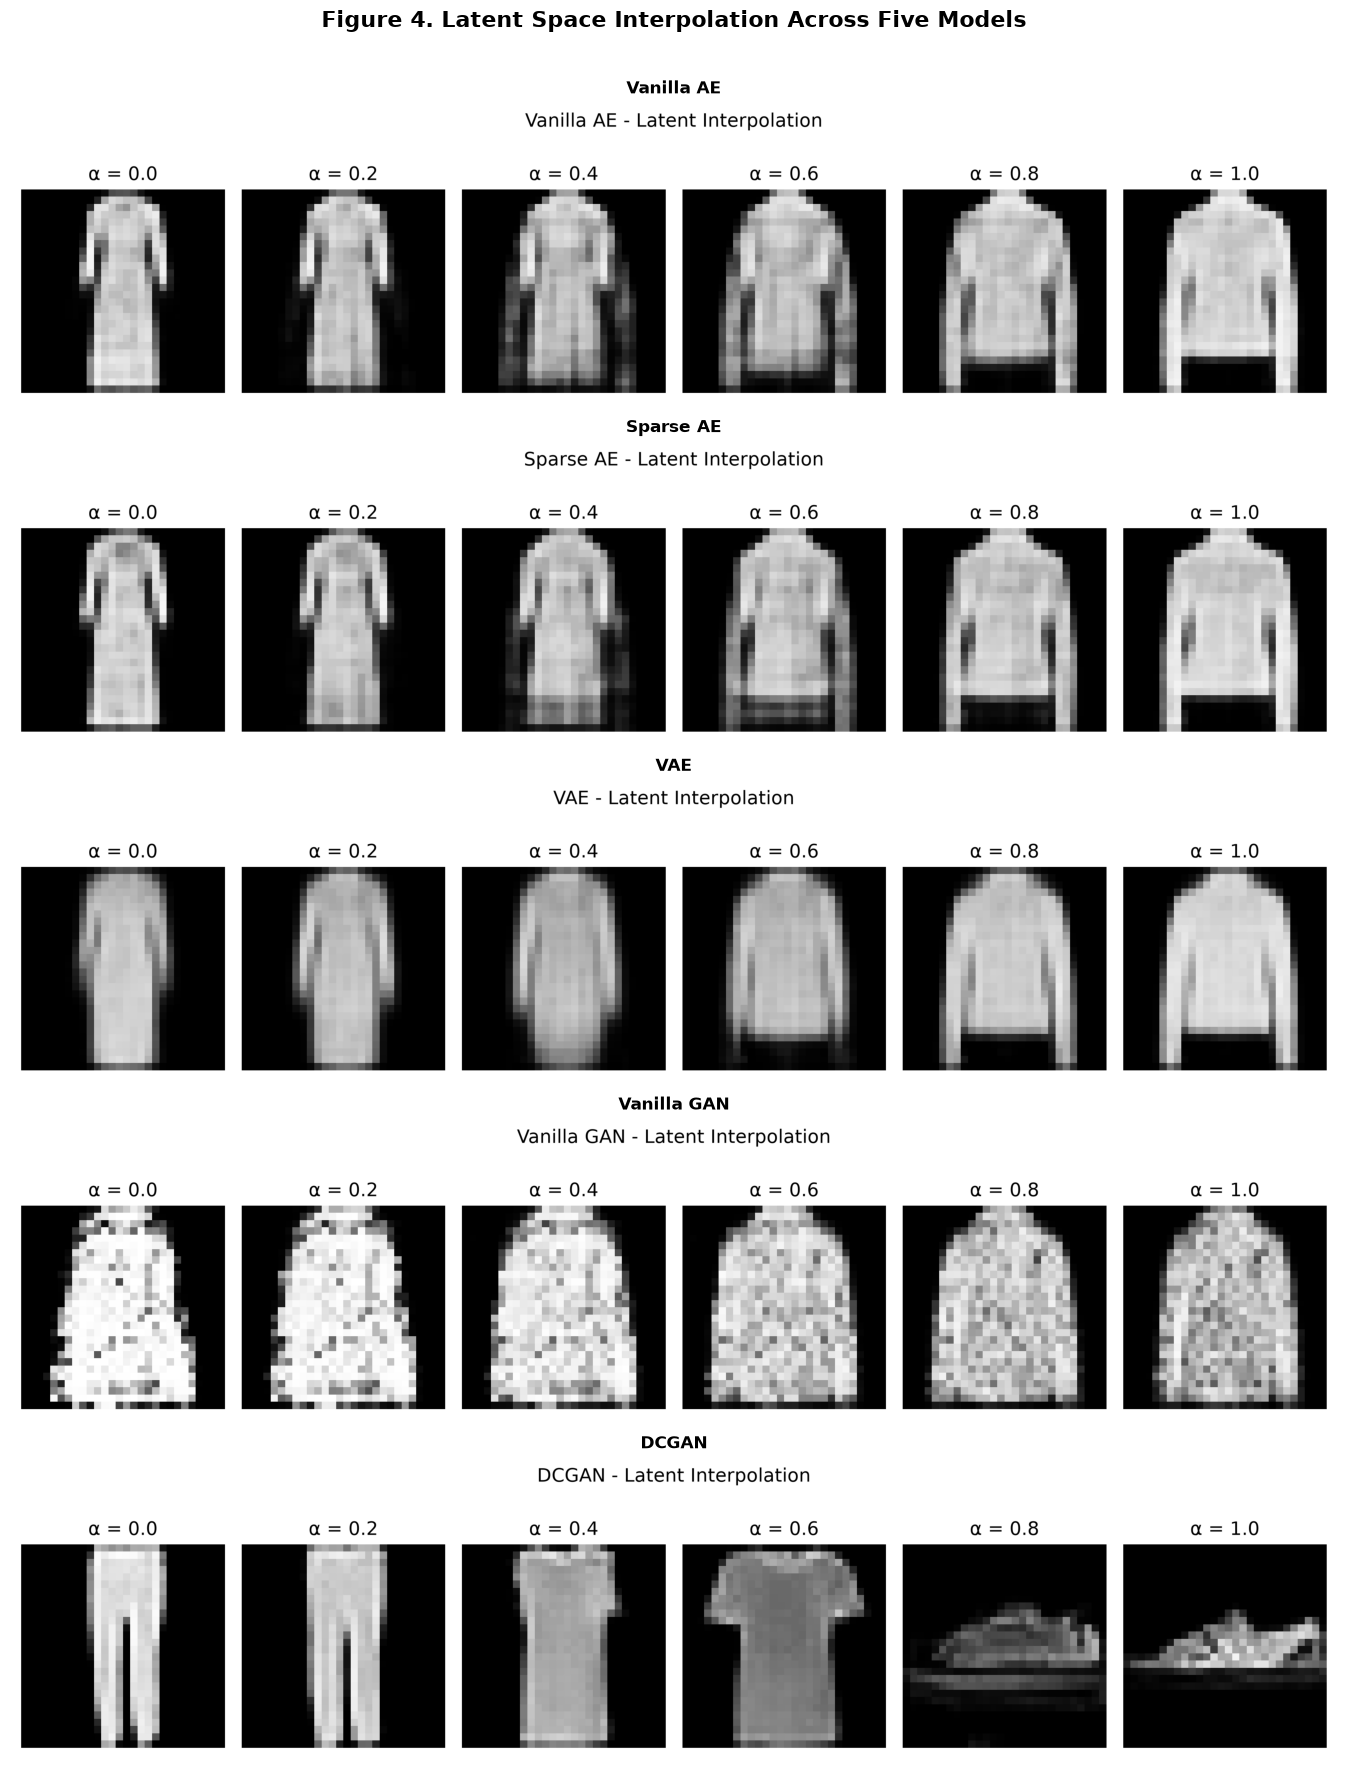

Figure 4 saved: D:\generative-models-comparison\results\figure4_latent_interpolation_comparison.png


In [195]:


interpolation_files = {
    "Vanilla AE": "vanilla_ae_interpolation.png",
    "Sparse AE": "sparse_ae_interpolation.png",
    "VAE": "vae_interpolation.png",
    "Vanilla GAN": "vanilla_gan_interpolation.png",
    "DCGAN": "dcgan_interpolation.png"
}

fig, axes = plt.subplots(5, 1, figsize=(14, 18))

for ax, (model_name, filename) in zip(axes, interpolation_files.items()):
    image_path = os.path.join(RESULTS_DIR, filename)

    if not os.path.exists(image_path):
        raise FileNotFoundError(f"Missing file: {image_path}")

    image = mpimg.imread(image_path)
    ax.imshow(image, cmap="gray")
    ax.set_title(model_name, fontsize=12, fontweight="bold")
    ax.axis("off")

fig.suptitle(
    "Figure 4. Latent Space Interpolation Across Five Models",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout(rect=[0, 0, 1, 0.97])

figure4_path = os.path.join(
    RESULTS_DIR, "figure4_latent_interpolation_comparison.png"
)

plt.savefig(figure4_path, dpi=300, bbox_inches="tight")
plt.show()

print("Figure 4 saved:", figure4_path)

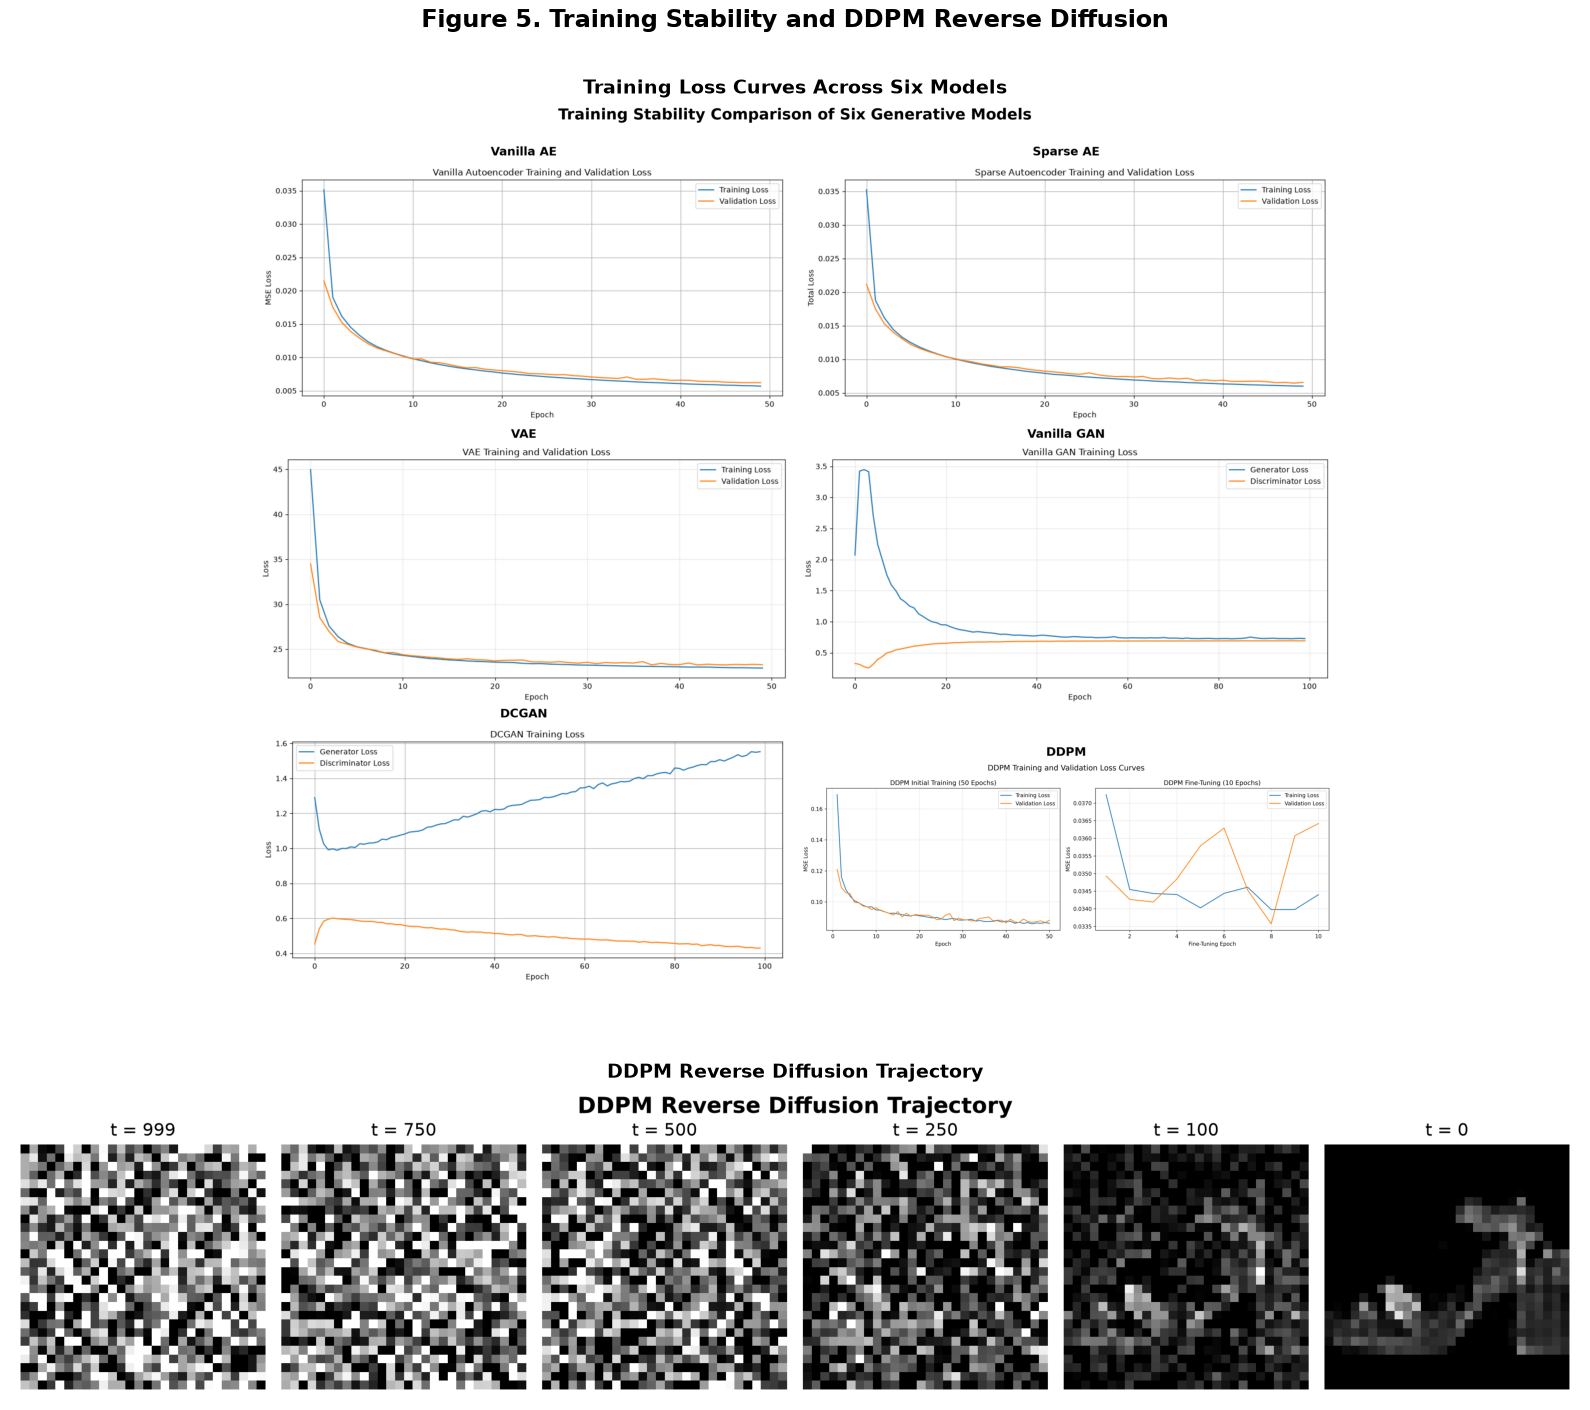

Figure 5 saved: D:\generative-models-comparison\results\figure5_training_stability_and_diffusion.png


In [196]:

curve_path = os.path.join(
    RESULTS_DIR, "training_stability_all_models.png"
)

reverse_path = os.path.join(
    RESULTS_DIR, "ddpm_reverse_diffusion_trajectory.png"
)

for path in [curve_path, reverse_path]:
    if not os.path.exists(path):
        raise FileNotFoundError(f"Missing file: {path}")

curve_image = mpimg.imread(curve_path)
reverse_image = mpimg.imread(reverse_path)

fig, axes = plt.subplots(
    2, 1,
    figsize=(16, 16),
    gridspec_kw={"height_ratios": [1.4, 1]}
)

axes[0].imshow(curve_image)
axes[0].set_title(
    "Training Loss Curves Across Six Models",
    fontsize=14,
    fontweight="bold"
)
axes[0].axis("off")

axes[1].imshow(reverse_image)
axes[1].set_title(
    "DDPM Reverse Diffusion Trajectory",
    fontsize=14,
    fontweight="bold"
)
axes[1].axis("off")

fig.suptitle(
    "Figure 5. Training Stability and DDPM Reverse Diffusion",
    fontsize=17,
    fontweight="bold"
)

plt.tight_layout(rect=[0, 0, 1, 0.97])

figure5_path = os.path.join(
    RESULTS_DIR, "figure5_training_stability_and_diffusion.png"
)

plt.savefig(figure5_path, dpi=300, bbox_inches="tight")
plt.show()

print("Figure 5 saved:", figure5_path)

In [197]:


required_files = [
    "reconstruction_comparison.png",
    "figure2_generated_samples_comparison.png",
    "mlp_generation_limitation.png",
    "figure4_latent_interpolation_comparison.png",
    "figure5_training_stability_and_diffusion.png",
    "final_comparison_table.csv",
    "fid_metrics.csv",
    "reconstruction_metrics.csv",
    "inference_latency.csv",
    "mlp_experiment_results.csv"
]

print("=== FINAL EXPERIMENT AUDIT ===")

all_exist = True

for filename in required_files:
    path = os.path.join(RESULTS_DIR, filename)
    exists = os.path.exists(path)

    print(f"[{'OK' if exists else 'MISSING'}] {filename}")

    if not exists:
        all_exist = False

print("\nAll required files available:", all_exist)

# Display final comparison table
comparison_df = pd.read_csv(
    os.path.join(RESULTS_DIR, "final_comparison_table.csv")
)

display(comparison_df)

=== FINAL EXPERIMENT AUDIT ===
[OK] reconstruction_comparison.png
[OK] figure2_generated_samples_comparison.png
[OK] mlp_generation_limitation.png
[OK] figure4_latent_interpolation_comparison.png
[OK] figure5_training_stability_and_diffusion.png
[OK] final_comparison_table.csv
[OK] fid_metrics.csv
[OK] reconstruction_metrics.csv
[OK] inference_latency.csv
[OK] mlp_experiment_results.csv

All required files available: True


,Model,Latent Dimension,Training Time per Epoch (s),Inference Latency (ms),MSE,PSNR (dB),SSIM,FID,Training Stability
0,Vanilla AE,64,NaN,0.99027,0.006143,23.3536,0.8367,NaN,Refer to training loss curve
1,Sparse AE,64,NaN,0.94559,0.006198,23.3206,0.8353,NaN,Refer to training loss curve
2,VAE,64,NaN,0.92610,0.019956,17.6005,0.6273,153.088649,Refer to training loss curve
3,Vanilla GAN,100,NaN,0.88210,NaN,NaN,NaN,213.906434,Refer to generator/discriminator loss curves
4,DCGAN,100,NaN,2.59628,NaN,NaN,NaN,107.431360,Refer to generator/discriminator loss curves
5,DDPM,1x28x28 (784),NaN,198408.11980,NaN,NaN,NaN,126.321516,Refer to training and validation loss curves


In [198]:
comparison_path = os.path.join(
    RESULTS_DIR, "final_comparison_table.csv"
)

comparison_df = pd.read_csv(comparison_path)

comparison_df["Training Time per Epoch (s)"] = (
    comparison_df["Training Time per Epoch (s)"]
    .fillna("Not recorded")
)

comparison_df.to_csv(comparison_path, index=False)

display(comparison_df)

print("\nFinal comparison table updated.")

,Model,Latent Dimension,Training Time per Epoch (s),Inference Latency (ms),MSE,PSNR (dB),SSIM,FID,Training Stability
0,Vanilla AE,64,Not recorded,0.99027,0.006143,23.3536,0.8367,NaN,Refer to training loss curve
1,Sparse AE,64,Not recorded,0.94559,0.006198,23.3206,0.8353,NaN,Refer to training loss curve
2,VAE,64,Not recorded,0.92610,0.019956,17.6005,0.6273,153.088649,Refer to training loss curve
3,Vanilla GAN,100,Not recorded,0.88210,NaN,NaN,NaN,213.906434,Refer to generator/discriminator loss curves
4,DCGAN,100,Not recorded,2.59628,NaN,NaN,NaN,107.431360,Refer to generator/discriminator loss curves
5,DDPM,1x28x28 (784),Not recorded,198408.11980,NaN,NaN,NaN,126.321516,Refer to training and validation loss curves



Final comparison table updated.
